In [ ]:
### Lymphocytes subpopulation identification in multiorgan

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import random


adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_Atlas_clean_all_V6.h5ad")
np.random.seed(0)
random.seed(0)

import os
# Set as working directory
os.chdir("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Lymphocytes_subpop/")


In [2]:
adata_all

AnnData object with n_obs × n_vars = 401902 × 22446
    obs: 'sample', 'Condition', 'cell_group_manual', 'leiden_global', 'Organism', 'University', 'Age', 'Sex', 'Sequencer', 'chemistry', 'treatment', 'disease_years', 'localisation', 'pathotype', 'krenn_score', 'fibrosis', 'autoantibodies', 'Cell_Phase', 'n_genes', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'seurat_clusters', 'cell_type_celltypist', 'orig_index', 'tissue', 'dataset', 'apoptosis_score', 'stress_score', 'cell_group_lineage', 'decontX_contamination'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'Condition_colors', 'cell_group_colors', 'cell_group_leiden_colors', 'cell_group_manual_colors', 'cell_type_colors', 'dataset_colors', 'excluded_colors', 'hvg', 'leiden_global_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 

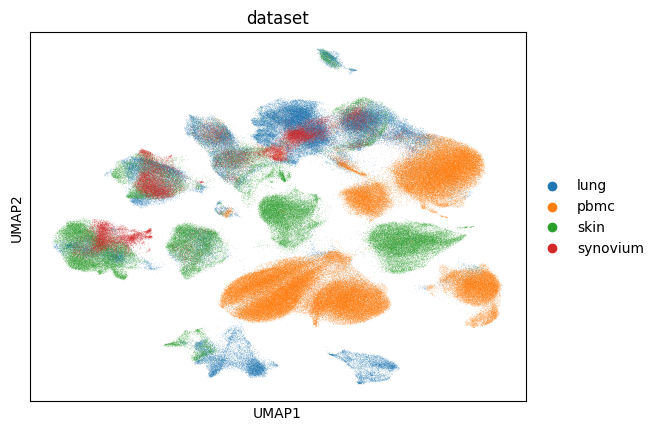

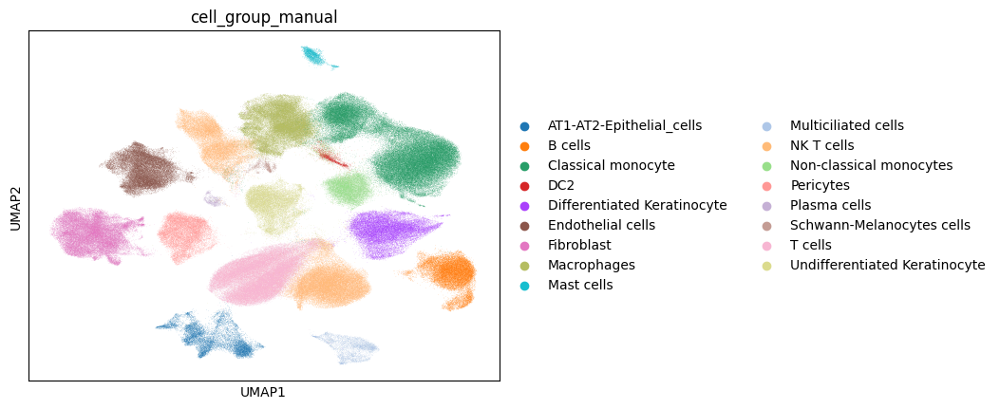

In [3]:
sc.pl.umap(adata_all, color=['dataset'])
sc.pl.umap(adata_all, color=['cell_group_manual'])


In [4]:
import numpy as np
import pandas as pd
import scanpy as sc
import random

np.random.seed(0)
random.seed(0)



#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_Atlas_clean_all_V6.h5ad")
#adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_Atlas_clean_all_V6.h5ad")

In [5]:
adata_all.obs

,sample,Condition,cell_group_manual,leiden_global,Organism,University,Age,Sex,Sequencer,chemistry,...,geo_accession,seurat_clusters,cell_type_celltypist,orig_index,tissue,dataset,apoptosis_score,stress_score,cell_group_lineage,decontX_contamination
GSE128169_SC109SSCUP_SC109SSCUP_1,SC109SSCUP,SSC,Classical monocyte,0,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,Classical monocytes,NaN,lung,lung,-0.140000,6.134343,Myeloid cells,0.012835
GSE128169_SC109SSCUP_SC109SSCUP_2,SC109SSCUP,SSC,Macrophages,2,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,Classical monocytes,NaN,lung,lung,0.975556,11.032323,Myeloid cells,0.007324
GSE128169_SC109SSCUP_SC109SSCUP_3,SC109SSCUP,SSC,AT1-AT2-Epithelial_cells,6,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,AT2,NaN,lung,lung,-0.128889,0.228283,Epithelial cells,0.005595
GSE128169_SC109SSCUP_SC109SSCUP_4,SC109SSCUP,SSC,Multiciliated cells,7,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,Multiciliated,NaN,lung,lung,0.024444,-0.080808,Epithelial cells,0.049414
GSE128169_SC109SSCUP_SC109SSCUP_5,SC109SSCUP,SSC,Macrophages,2,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,Classical monocytes,NaN,lung,lung,0.502222,-0.670707,Myeloid cells,0.082853
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSE00000_SB-095_SB-095_SB-095_TTTGGTTAGCACTCTA-1-GSE00000,SB-095,SSC,Macrophages,2,Homo sapiens,University of Zurich,58.0,Male,Illumina NovaSeq 6000,missing,...,nan,2.0,M1: MERTK+ SELENOP+ macrophages,SB-095_TTTGGTTAGCACTCTA-1-GSE00000,synovium,synovium,0.264444,7.011111,Myeloid cells,0.135197
GSE00000_SB-095_SB-095_SB-095_TTTGGTTGTCGTGATT-1-GSE00000,SB-095,SSC,Endothelial cells,11,Homo sapiens,University of Zurich,58.0,Male,Illumina NovaSeq 6000,missing,...,nan,0.0,E1: ICAM1+ venous,SB-095_TTTGGTTGTCGTGATT-1-GSE00000,synovium,synovium,-0.682222,0.909091,Endothelial cells,0.030557
GSE00000_SB-095_SB-095_SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,SB-095,SSC,Macrophages,2,Homo sapiens,University of Zurich,58.0,Male,Illumina NovaSeq 6000,missing,...,nan,0.0,M0: MERTK+ TIMD4+ macrophages,SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,synovium,synovium,1.300000,6.116162,Myeloid cells,0.123813
GSE00000_SB-095_SB-095_SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,SB-095,SSC,Macrophages,2,Homo sapiens,University of Zurich,58.0,Male,Illumina NovaSeq 6000,missing,...,nan,1.0,M1: MERTK+ SELENOP+ macrophages,SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,synovium,synovium,0.333333,2.260606,Myeloid cells,0.242589


In [6]:
# Define the categories you want to keep
fibroblast_labels = ['T cells', 'NK T cells', 'B cells']

# Subset the AnnData object
#adata_query = adata_query[adata_query.obs['leiden_r0.1'].isin(fibroblast_labels)].copy()
adata_all = adata_all[adata_all.obs['cell_group_manual'].isin(fibroblast_labels)].copy()

NORMALIZATION COMPARABILITY CHECK

[1/6] Loading dataset...
✓ Loaded: 133,703 cells × 22,446 genes
  Batches: ['E-GEAD-872', 'GSE00000', 'GSE128169', 'GSE138669', 'GSE209635', 'GSE212109']

[3/6] Comparing value distributions across batches...
  (Using ALL cells - no subsampling)
  Processing E-GEAD-872: 109,734 cells...
  Processing GSE00000: 3,254 cells...
  Processing GSE128169: 8,172 cells...
  Processing GSE138669: 3,896 cells...
  Processing GSE209635: 1,776 cells...
  Processing GSE212109: 6,871 cells...
     (Distributions should look similar if normalization worked)


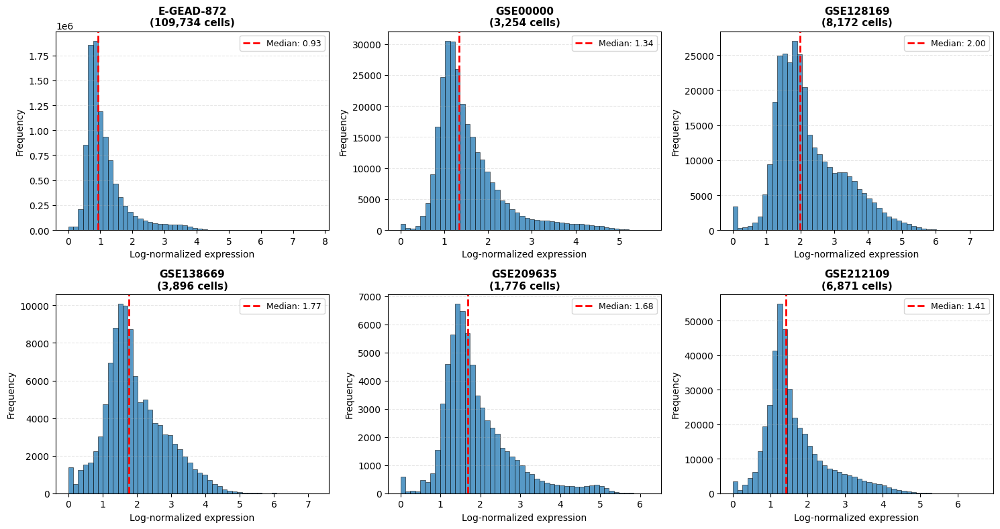

In [7]:

import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations


# ═══════════════════════════════════════════════════════════
# CONFIGURAZIONE
# ═══════════════════════════════════════════════════════════
BATCH_KEY = "batch"
CELLTYPE_KEY = "cell_group"

print("="*70)
print("NORMALIZATION COMPARABILITY CHECK")
print("="*70)

# ═══════════════════════════════════════════════════════════
# 1. CARICA DATI
# ═══════════════════════════════════════════════════════════

print("\n[1/6] Loading dataset...")
# Assume adata_all already loaded
print(f"✓ Loaded: {adata_all.n_obs:,} cells × {adata_all.n_vars:,} genes")

batches = sorted(adata_all.obs[BATCH_KEY].unique())
print(f"  Batches: {batches}")



print("\n[3/6] Comparing value distributions across batches...")
print("  (Using ALL cells - no subsampling)")

# Calculate grid layout
n_batches = len(batches)
n_cols = min(3, n_batches)
n_rows = int(np.ceil(n_batches / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))
if n_batches == 1:
    axes = np.array([axes])
axes = axes.flatten()

for idx, batch in enumerate(batches):
    mask = adata_all.obs[BATCH_KEY] == batch
    batch_data = adata_all[mask]
    
    print(f"  Processing {batch}: {batch_data.n_obs:,} cells...")
    
    # Extract ALL values (no subsampling)
    if hasattr(batch_data.X, 'toarray'):
        # Sparse matrix - sample genes to avoid memory issues
        # Take all cells but sample 1000 random genes
        n_genes_sample = min(1000, batch_data.n_vars)
        gene_idx = np.random.choice(batch_data.n_vars, n_genes_sample, replace=False)
        values = batch_data.X[:, gene_idx].toarray().flatten()
    else:
        # Dense matrix - can handle all
        if batch_data.n_obs * batch_data.n_vars > 10_000_000:
            # Too big - sample
            n_genes_sample = min(1000, batch_data.n_vars)
            gene_idx = np.random.choice(batch_data.n_vars, n_genes_sample, replace=False)
            values = batch_data.X[:, gene_idx].flatten()
        else:
            values = np.array(batch_data.X).flatten()
    
    # Remove zeros for clearer visualization
    values_nonzero = values[values > 0]
    
    # Plot histogram
    axes[idx].hist(values_nonzero, bins=50, alpha=0.75, edgecolor='black', linewidth=0.5)
    axes[idx].axvline(np.median(values_nonzero), color='red', linestyle='--', 
                      linewidth=2, label=f'Median: {np.median(values_nonzero):.2f}')
    
    axes[idx].set_title(f"{batch}\n({batch_data.n_obs:,} cells)", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Log-normalized expression", fontsize=10)
    axes[idx].set_ylabel("Frequency", fontsize=10)
    axes[idx].legend(fontsize=9)
    axes[idx].grid(axis='y', alpha=0.3, linestyle='--')

# Hide empty subplots
for idx in range(n_batches, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
print("     (Distributions should look similar if normalization worked)")
#plt.close()

In [8]:
import pandas as pd

obs = adata_all.obs

# Number of unique patients per batch
patients_per_batch = obs.groupby("batch")["sample"].nunique()

# Number of unique patients per batch *and condition*
patients_condition = (
    obs.groupby(["batch", "Condition"])["sample"]
       .nunique()
       .unstack(fill_value=0)
)
# Rinomina le colonne per chiarezza
patients_condition.columns = [f"n_patients_{col}" for col in patients_condition.columns]

# Number of cells per batch
cells_per_batch = obs["batch"].value_counts().sort_index()

# Tissues represented in each batch
tissues_per_batch = obs.groupby("batch")["tissue"].unique()

# List of patient IDs per batch
patients_list = obs.groupby("batch")["sample"].unique()

# Combine everything into a single summary table
summary = pd.DataFrame({
    "n_patients_total": patients_per_batch,
    "n_cells": cells_per_batch,
    "tissues": tissues_per_batch,
    "patient_ids": patients_list
})

# Aggiungi per-condition patient counts
summary = pd.concat([summary, patients_condition], axis=1)

print(summary)

            n_patients_total  n_cells  \
batch                                   
E-GEAD-872                27   109734   
GSE00000                   9     3254   
GSE128169                 13     8172   
GSE138669                 22     3896   
GSE209635                 15     1776   
GSE212109                  9     6871   

                                                      tissues  \
batch                                                           
E-GEAD-872  ['pbmc']
Categories (4, object): ['lung', 'pbm...   
GSE00000    ['synovium']
Categories (4, object): ['lung', ...   
GSE128169   ['lung']
Categories (4, object): ['lung', 'pbm...   
GSE138669   ['skin']
Categories (4, object): ['lung', 'pbm...   
GSE209635   ['skin']
Categories (4, object): ['lung', 'pbm...   
GSE212109   ['lung']
Categories (4, object): ['lung', 'pbm...   

                                                  patient_ids  \
batch                                                           
E-GEAD-872  ['HD5', 

/tmp/ipykernel_1968172/196286925.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patients_per_batch = obs.groupby("batch")["sample"].nunique()
/tmp/ipykernel_1968172/196286925.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs.groupby(["batch", "Condition"])["sample"]
/tmp/ipykernel_1968172/196286925.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tissues_per_batch = obs.groupby("batch")["tissue"].unique()

In [9]:
adata_all

AnnData object with n_obs × n_vars = 133703 × 22446
    obs: 'sample', 'Condition', 'cell_group_manual', 'leiden_global', 'Organism', 'University', 'Age', 'Sex', 'Sequencer', 'chemistry', 'treatment', 'disease_years', 'localisation', 'pathotype', 'krenn_score', 'fibrosis', 'autoantibodies', 'Cell_Phase', 'n_genes', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'seurat_clusters', 'cell_type_celltypist', 'orig_index', 'tissue', 'dataset', 'apoptosis_score', 'stress_score', 'cell_group_lineage', 'decontX_contamination'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'Condition_colors', 'cell_group_colors', 'cell_group_leiden_colors', 'cell_group_manual_colors', 'cell_type_colors', 'dataset_colors', 'excluded_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'

In [10]:
adata_all.obs["cell_group_manual"].unique()

['NK T cells', 'B cells', 'T cells']
Categories (3, object): ['B cells', 'NK T cells', 'T cells']

In [11]:
# --- 4) Highly Variable Genes ---
sc.pp.highly_variable_genes(adata_all, flavor="seurat", n_top_genes=1000)

# DO NOT subset the object
# adata_all = adata_all[:, adata_all.var["highly_variable"]].copy()   

# --- 5) PCA using only HVGs ---
sc.tl.pca(adata_all, use_highly_variable=True, svd_solver="arpack")

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/scanpy/preprocessing/_simple.py:667: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff
/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/scanpy/preprocessing/_simple.py:667: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff


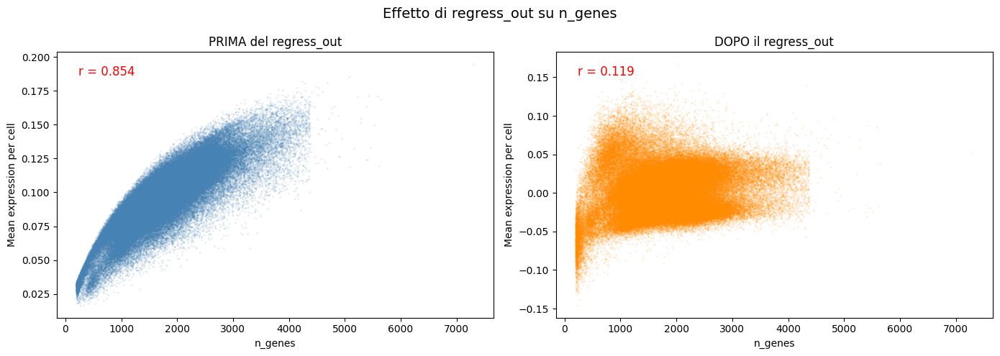

n_genes — Correlazione PRIMA: 0.8542 | DOPO: 0.1193


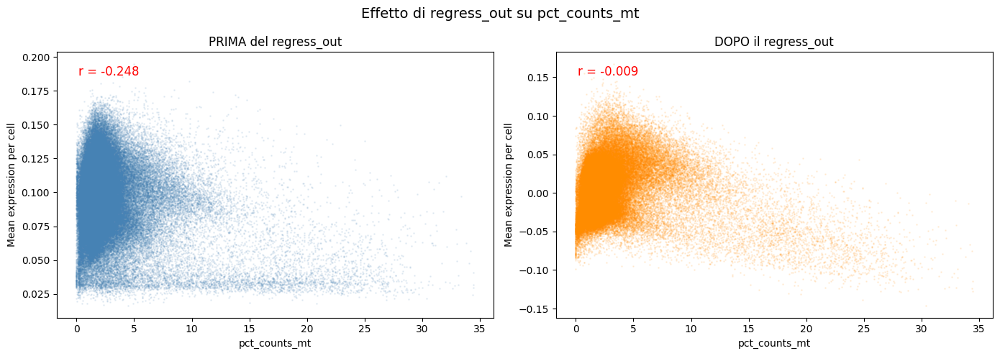

pct_counts_mt — Correlazione PRIMA: -0.2483 | DOPO: -0.0087


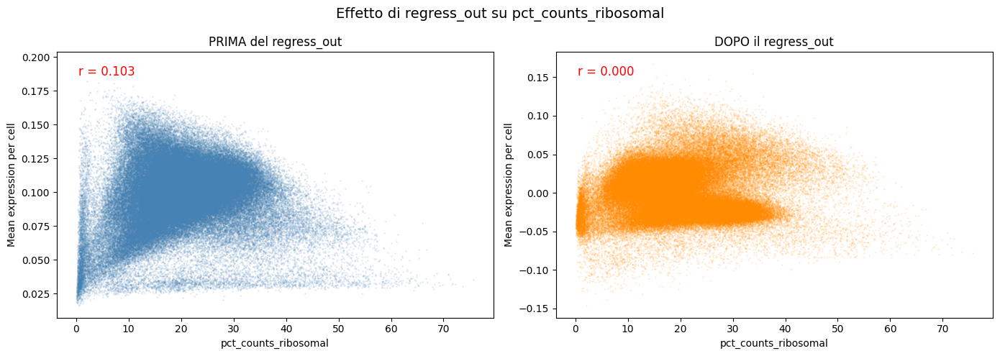

pct_counts_ribosomal — Correlazione PRIMA: 0.1028 | DOPO: 0.0000


2026-09-24 07:40:47,049 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...



Correlazione n_genes vs PC1: -0.1036 | PC2: 0.1032

Correlazione pct_counts_mt vs PC1: -0.0245 | PC2: 0.0166

Correlazione pct_counts_ribosomal vs PC1: 0.0000 | PC2: 0.0000


2026-09-24 07:41:03,992 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-09-24 07:41:06,232 - harmonypy - INFO - Iteration 1 of 25
2026-09-24 07:46:50,501 - harmonypy - INFO - Iteration 2 of 25
2026-09-24 07:53:08,892 - harmonypy - INFO - Iteration 3 of 25
2026-09-24 07:58:54,382 - harmonypy - INFO - Iteration 4 of 25
2026-09-24 08:05:07,700 - harmonypy - INFO - Iteration 5 of 25
2026-09-24 08:10:55,852 - harmonypy - INFO - Iteration 6 of 25
2026-09-24 08:17:09,210 - harmonypy - INFO - Iteration 7 of 25
2026-09-24 08:23:26,163 - harmonypy - INFO - Iteration 8 of 25
2026-09-24 08:29:07,131 - harmonypy - INFO - Iteration 9 of 25
2026-09-24 08:34:50,475 - harmonypy - INFO - Iteration 10 of 25
2026-09-24 08:39:14,994 - harmonypy - INFO - Iteration 11 of 25
2026-09-24 08:43:45,332 - harmonypy - INFO - Iteration 12 of 25
2026-09-24 08:49:26,631 - harmonypy - INFO - Iteration 13 of 25
2026-09-24 08:53:52,795 - harmonypy - INFO - Iteration 14 of 25
2026-09-24 08:58:21,668 - ha

In [12]:
import scanpy as sc
import scanpy.external as sce
import matplotlib.pyplot as plt
import numpy as np

# ── SUBSET HVG ───────────────────────────────────────────────────────────────
adata_all_hvg = adata_all[:, adata_all.var["highly_variable"]].copy()

# ── REGRESS OUT ───────────────────────────────────────────────────────────────
sc.pp.regress_out(adata_all_hvg, ["n_genes"])
sc.pp.regress_out(adata_all_hvg, ["pct_counts_mt"])
sc.pp.regress_out(adata_all_hvg, ["pct_counts_ribosomal"])

# ── VALORI PRE/POST ───────────────────────────────────────────────────────────
mean_expr_before = np.array(adata_all.X.mean(axis=1)).flatten()
mean_expr_after  = np.array(adata_all_hvg.X.mean(axis=1)).flatten()

n_genes          = adata_all_hvg.obs["n_genes"].values
pct_counts_mt    = adata_all_hvg.obs["pct_counts_mt"].values
pct_counts_rb    = adata_all_hvg.obs["pct_counts_ribosomal"].values

# ── FUNZIONE HELPER ───────────────────────────────────────────────────────────
def plot_regress_validation(var_values, var_name, before, after):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # nuova figura ogni volta

    corr_before = np.corrcoef(var_values, before)[0, 1]
    corr_after  = np.corrcoef(var_values, after)[0, 1]

    axes[0].scatter(var_values, before, alpha=0.1, s=1, color="steelblue")
    axes[0].set_xlabel(var_name)
    axes[0].set_ylabel("Mean expression per cell")
    axes[0].set_title("PRIMA del regress_out")
    axes[0].text(0.05, 0.95, f"r = {corr_before:.3f}", transform=axes[0].transAxes,
                 fontsize=12, color="red", va="top")

    axes[1].scatter(var_values, after, alpha=0.1, s=1, color="darkorange")
    axes[1].set_xlabel(var_name)
    axes[1].set_ylabel("Mean expression per cell")
    axes[1].set_title("DOPO il regress_out")
    axes[1].text(0.05, 0.95, f"r = {corr_after:.3f}", transform=axes[1].transAxes,
                 fontsize=12, color="red", va="top")

    plt.suptitle(f"Effetto di regress_out su {var_name}", fontsize=14)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

    print(f"{var_name} — Correlazione PRIMA: {corr_before:.4f} | DOPO: {corr_after:.4f}")

# ── PLOT ──────────────────────────────────────────────────────────────────────
plot_regress_validation(n_genes,       "n_genes",            mean_expr_before, mean_expr_after)
plot_regress_validation(pct_counts_mt, "pct_counts_mt",      mean_expr_before, mean_expr_after)
plot_regress_validation(pct_counts_rb, "pct_counts_ribosomal", mean_expr_before, mean_expr_after)

# ── PCA ───────────────────────────────────────────────────────────────────────
sc.tl.pca(adata_all_hvg, svd_solver="arpack")

for var_values, var_name in [
    (n_genes,       "n_genes"),
    (pct_counts_mt, "pct_counts_mt"),
    (pct_counts_rb, "pct_counts_ribosomal"),
]:
    corr_pc1 = np.corrcoef(var_values, adata_all_hvg.obsm["X_pca"][:, 0])[0, 1]
    corr_pc2 = np.corrcoef(var_values, adata_all_hvg.obsm["X_pca"][:, 1])[0, 1]
    print(f"\nCorrelazione {var_name} vs PC1: {corr_pc1:.4f} | PC2: {corr_pc2:.4f}")

# ── HARMONY + UMAP ───────────────────────────────────────────────────────────
sce.pp.harmony_integrate(adata_all_hvg, "sample", max_iter_harmony=25)
sc.pp.neighbors(adata_all_hvg, use_rep="X_pca_harmony", n_neighbors=15)
sc.tl.umap(adata_all_hvg)

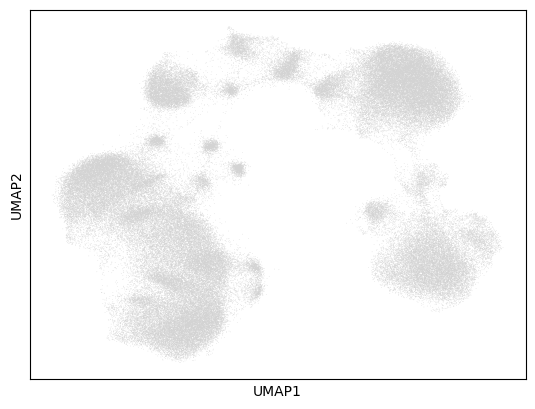

✅ Harmony integration completed and UMAP computed!


In [13]:
# --- 7) Recompute neighbors + UMAP using Harmony embedding ---
#sc.pp.neighbors(adata_all, use_rep="X_pca_harmony", n_neighbors=15, n_pcs=50)
#sc.tl.umap(adata_all)
sc.pl.umap(adata_all_hvg)
# --- 8) Save the integrated object ---
#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Integrated_SSC_Harmony.h5ad")

print("✅ Harmony integration completed and UMAP computed!")

In [14]:
sc.tl.leiden(
    adata_all_hvg,
    resolution=0.4,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,
    key_added="Lymphocytes_subpopulation" 
) #Using igraph as flavor there is currently a bug on windows system that block freeze R.

In [15]:
# Trasferisci l'UMAP da fib_hvg a fib
adata_all.obsm["X_umap"] = adata_all_hvg.obsm["X_umap"]
adata_all.obsm["X_pca_harmony"] = adata_all_hvg.obsm["X_pca_harmony"]

['0', '3', '2', '1', '4', '5', '6', '7', '8', '9']
Categories (10, object): ['0', '1', '2', '3', ..., '6', '7', '8', '9']


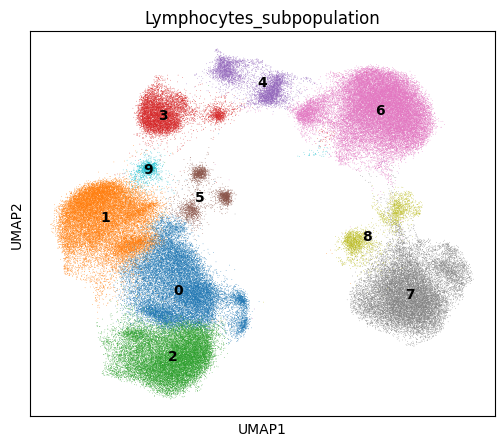

In [49]:
print(adata_all_hvg.obs['Lymphocytes_subpopulation'].unique())
sc.pl.umap(adata_all_hvg, color='Lymphocytes_subpopulation', legend_loc='on data')
adata_all.obs["Lymphocytes_subpopulation"] = adata_all_hvg.obs["Lymphocytes_subpopulation"]

In [50]:
# Salva l'assegnazione cluster con l'indice (cell barcode) per riuso futuro
# senza dover rifare l'intero pipeline di integrazione/clustering
Lymphocytes_subpop_export = adata_all.obs[['Lymphocytes_subpopulation']].copy()
Lymphocytes_subpop_export.index.name = 'cell_id'
Lymphocytes_subpop_export.to_csv('Lymphocytes_subpopulation_assignment.csv')

In [51]:
CLUSTER_MAP = {
    "0":  "NK_T_Cells_GNLY_NKG7_GZMB",      # NK con markers T (CD8+)
    "1":  "CD4_Naive_T_Cells",               # unito con 3, 6, 9
    "2":  "NK_Cells_GNLY_NKG7",             # NK pure senza markers T
    "3":  "CD4_Naive_T_Cells",               # unito con 1, 6, 9
    "4":  "CD8_Naive_T_NK_Cells",           # CD8 naive + NK T cells
    "5":  "CD8_Naive_T_Cells",              # unito con 4 parzialmente — kept separate per il profilo NK
    "6":  "CD4_Naive_T_Cells",               # unito con 1, 3, 9
    "7":  "Naive_B_Cells_IGHD",             # IGHD+
    "8":  "Memory_B_Cells_BANK1",           # BANK1+ IGHD-
    "9":  "CD4_Naive_T_Cells",               # unito con 1, 3, 6
}

adata_all.obs["Lymphocytes_subpopulation"] = (
    adata_all.obs["Lymphocytes_subpopulation"]
    .astype(str)
    .map(CLUSTER_MAP)
    .fillna("Unknown")
    .astype("category")
)

print(adata_all.obs["Lymphocytes_subpopulation"].value_counts())

Lymphocytes_subpopulation
CD4_Naive_T_Cells            64451
NK_T_Cells_GNLY_NKG7_GZMB    21512
NK_Cells_GNLY_NKG7           19134
Naive_B_Cells_IGHD           17746
CD8_Naive_T_NK_Cells          5160
Memory_B_Cells_BANK1          2854
CD8_Naive_T_Cells             2846
Name: count, dtype: int64


In [6]:
OLD_TO_NEW_LYMPHOID_LABELS = {
    "NK_T_Cells_GNLY_NKG7_GZMB": "Pan_NKT_GNLY_GZMB",
    "CD4_Naive_T_Cells":         "Pan_NaiveCD4T",
    "NK_Cells_GNLY_NKG7":        "Pan_NK_GNLY_NKG7",
    "CD8_Naive_T_NK_Cells":      "Mixed_NaiveCD8T_NK",
    "CD8_Naive_T_Cells":         "Pan_NaiveCD8T",
    "Naive_B_Cells_IGHD":        "Pan_NaiveB_IGHD",
    "Memory_B_Cells_BANK1":      "Pan_MemoryB_BANK1",
}

current = adata_all.obs["Lymphocytes_subpopulation"].astype(str)

# Segnala eventuali valori presenti nell'oggetto non coperti dal mapping
# (es. "Unknown" residuo, refusi, categorie che non ricordavi più)
unmapped = sorted(set(current.unique()) - set(OLD_TO_NEW_LYMPHOID_LABELS))
if unmapped:
    print(f"Attenzione: valori non coperti dal mapping (resteranno invariati): {unmapped}")

adata_all.obs["Lymphocytes_subpopulation"] = (
    current.map(OLD_TO_NEW_LYMPHOID_LABELS)
    .fillna(current)          # <-- a differenza di .fillna("Unknown"): se un valore
                              #     non è nel mapping, lo lascia com'era invece di
                              #     cancellarlo, per non perdere dati silenziosamente
    .astype("category")
)

print(adata_all.obs["Lymphocytes_subpopulation"].value_counts())

Lymphocytes_subpopulation
Pan_NaiveCD4T         64451
Pan_NKT_GNLY_GZMB     21512
Pan_NK_GNLY_NKG7      19134
Pan_NaiveB_IGHD       17746
Mixed_NaiveCD8T_NK     5160
Pan_MemoryB_BANK1      2854
Pan_NaiveCD8T          2846
Name: count, dtype: int64


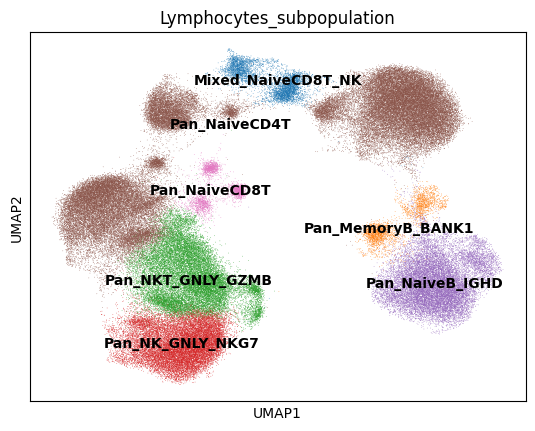

In [7]:
sc.pl.umap(adata_all, color='Lymphocytes_subpopulation', legend_loc='on data')


In [1]:

import numpy as np
import pandas as pd
import scanpy as sc
import random


np.random.seed(0)
random.seed(0)


#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_lymphocytes.h5ad")
adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_lymphocytes.h5ad")

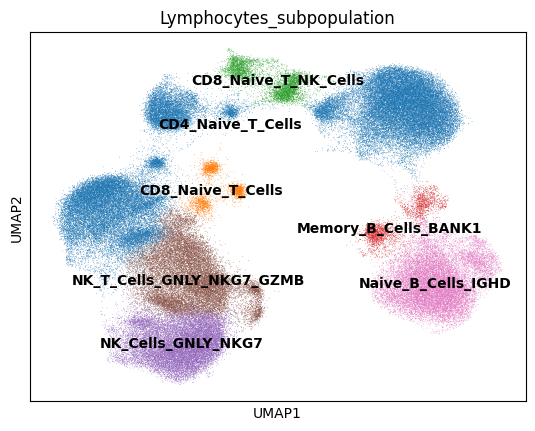

In [5]:
sc.pl.umap(adata_all, color='Lymphocytes_subpopulation', legend_loc='on data')



In [54]:
# Sul cluster 0 (o sull'oggetto lymphoid subclustered)
import scanpy as sc

# Sottoinsieme al cluster 0
adata_c0 = adata_all[adata_all.obs['Lymphocytes_subpopulation'] == '0']

# Media di espressione (o score aggregato) delle cheratine, stratificata per tessuto
keratin_genes = ['KRT1','KRT2','KRT5','KRT6A','KRT10','KRT14','KRT16','KRT17','FLG','IVL','SPRR1A','SPRR1B']
keratin_genes_present = [g for g in keratin_genes if g in adata_c0.var_names]

sc.tl.score_genes(adata_c0, keratin_genes_present, score_name='keratin_score')

# Confronta la distribuzione per tessuto
adata_c0.obs.groupby('tissue')['keratin_score'].describe()

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/scanpy/tools/_score_genes.py:50: RuntimeWarning: invalid value encountered in divide
  m = s / n_elements


KeyError: "None of [Index(['KRT1', 'KRT2', 'KRT5', 'KRT6A', 'KRT10', 'KRT14', 'KRT16', 'KRT17',\n       'FLG', 'IVL', 'SPRR1A', 'SPRR1B'],\n      dtype='object')] are in the [index]"

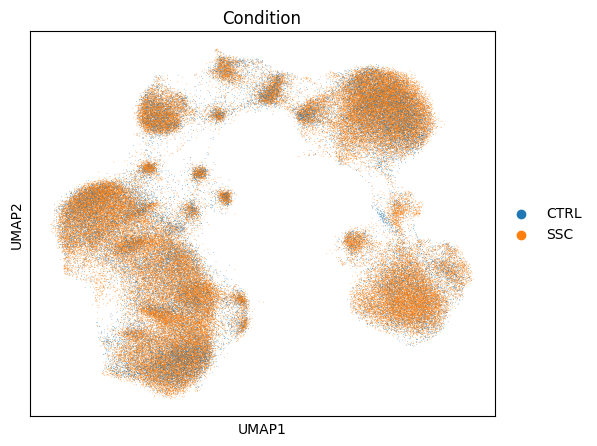

In [55]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (6, 5)  # larghezza, altezza in pollici
sc.pl.umap(adata_all, color=['Condition'])

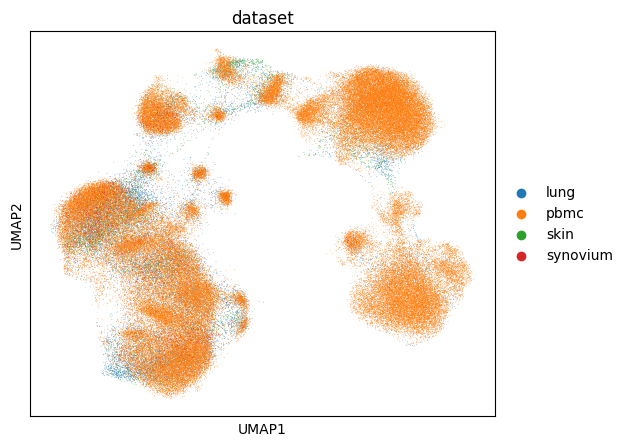

In [56]:
sc.pl.umap(adata_all, color=['dataset'])
# Palette con 3 colori ben distinti e leggibili anche in stampa/daltonismo

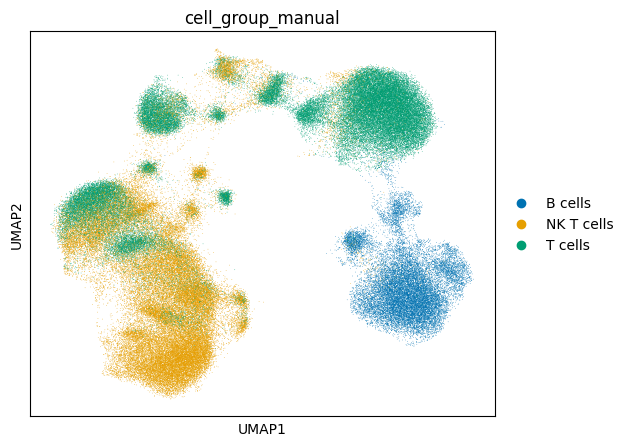

In [57]:
custom_colors = ["#0072B2", "#E69F00", "#009E73"]  # blu / arancio / verde

sc.pl.umap(
    adata_all,
    color=['cell_group_manual'],
    palette=custom_colors,
    show=False,
)
plt.show()

In [58]:
%matplotlib inline

In [59]:
adata_all

AnnData object with n_obs × n_vars = 133703 × 22446
    obs: 'sample', 'Condition', 'cell_group_manual', 'leiden_global', 'Organism', 'University', 'Age', 'Sex', 'Sequencer', 'chemistry', 'treatment', 'disease_years', 'localisation', 'pathotype', 'krenn_score', 'fibrosis', 'autoantibodies', 'Cell_Phase', 'n_genes', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'seurat_clusters', 'cell_type_celltypist', 'orig_index', 'tissue', 'dataset', 'apoptosis_score', 'stress_score', 'cell_group_lineage', 'decontX_contamination', 'Lymphocytes_subpopulation', 'ambient_score', 'Lymphoid_annotation'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'Condition_colors', 'cell_group_colors', 'cell_group_leiden_colors', 'cell_group_manual_colors', 'cell_type_colors', 'dataset_colors', 'excluded_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'sample_colors'

/tmp/ipykernel_1968172/2426153125.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df.groupby(['sample', 'Lymphocytes_subpopulation']).size().reset_index(name='count')


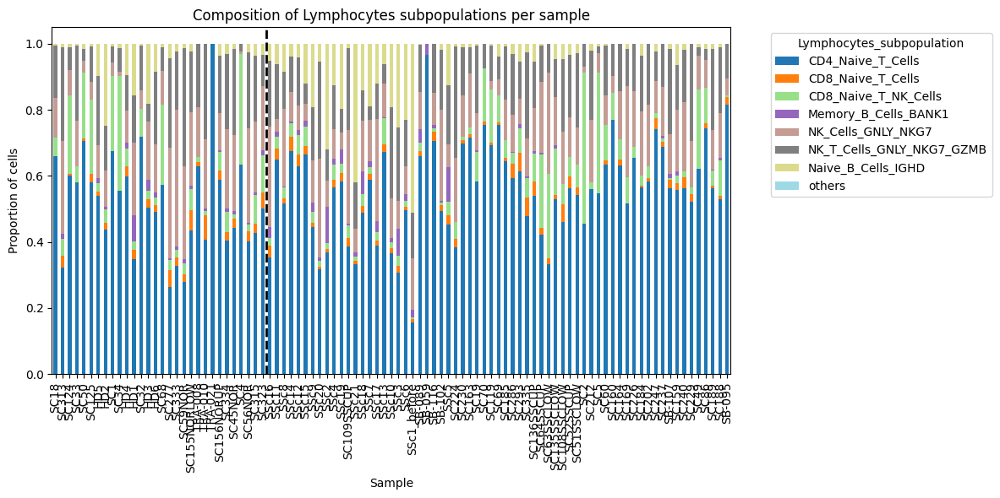

In [60]:
import pandas as pd
import matplotlib.pyplot as plt

df = adata_all.obs[['sample', 'Lymphocytes_subpopulation', 'Condition']].copy()
df['Lymphocytes_subpopulation'] = df['Lymphocytes_subpopulation'].astype('category')
df['Lymphocytes_subpopulation'] = df['Lymphocytes_subpopulation'].cat.add_categories('others')
df['Lymphocytes_subpopulation'] = df['Lymphocytes_subpopulation'].fillna('others')

counts = df.groupby(['sample', 'Lymphocytes_subpopulation']).size().reset_index(name='count')
counts_pivot = counts.pivot(index='sample', columns='Lymphocytes_subpopulation', values='count').fillna(0)
counts_prop = counts_pivot.div(counts_pivot.sum(axis=1), axis=0)

# --- Unica aggiunta: ordina per condizione ---
sample_condition = df[['sample', 'Condition']].drop_duplicates().set_index('sample')
counts_prop = counts_prop.loc[sample_condition.sort_values('Condition').index]

# Plot
ax = counts_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    colormap='tab20'
)

# --- Linea verticale per separare le condizioni ---
condition_sizes = sample_condition.sort_values('Condition')['Condition'].value_counts(sort=False)
split = condition_sizes.iloc[0]  # numero di campioni della prima condizione
ax.axvline(x=split - 0.5, color='black', linewidth=2, linestyle='--')

plt.ylabel('Proportion of cells')
plt.xlabel('Sample')
plt.title('Composition of Lymphocytes subpopulations per sample')
plt.legend(title='Lymphocytes_subpopulation', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Saved: Figures/Lymphocytes_composition_by_organ.svg


/tmp/ipykernel_1968172/3572067279.py:39: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
/tmp/ipykernel_1968172/3572067279.py:39: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
/tmp/ipykernel_1968172/3572067279.py:39: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  count

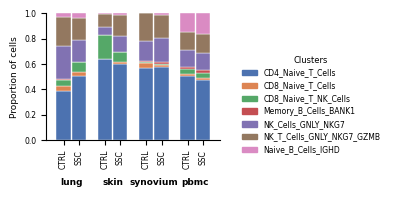

In [61]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Unified palette & order — reuse for Lymphoid, Myeloid, Endothelial, Epithelial ──
SUBPOP_PALETTE = [
    "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2",
    "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD",
]
TISSUE_ORDER    = ["lung", "skin", "synovium", "pbmc"]
CONDITION_ORDER = ["CTRL", "SSC"]


def plot_condition_composition_by_organ(
    obs_df, subpop_col, tissue_col="Tissue", condition_col="Condition",
    tissue_order=TISSUE_ORDER, condition_order=CONDITION_ORDER,
    palette=SUBPOP_PALETTE,
    fig_width=4.0, fig_height=2.2,     # <-- modifica qui la dimensione della figura
    bar_width=0.35, group_gap=0.25,    # larghezza barre e spazio tra gruppi tessuto
    title=None,
    save_path=None                    # <-- percorso completo del file da salvare (es. "Figures/fig.svg")
):
    df = obs_df[[condition_col, tissue_col, subpop_col]].copy()
    df[subpop_col] = df[subpop_col].astype("category")
    categories = list(df[subpop_col].cat.categories)
    color_map = {c: palette[i % len(palette)] for i, c in enumerate(categories)}

    tissues = [t for t in tissue_order if t in df[tissue_col].unique()]
    n_cond = len(condition_order)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    group_centers = np.arange(len(tissues))
    offsets = (np.arange(n_cond) - (n_cond - 1) / 2) * (bar_width + 0.02)

    for tissue_idx, tissue in enumerate(tissues):
        sub = df[df[tissue_col] == tissue]
        counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
        counts = counts.reindex(index=[c for c in condition_order if c in counts.index])
        props = counts.div(counts.sum(axis=1), axis=0)

        for cond_idx, cond in enumerate(props.index):
            x = group_centers[tissue_idx] + offsets[cond_idx]
            bottom = 0.0
            for cat in categories:
                if cat not in props.columns:
                    continue
                val = props.loc[cond, cat]
                ax.bar(x, val, bottom=bottom, width=bar_width,
                       color=color_map[cat], edgecolor="white", linewidth=0.3)
                bottom += val

    xtick_pos, xtick_labels = [], []
    for tissue_idx, tissue in enumerate(tissues):
        for cond_idx, cond in enumerate(condition_order):
            xtick_pos.append(group_centers[tissue_idx] + offsets[cond_idx])
            xtick_labels.append(cond)
    ax.set_xticks(xtick_pos)
    ax.set_xticklabels(xtick_labels, fontsize=5.5, rotation=90)

    for tissue_idx, tissue in enumerate(tissues):
        ax.text(group_centers[tissue_idx], -0.30, tissue,
                ha="center", va="top", fontsize=6.5, fontweight="bold",
                transform=ax.get_xaxis_transform())

    ax.set_ylim(0, 1)
    ax.set_ylabel("Proportion of cells", fontsize=6.5)
    ax.tick_params(axis="y", labelsize=5.5)
    ax.set_xlim(group_centers[0] - 0.6, group_centers[-1] + 0.6)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    handles = [plt.Rectangle((0, 0), 1, 1, color=color_map[c]) for c in categories]
    fig.legend(handles, categories, title="Clusters", fontsize=5.5, title_fontsize=6,
               bbox_to_anchor=(1.0, 0.5), loc="center left", frameon=False)

    if title:
        fig.suptitle(title, fontsize=7, y=1.05)

    plt.tight_layout()

    if save_path is not None:
        out_dir = os.path.dirname(save_path)
        if out_dir:
            os.makedirs(out_dir, exist_ok=True)
        fig.savefig(save_path, format="svg", bbox_inches="tight")
        print(f"Saved: {save_path}")

    return fig, ax, color_map


# ── Usage ──────────────────────────────────────────────────────────────────
fig, ax, color_map = plot_condition_composition_by_organ(
    adata_all.obs, subpop_col="Lymphocytes_subpopulation",
    tissue_col="tissue", condition_col="Condition",
    fig_width=2.4, fig_height=2.2,
    save_path="Figures/Lymphocytes_composition_by_organ.svg"
)
plt.show()

/tmp/ipykernel_1968172/1529694169.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df.groupby(['tissue', 'Lymphocytes_subpopulation']).size().reset_index(name='count')


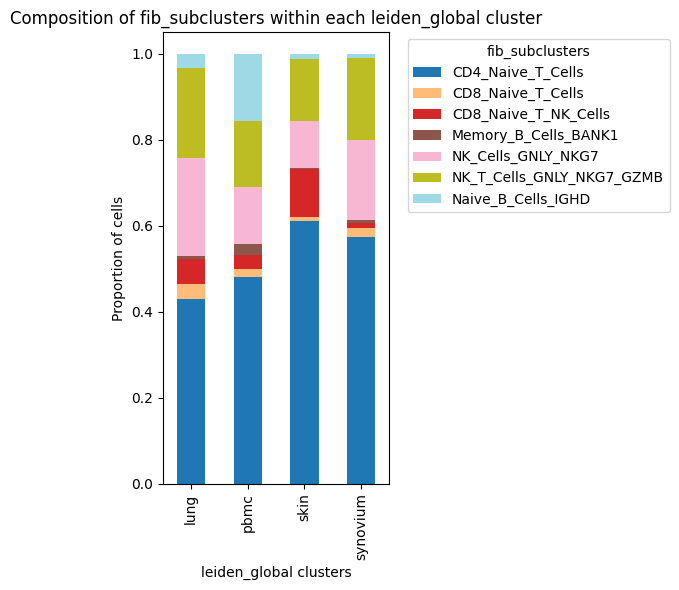

In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Copy relevant columns
df = adata_all.obs[['tissue', 'Lymphocytes_subpopulation']].copy()
# Ensure 'fib_subclusters' is categorical
df['Lymphocytes_subpopulation'] = df['Lymphocytes_subpopulation'].astype('category')
# Add 'others' to the categories
#df['Lymphocytes_subpopulation'] = df['Lymphocytes_subpopulation'].cat.add_categories('others')
# Fill missing values with 'others'
#df['Lymphocytes_subpopulation'] = df['Lymphocytes_subpopulation'].fillna('others')
# Compute counts per cluster
counts = df.groupby(['tissue', 'Lymphocytes_subpopulation']).size().reset_index(name='count')
# Pivot for stacked bar plot
counts_pivot = counts.pivot(index='tissue', columns='Lymphocytes_subpopulation', values='count').fillna(0)
# Optional: convert to proportions
counts_prop = counts_pivot.div(counts_pivot.sum(axis=1), axis=0)
# Plot
counts_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(6,6),
    colormap='tab20'
)
plt.ylabel('Proportion of cells')
plt.xlabel('leiden_global clusters')
plt.title('Composition of fib_subclusters within each leiden_global cluster')
plt.legend(title='fib_subclusters', bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()

/tmp/ipykernel_1968172/1680075739.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df.groupby(['Lymphocytes_subpopulation', 'tissue']).size().reset_index(name='count')


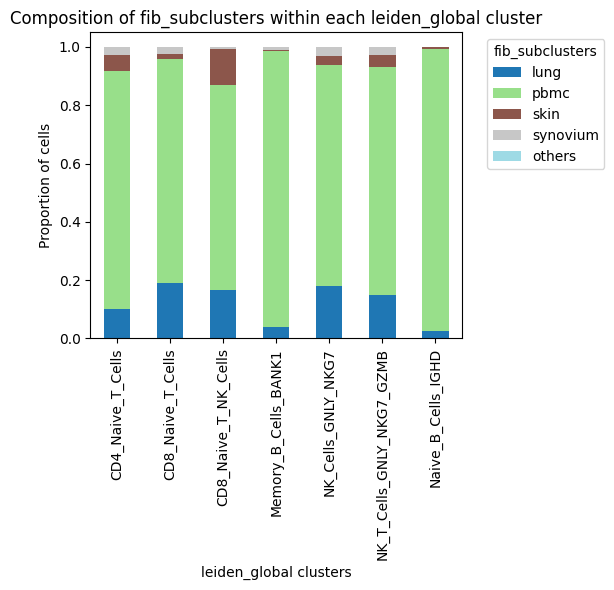

In [63]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
# Copy relevant columns
df = adata_all.obs[['Lymphocytes_subpopulation', 'tissue']].copy()
# Ensure 'fib_subclusters' is categorical
df['tissue'] = df['tissue'].astype('category')
# Add 'others' to the categories
df['tissue'] = df['tissue'].cat.add_categories('others')
# Fill missing values with 'others'
df['tissue'] = df['tissue'].fillna('others')
# Compute counts per cluster
counts = df.groupby(['Lymphocytes_subpopulation', 'tissue']).size().reset_index(name='count')
# Pivot for stacked bar plot
counts_pivot = counts.pivot(index='Lymphocytes_subpopulation', columns='tissue', values='count').fillna(0)
# Optional: convert to proportions
counts_prop = counts_pivot.div(counts_pivot.sum(axis=1), axis=0)
# Plot
counts_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(6,6),
    colormap='tab20'
)
plt.ylabel('Proportion of cells')
plt.xlabel('leiden_global clusters')
plt.title('Composition of fib_subclusters within each leiden_global cluster')
plt.legend(title='fib_subclusters', bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()

Ambient genes trovati: 13/13


<Axes: title={'center': 'Ambient RNA score'}, xlabel='UMAP1', ylabel='UMAP2'>

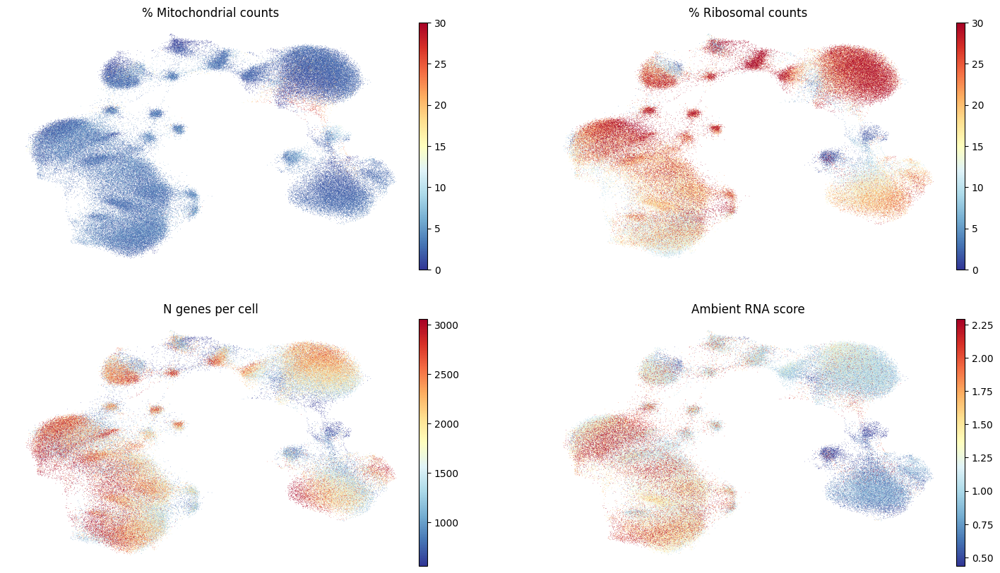

In [64]:
import matplotlib.pyplot as plt
import numpy as np


# ── GENE SIGNATURES ──────────────────────────────────────────────────────────
# Ambient RNA / housekeeping genes — highly expressed in empty droplets
ambient_genes = [
    "MALAT1", "NEAT1",                          # lncRNA ubiqui nell'ambient RNA
    "ACTB", "ACTG1",                            # actina
    "GAPDH", "LDHA",                            # glicolisi
    "B2M",                                      # MHC I ubiquo
    "FTL", "FTH1",                              # ferritina — molto abbondante
    "TMSB4X", "TMSB10",                         # thymosine — ambient marker
    "S100A4", "VIM",                            # proteine strutturali ubique
]

ambient_present = [g for g in ambient_genes if g in adata_all.var_names]
missing = [g for g in ambient_genes if g not in adata_all.var_names]
print(f"Ambient genes trovati: {len(ambient_present)}/{len(ambient_genes)}")
if missing:
    print(f"Mancanti: {missing}")

sc.tl.score_genes(adata_all, ambient_present, score_name="ambient_score")


fig, axes = plt.subplots(2, 2, figsize=(18, 10))


# ── PLOT 2: UMAP % mitocondriale ─────────────────────────────────────────────
sc.pl.umap(
    adata_all,
    color="pct_counts_mt",
    ax=axes[0, 0],
    show=False,
    frameon=False,
    title="% Mitochondrial counts",
    cmap="RdYlBu_r",
    vmin=0,
    vmax=30,
)

# ── PLOT 3: UMAP % ribosomiale ───────────────────────────────────────────────
sc.pl.umap(
    adata_all,
    color="pct_counts_ribosomal",
    ax=axes[0, 1],
    show=False,
    frameon=False,
    title="% Ribosomal counts",
    cmap="RdYlBu_r",
    vmin=0,
    vmax=30,
)

# ── UMAP: n_genes ─────────────────────────────────────────────────────────────
sc.pl.umap(adata_all, color="n_genes",
           ax=axes[1, 0], show=False, frameon=False,
           title="N genes per cell",
           cmap="RdYlBu_r",
           vmin=adata_all.obs["n_genes"].quantile(0.05),
           vmax=adata_all.obs["n_genes"].quantile(0.95))

# ── UMAP: ambient score ───────────────────────────────────────────────────────
sc.pl.umap(adata_all, color="ambient_score",
           ax=axes[1, 1], show=False, frameon=False,
           title="Ambient RNA score",
           cmap="RdYlBu_r",
           vmin=adata_all.obs["ambient_score"].quantile(0.05),
           vmax=adata_all.obs["ambient_score"].quantile(0.95))


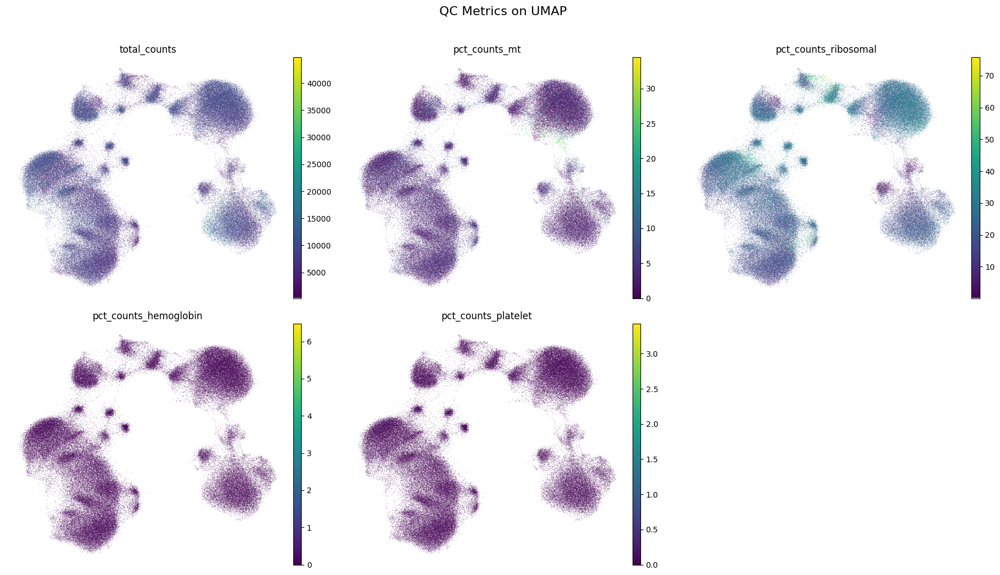

In [65]:
import matplotlib.pyplot as plt
import scanpy as sc

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

variables = ["total_counts", "pct_counts_mt", "pct_counts_ribosomal", 
             "pct_counts_hemoglobin", "pct_counts_platelet"]

for i, var in enumerate(variables):
    sc.pl.umap(
        adata_all,
        color=var,
        ax=axes[i],
        show=False,
        frameon=False,
        title=var
    )

# Rimuovi l'ultimo subplot vuoto
axes[-1].set_visible(False)

plt.suptitle("QC Metrics on UMAP", fontsize=16, y=1.02)
plt.tight_layout()

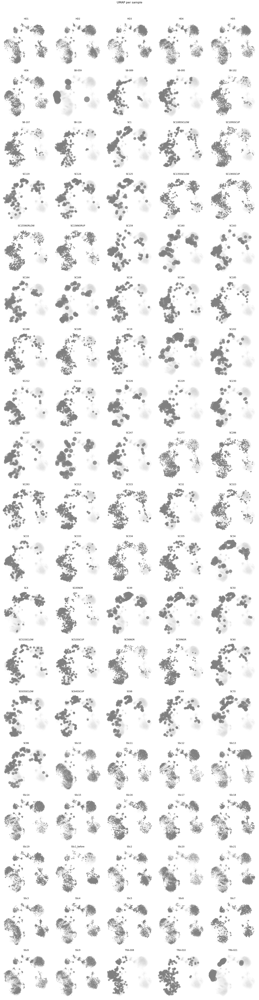

In [66]:
import matplotlib.pyplot as plt
import math

# Rimuovi NaN e converti in stringa
cell_types = sorted(adata_all.obs['sample'].dropna().astype(str).unique())
n = len(cell_types)

# Calcola griglia
ncols = 5
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, batch in enumerate(cell_types):
    adata_batch = adata_all[adata_all.obs['sample'] == batch]
    
    sc.pl.umap(
        adata_all,          # sfondo grigio con tutte le cellule
        color='sample',
        ax=axes[i],
        show=False,
        frameon=False,
        legend_loc=None,
        title=batch,
        na_color="lightgrey",
        alpha=0.1           # tutte le cellule in grigio trasparente
    )
    # Sovrapponi le cellule del batch in evidenza
    sc.pl.umap(
        adata_batch,
        color='sample',
        ax=axes[i],
        show=False,
        frameon=False,
        legend_loc=None,
        title=batch,
        alpha=0.8
    )

# Nascondi i subplot vuoti
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("UMAP per sample", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

In [5]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 2000
groupby = "Lymphocytes_subpopulation"

# Usa indici numerici invece dei nomi dei barcodes
subsampled_idx = []

for cell_type, indices in adata_all.obs.groupby(groupby).groups.items():
    # Converti i nomi in posizioni numeriche
    positions = np.where(adata_all.obs.index.isin(indices))[0]
    n_cells = len(positions)
    
    if n_cells <= min_keep:
        chosen = positions
    else:
        chosen = np.random.choice(positions, size=min_keep, replace=False)
    
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Usa iloc-style indexing con indici numerici
adata_sub = adata_all[np.array(subsampled_idx), :].copy()

print(f"\nTotal cells before: {adata_all.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")

/tmp/ipykernel_1666055/4033085571.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for cell_type, indices in adata_all.obs.groupby(groupby).groups.items():


Mixed_NaiveCD8T_NK   → kept 2000 / 5160 cells
Pan_MemoryB_BANK1    → kept 2000 / 2854 cells
Pan_NKT_GNLY_GZMB    → kept 2000 / 21512 cells
Pan_NK_GNLY_NKG7     → kept 2000 / 19134 cells
Pan_NaiveB_IGHD      → kept 2000 / 17746 cells
Pan_NaiveCD4T        → kept 2000 / 64451 cells
Pan_NaiveCD8T        → kept 2000 / 2846 cells

Total cells before: 133703
Total cells after subsampling: 14000


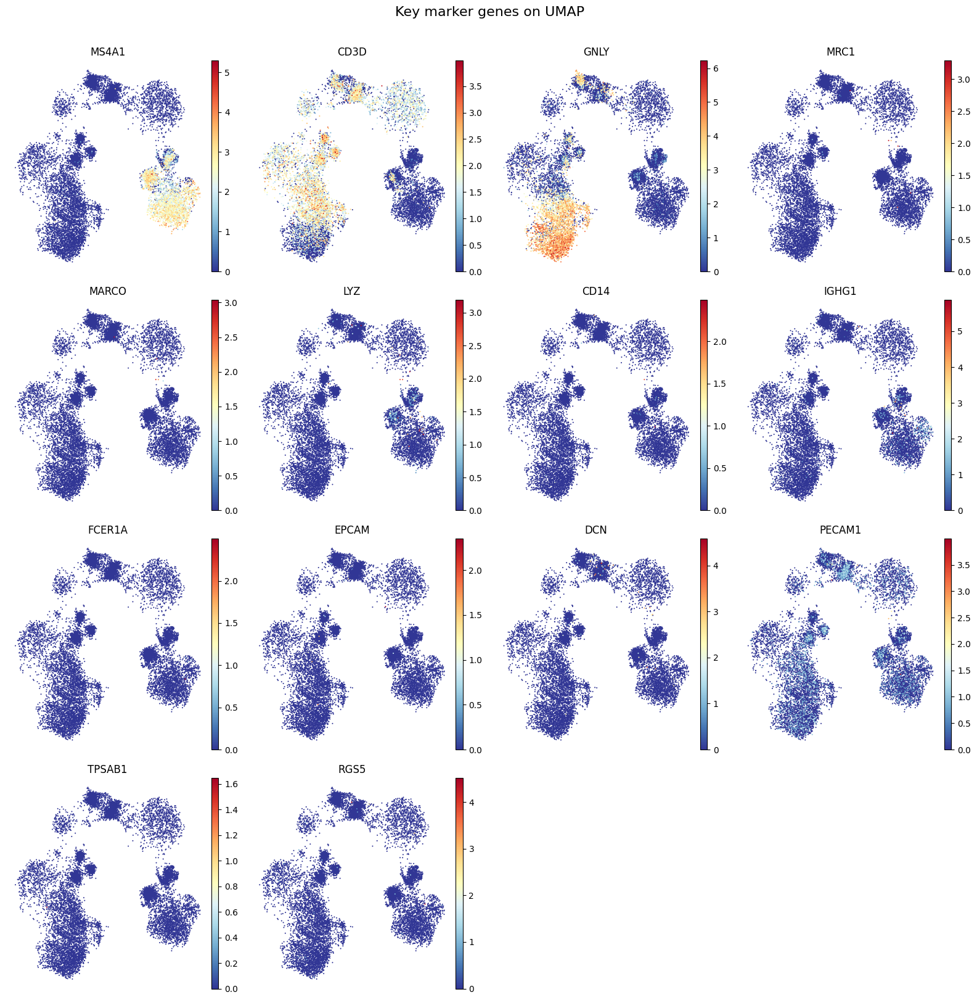

In [68]:
import matplotlib.pyplot as plt
import math

markers = {
    "B cells":       ["MS4A1"],           # CD20 — canonico e universale
    "T cells":       ["CD3D"],            # CD3 — pan-T
    "NK cells":      ["GNLY"],            # granulisina — pan-NK
    "Macrophages":   ["MRC1", "MARCO"],   # CD206 — pan-macrofagi
    "Monocytes":     ["LYZ", "CD14"],     # pan-monociti
    "Plasma cells":  ["IGHG1"],           # immunoglobulina — plasma cells
    "DC":            ["FCER1A"],          # recettore IgE — DC2/pan-DC
    "Epithelial":    ["EPCAM"],           # pan-epiteliale
    "Fibroblasts":   ["DCN"],             # decorina — pan-fibroblasti
    "Endothelial":   ["PECAM1"],          # CD31 — pan-endoteliale
    "Mast cells":    ["TPSAB1"],          # triptasi — pan-mast
    "Pericytes":     ["RGS5"],            # pan-periciti
}

# Flatten tutti i geni
all_markers = [g for genes in markers.values() for g in genes if g in adata_sub.var_names]

missing = [g for genes in markers.values() for g in genes if g not in adata_sub.var_names]
if missing:
    print(f"⚠️ Marker mancanti: {missing}")

# Plot
n = len(all_markers)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, gene in enumerate(all_markers):
    sc.pl.umap(
        adata_sub,
        color=gene,
        ax=axes[i],
        show=False,
        frameon=False,
        title=gene,
        cmap="RdYlBu_r",
        vmin=0,
        vmax=adata_sub[:, gene].X.max() if hasattr(adata_sub[:, gene].X, 'max') else None,
    )

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Key marker genes on UMAP", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

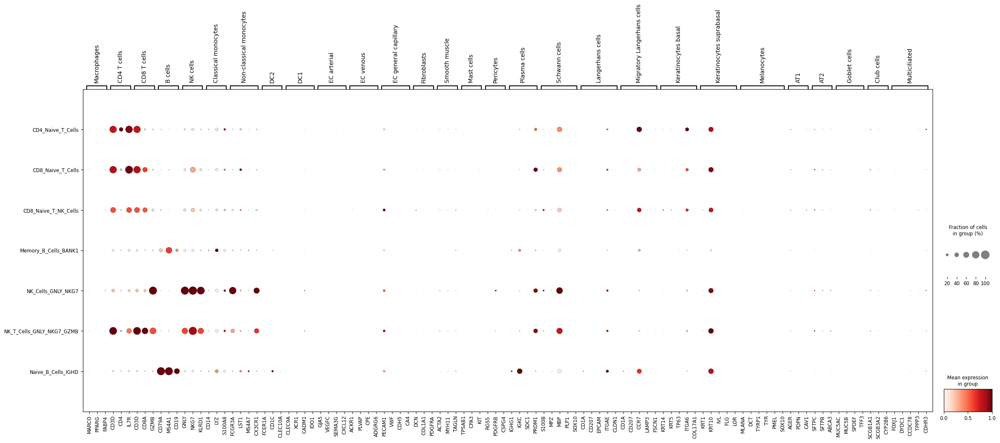

In [69]:
markers = {
    "Macrophages":     ["MARCO", "PPARG", "FABP4"],
    "CD4 T cells":              ["CD3D", "CD4", "IL7R"],
    "CD8 T cells":              ["CD3D", "CD8A", "GZMB"],
    "B cells":                  ["CD79A", "MS4A1", "CD19"],
    "NK cells":                 ["GNLY", "NKG7", "KLRD1"],
    "Classical monocytes":      ["CD14", "LYZ", "S100A8"],
    "Non-classical monocytes":  ["FCGR3A", "LST1", "MS4A7", "CX3CR1"],
    "DC2":                      ["FCER1A", "CD1C", "CLEC10A"],
    "DC1":                      ["CLEC9A", "XCR1", "CADM1", "IDO1"],
    "EC arterial":              ["GJA5", "VEGFC", "SEMA3G", "CXCL12"],   # ← aggiunto
    "EC venous":                ["ACKR1", "PLVAP", "CPE", "ADGRG6"],     # ← aggiunto
    "EC general capillary":     ["PECAM1", "VWF", "CDH5", "CA4"],        # ← aggiunto CA4
    "Fibroblasts":              ["DCN", "COL1A1", "PDGFRA"],
    "Smooth muscle":            ["ACTA2", "MYH11", "TAGLN"],
    "Mast cells":               ["TPSAB1", "CPA3", "KIT"],
    "Pericytes":                ["RGS5", "PDGFRB", "CSPG4"],
    "Plasma cells":             ["IGHG1", "IGKC", "SDC1", "PRDM1"],
    "Schwann cells":            ["S100B", "MPZ", "MBP", "PLP1", "SOX10"],
    "Langerhans cells":         ["CD1A", "CD207", "EPCAM", "ITGAE", "CLDN1"],
    "Migratory Langerhans cells": ["CD1A", "CD207", "CCR7", "LAMP3", "FSCN1"],
    "Keratinocytes basal":      ["KRT14", "KRT5", "TP63", "ITGA6", "COL17A1"],
    "Keratinocytes suprabasal": ["KRT1", "KRT10", "IVL", "FLG", "LOR"],
    "Melanocytes":              ["MLANA", "DCT", "TYRP1", "TYR", "PMEL", "SOX10"],
    "AT1":                      ["AGER", "PDPN", "CAV1"],
    "AT2":                      ["SFTPC", "SFTPB", "ABCA3"],
    "Goblet cells":             ["MUC5AC", "MUC5B", "SPDEF", "TFF3"],
    "Club cells":               ["SCGB1A1", "SCGB3A2", "CYP2B6"],
    "Multiciliated":            ["FOXJ1", "DYDC1", "CCDC78", "TPPP3", "CDHR3"],
}

# Filtra i marker presenti nel dataset
all_markers_flat = [g for genes in markers.values() for g in genes if g in adata_sub.var_names]

# Verifica quali marker mancano
missing = [g for genes in markers.values() for g in genes if g not in adata_sub.var_names]
if missing:
    print(f"Marker non trovati nel dataset: {missing}")

sc.pl.dotplot(
    adata_sub,
    var_names=markers,
    groupby="Lymphocytes_subpopulation",
    standard_scale="var",
    figsize=(28, 10),
)

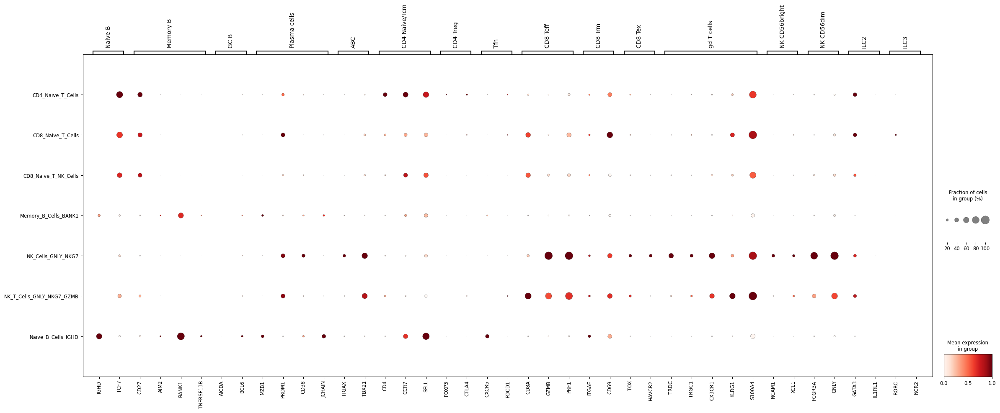

In [70]:
markers = {
    # ── Compartimento B ───────────────────────────────────────────────────────
    "Naive B":        ["IGHD", "TCF7"],
    "Memory B":       ["CD27", "AIM2", "BANK1", "TNFRSF13B"],
    "GC B":           ["AICDA", "BCL6"],
    "Plasma cells":   ["MZB1", "PRDM1", "CD38", "JCHAIN"],   # CD38 hi — conferma plasma
    "ABC":            ["ITGAX", "TBX21"],

    # ── Compartimento T ───────────────────────────────────────────────────────
    "CD4 Naive/Tcm":  ["CD4", "CCR7", "SELL"],      # CD4 conferma
    "CD4 Treg":       ["FOXP3", "CTLA4"],            # CD4 già sopra
    "Tfh":            ["CXCR5", "PDCD1"],
    "CD8 Teff":       ["CD8A", "GZMB", "PRF1"],      # CD8A conferma
    "CD8 Trm":        ["ITGAE", "CD69"],             # CD8A già sopra
    "CD8 Tex":        ["TOX", "HAVCR2"],             # CD8A già sopra
    "gd T cells":     ["TRDC", "TRGC1","CX3CR1","KLRG1","S100A4" ],

    # ── Compartimento NK / ILC ────────────────────────────────────────────────
    "NK CD56bright":  ["NCAM1", "XCL1"],
    "NK CD56dim":     ["FCGR3A", "GNLY"],
    "ILC2":           ["GATA3", "IL1RL1"],
    "ILC3":           ["RORC", "NCR2"],
}


# Filtra i marker presenti nel dataset
all_markers_flat = [g for genes in markers.values() for g in genes if g in adata_sub.var_names]

# Verifica quali marker mancano
missing = [g for genes in markers.values() for g in genes if g not in adata_sub.var_names]
if missing:
    print(f"Marker non trovati nel dataset: {missing}")

sc.pl.dotplot(
    adata_sub,
    var_names=markers,
    groupby="Lymphocytes_subpopulation",
    standard_scale="var",
    figsize=(28, 10),
)

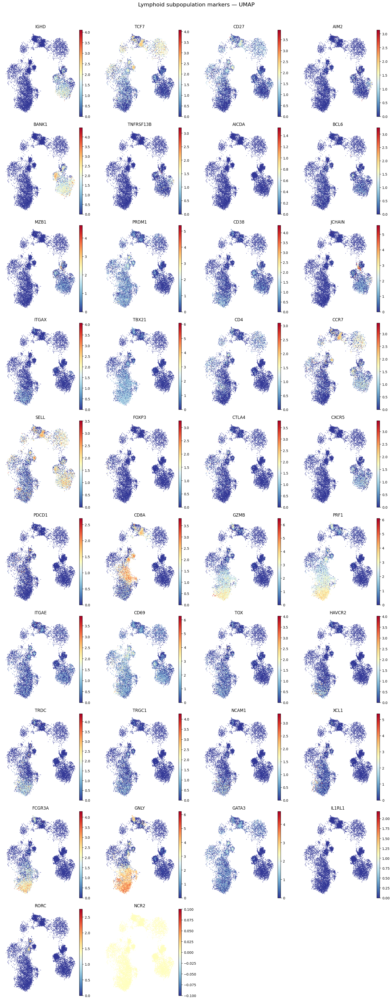

In [71]:
import matplotlib.pyplot as plt
import math

import matplotlib.pyplot as plt
import math

markers = {
    # ── Compartimento B ───────────────────────────────────────────────────────
    "Naive B":        ["IGHD", "TCF7"],
    "Memory B":       ["CD27", "AIM2", "BANK1", "TNFRSF13B"],
    "GC B":           ["AICDA", "BCL6"],
    "Plasma cells":   ["MZB1", "PRDM1", "CD38", "JCHAIN"],   # CD38 hi — conferma plasma
    "ABC":            ["ITGAX", "TBX21"],

    # ── Compartimento T ───────────────────────────────────────────────────────
    "CD4 Naive/Tcm":  ["CD4", "CCR7", "SELL"],      # CD4 conferma
    "CD4 Treg":       ["FOXP3", "CTLA4"],            # CD4 già sopra
    "Tfh":            ["CXCR5", "PDCD1"],
    "CD8 Teff":       ["CD8A", "GZMB", "PRF1"],      # CD8A conferma
    "CD8 Trm":        ["ITGAE", "CD69"],             # CD8A già sopra
    "CD8 Tex":        ["TOX", "HAVCR2"],             # CD8A già sopra
    "gd T cells":     ["TRDC", "TRGC1"],

    # ── Compartimento NK / ILC ────────────────────────────────────────────────
    "NK CD56bright":  ["NCAM1", "XCL1"],
    "NK CD56dim":     ["FCGR3A", "GNLY"],
    "ILC2":           ["GATA3", "IL1RL1"],
    "ILC3":           ["RORC", "NCR2"],
}

# Flatten tutti i geni
all_markers = [g for genes in markers.values() for g in genes if g in adata_sub.var_names]

missing = [g for genes in markers.values() for g in genes if g not in adata_sub.var_names]
if missing:
    print(f"⚠️  Marker mancanti: {missing}")

# Plot
n      = len(all_markers)
ncols  = 4
nrows  = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, gene in enumerate(all_markers):
    sc.pl.umap(
        adata_sub,
        color=gene,
        ax=axes[i],
        show=False,
        frameon=False,
        title=gene,
        cmap="RdYlBu_r",
        vmin=0,
        vmax=adata_sub[:, gene].X.max() if hasattr(adata_sub[:, gene].X, "max") else None,
    )

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Lymphoid subpopulation markers — UMAP", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

In [72]:
marker_genes_dict = {'SF1': ['PRG4'],
                     'SF2': 'CHI3L2',
                     'SF3': ['APOE'],
                     'SF4': ['POSTN'],
                     'SF5': ['FKBP5'],
                     'SF6': ['FOSB'],
                     'SF7': ['CXCL14'],
                     'SF8': ['MFAP5']}

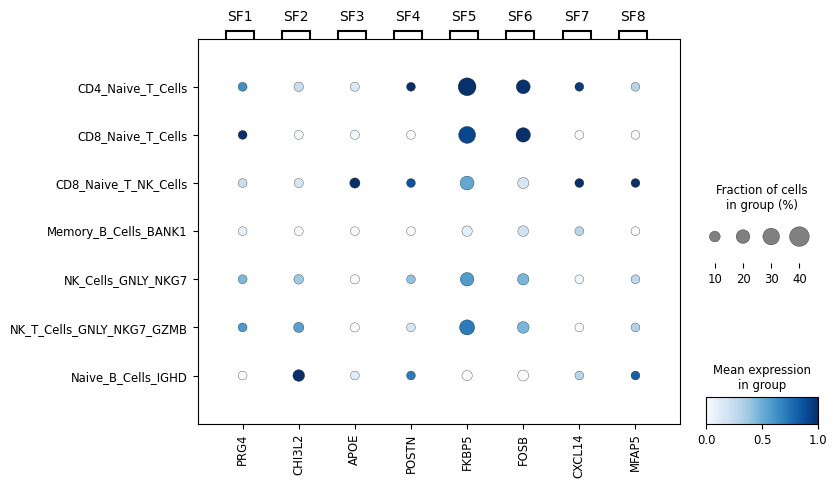

In [73]:
ax = sc.pl.dotplot(adata_all, marker_genes_dict, groupby='Lymphocytes_subpopulation', dendrogram=False,
                   standard_scale='var', smallest_dot=40, color_map='Blues', figsize=(8,5))

In [74]:
IFN_ALPHA_genes = [
  "ADAR","B2M","BATF2","BST2","C1S","CASP1","CASP8","CCRL2","CD47","CD74",
  "CMPK2","CMTR1","CNP","CSF1","CXCL10","CXCL11","DDX60","DHX58","EIF2AK2",
  "ELF1","EPSTI1","GBP2","GBP4","GMPR","HELZ2","HERC6","HLA-C","IFI27","IFI30",
  "IFI35","IFI44","IFI44L","IFIH1","IFIT2","IFIT3","IFITM1","IFITM2","IFITM3",
  "IL15","IL4R","IL7R","IRF1","IRF2","IRF7","IRF9","ISG15","ISG20","LAMP3",
  "LAP3","LGALS3BP","LPAR6","LY6E","MOV10","MVB12A","MX1","NCOA7","NMI","NUB1",
  "OAS1","OASL","OGFR","PARP12","PARP14","PARP9","PLSCR1","PNPT1","PROCR","PSMA3",
  "PSMB8","PSMB9","PSME1","PSME2","RIPK2","RNF31","RSAD2","RTP4","SAMD9","SAMD9L",
  "SELL","SLC25A28","SP110","STAT2","TAP1","TDRD7","TENT5A","TMEM140","TRAFD1",
  "TRIM14","TRIM21","TRIM25","TRIM26","TRIM5","TXNIP","UBA7","UBE2L6","USP18","WARS1"
]

IFN_GAMMA_genes = ["ADAR","APOL6","ARID5B","ARL4A","AUTS2","B2M","BANK1","BATF2","BPGM","BST2",
    "BTG1","C1R","C1S","CASP1","CASP3","CASP4","CASP7","CASP8","CCL2","CCL5","CCL7",
    "CD274","CD38","CD40","CD69","CD74","CD86","CDKN1A","CFB","CFH","CIITA","CMKLR1",
    "CMPK2","CSF2RB","CXCL10","CXCL11","CXCL9","RIGI","DDX60","DHX58","EIF2AK2","EIF4E3",
    "EPSTI1","FAS","FCGR1A","FGL2","FPR1","CMTR1","GBP4","GBP6","GCH1","GPR18","GZMA",
    "HERC6","HIF1A","HLA-A","HLA-B","HLA-DMA","HLA-DQA1","HLA-DRB1","HLA-G","ICAM1",
    "IDO1","IFI27","IFI30","IFI35","IFI44","IFI44L","IFIH1","IFIT1","IFIT2","IFIT3",
    "IFITM2","IFITM3","IFNAR2","IL10RA","IL15","IL15RA","IL18BP","IL2RB","IL4R","IL6",
    "IL7","IRF1","IRF2","IRF4","IRF5","IRF7","IRF8","IRF9","ISG15","ISG20","ISOC1",
    "ITGB7","JAK2","KLRK1","LAP3","LATS2","LCP2","LGALS3BP","LY6E","LYSMD2","MARCHF1",
    "TMT1B","MT2A","MTHFD2","MVP","MX1","MX2","MYD88","NAMPT","NCOA3","NFKB1","NFKBIA",
    "NLRC5","NMI","NOD1","NUP93","OAS2","OAS3","OASL","OGFR","P2RY14","PARP12","PARP14",
    "PDE4B","PELI1","PFKP","PIM1","PLA2G4A","PLSCR1","PML","PNP","PNPT1","HELZ2",
    "PSMA2","PSMA3","PSMB10","PSMB2","PSMB8","PSMB9","PSME1","PSME2","PTGS2","PTPN1",
    "PTPN2","PTPN6","RAPGEF6","RBCK1","RIPK1","RIPK2","RNF213","RNF31","RSAD2","RTP4",
    "SAMD9L","SAMHD1","SECTM1","SELP","SERPING1","SLAMF7","SLC25A28","SOCS1","SOCS3",
    "SOD2","SP110","SPPL2A","SRI","SSPN","ST3GAL5","ST8SIA4","STAT1","STAT2","STAT3",
    "STAT4","TAP1","TAPBP","TDRD7","TNFAIP2","TNFAIP3","TNFAIP6","TNFSF10","TOR1B",
    "TRAFD1","TRIM14","TRIM21","TRIM25","TRIM26","TXNIP","UBE2L6","UPP1","USP18","VAMP5",
    "VAMP8","VCAM1","WARS1","XAF1","XCL1","ZBP1","ZNFX1"
]

COMP_CLASS_genes = [
    "C1QA","C1QB","C1QBP","C1QC","C1R","C1RL","C1S","C2","C4A","C4B","SERPING1","C4BPA","C4BPB","CSMD1"
]

COMP_ALT_genes = [
    "CFB","CFD","CFP","CFH","C3"
]

COMP_ALL_genes = [
    "C3","C5","C6","C7","C8A","C8B","C9","CFI","CR1","CD46","CD55","CD59","VTN","CLU","SVEP1","SUSD4","THBD"
]

sc.tl.score_genes(adata_all, gene_list=IFN_ALPHA_genes, score_name="IFN_ALPHA_genes")
sc.tl.score_genes(adata_all, gene_list=IFN_GAMMA_genes, score_name="IFN_GAMMA_genes")
sc.tl.score_genes(adata_all, gene_list=COMP_CLASS_genes, score_name="COMP_CLASS_genes")
sc.tl.score_genes(adata_all, gene_list=COMP_ALT_genes, score_name="COMP_ALT_genes")
sc.tl.score_genes(adata_all, gene_list=COMP_ALL_genes, score_name="COMP_ALL_genes")


Plotting IFN_ALPHA_genes ...


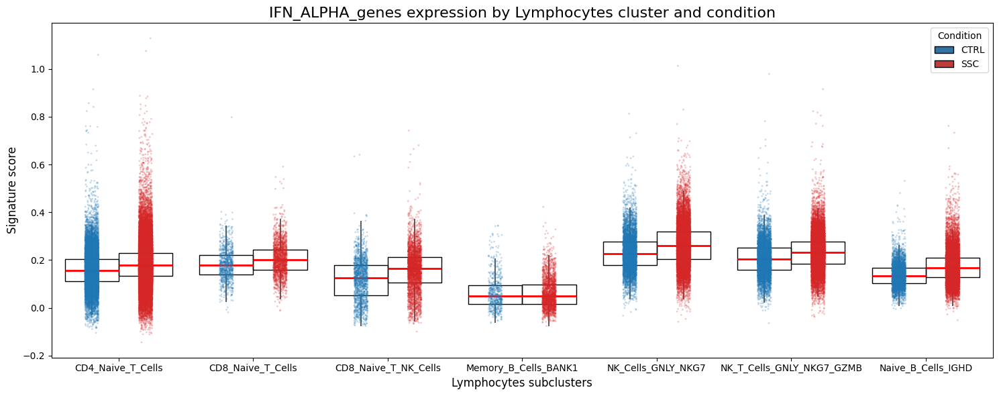

Plotting IFN_GAMMA_genes ...


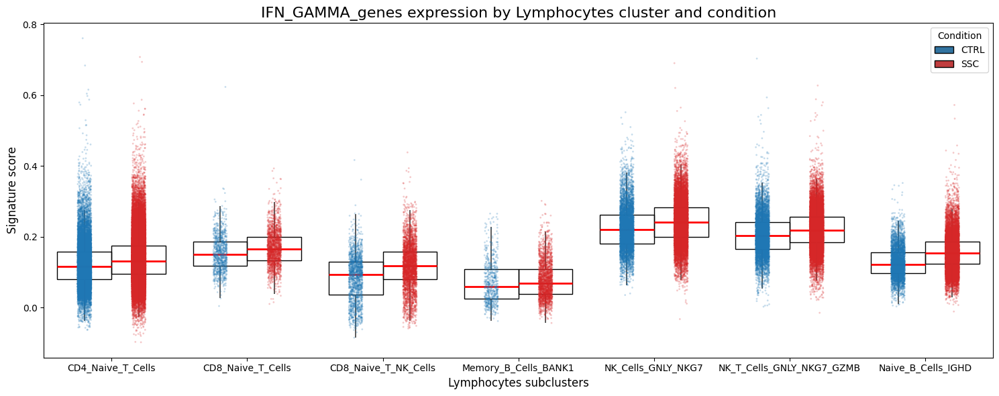

Plotting COMP_CLASS_genes ...


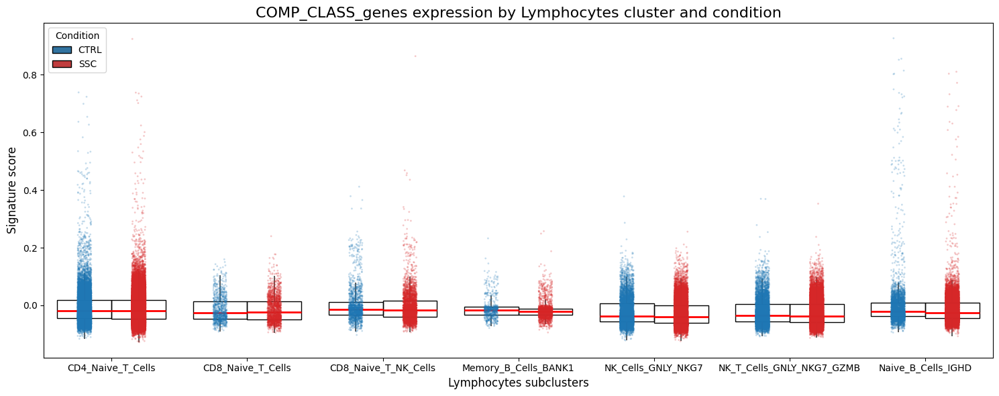

Plotting COMP_ALT_genes ...


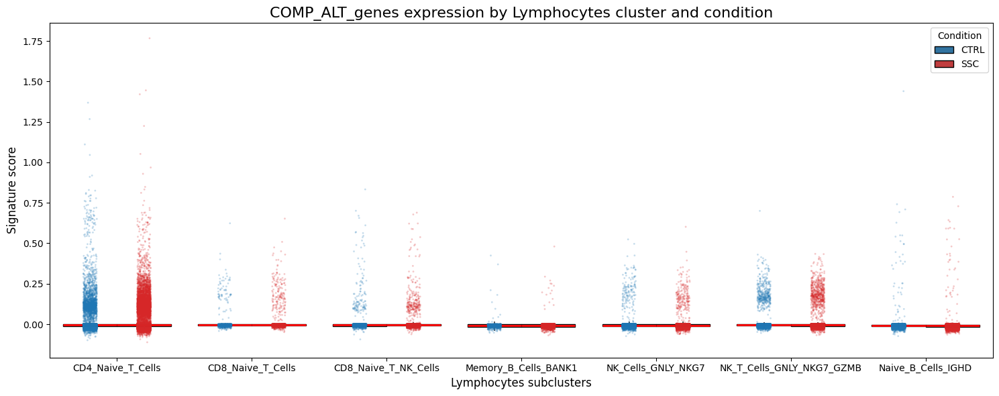

Plotting COMP_ALL_genes ...


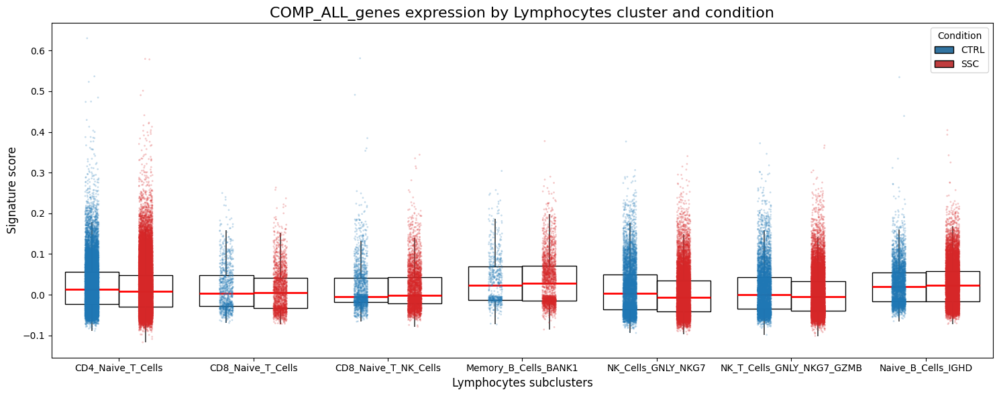

In [75]:
import seaborn as sns
import matplotlib.pyplot as plt

scores = [
    'IFN_ALPHA_genes',
    'IFN_GAMMA_genes',
    'COMP_CLASS_genes',
    'COMP_ALT_genes',
    'COMP_ALL_genes'
]

# Custom colors for the conditions
cond_palette = {
    "CTRL": "#1f77b4",   # blue
    "SSC":  "#d62728"    # red
}

# Ensure categories
adata_all.obs["Lymphocytes_subpopulation"] = adata_all.obs["Lymphocytes_subpopulation"].astype("category")
adata_all.obs["Condition"] = adata_all.obs["Condition"].astype("category")

for score in scores:
    print(f"Plotting {score} ...")

    df = adata_all.obs[[score, "Condition", "Lymphocytes_subpopulation"]].copy()

    # Drop rows where score is missing
    df = df.dropna(subset=[score])

    plt.figure(figsize=(15, 6))

    # --- BEAUTIFUL BOXPLOT WITH CUSTOM COLORS ---
    ax = sns.boxplot(
        data=df,
        x="Lymphocytes_subpopulation",
        y=score,
        hue='Condition',
        palette=cond_palette,
        showcaps=False,
        boxprops={'facecolor':'None', 'edgecolor':'black'},
        whiskerprops={'linewidth':1.2},
        medianprops={'color':'red', 'linewidth':2},
        showfliers=False
    )

    # --- DOTS WITH SAME COLORS ---
    sns.stripplot(
        data=df,
        x="Lymphocytes_subpopulation",
        y=score,
        hue='Condition',
        palette=cond_palette,
        dodge=True,
        jitter=True,
        alpha=0.25,
        size=2,
        linewidth=0
    )

    # Remove double legends (boxplot + stripplot)
    handles, labels = ax.get_legend_handles_labels()
    plt.legend(handles[:2], labels[:2], title="Condition")

    plt.title(f"{score} expression by Lymphocytes cluster and condition", fontsize=16)
    plt.xlabel("Lymphocytes subclusters", fontsize=12)
    plt.ylabel("Signature score", fontsize=12)

    plt.tight_layout()
    plt.show()


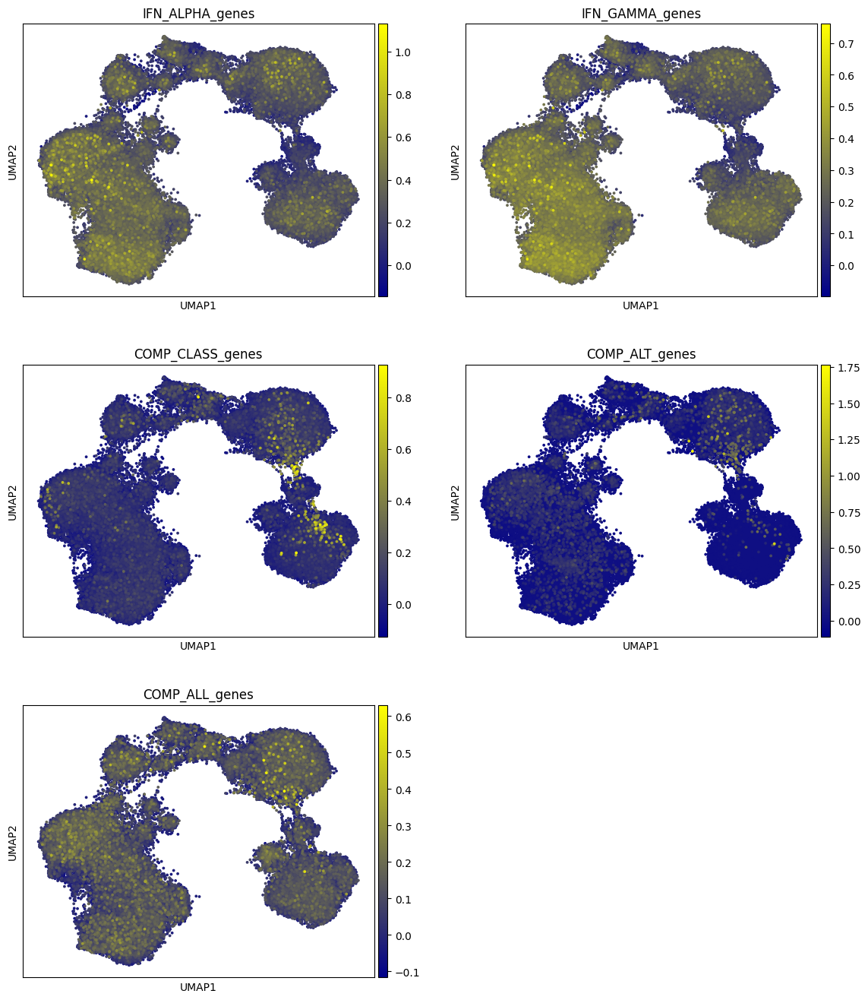

In [76]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Define a green-to-dark-red colormap
green_red = LinearSegmentedColormap.from_list("yellow_red", ["darkblue", "yellow"])

# List of scores to plot
scores = [
    "IFN_ALPHA_genes",
    "IFN_GAMMA_genes",
    "COMP_CLASS_genes",
    "COMP_ALT_genes",
    "COMP_ALL_genes"
]

# Plot UMAP for all scores
sc.pl.umap(
    adata_all,
    color=scores,
    ncols=2,          # number of columns in the plot grid
    size=30,          # adjust dot size
    cmap=green_red,   # custom green-to-dark-red gradient
    show=True
)


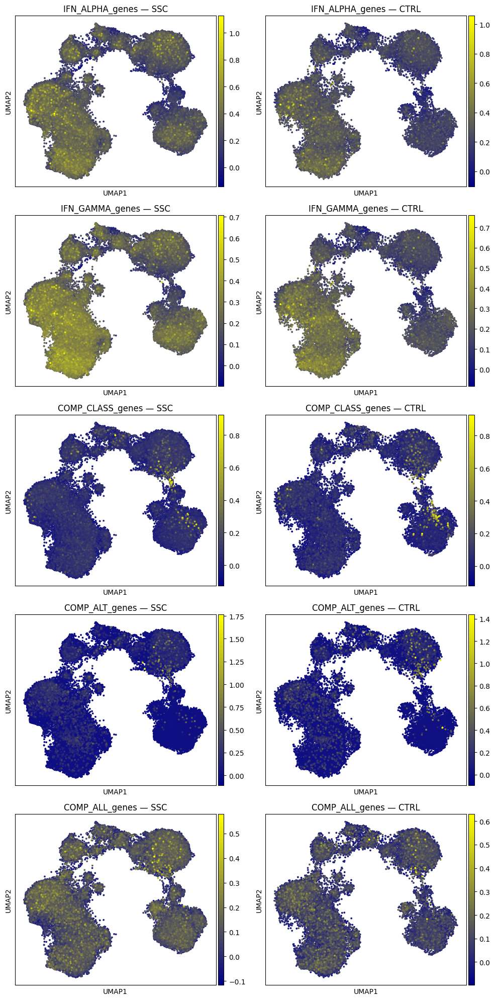

In [77]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Define a green-to-dark-red colormap
green_red = LinearSegmentedColormap.from_list("yellow_red", ["darkblue", "yellow"])

scores = [
    "IFN_ALPHA_genes",
    "IFN_GAMMA_genes",
    "COMP_CLASS_genes",
    "COMP_ALT_genes",
    "COMP_ALL_genes"
]

conditions = adata_all.obs["Condition"].unique().tolist()  # es. ['SSC', 'CTRL']

# Griglia: righe = score, colonne = condizioni
fig, axes = plt.subplots(
    nrows=len(scores), ncols=len(conditions),
    figsize=(5 * len(conditions), 4 * len(scores))
)

for i, score in enumerate(scores):
    for j, cond in enumerate(conditions):
        ax = axes[i, j] if len(scores) > 1 else axes[j]
        subset = adata_all[adata_all.obs["Condition"] == cond]
        sc.pl.umap(
            subset,
            color=score,
            size=30,
            cmap=green_red,
            ax=ax,
            show=False,
            title=f"{score} — {cond}"
        )

plt.tight_layout()
plt.show()

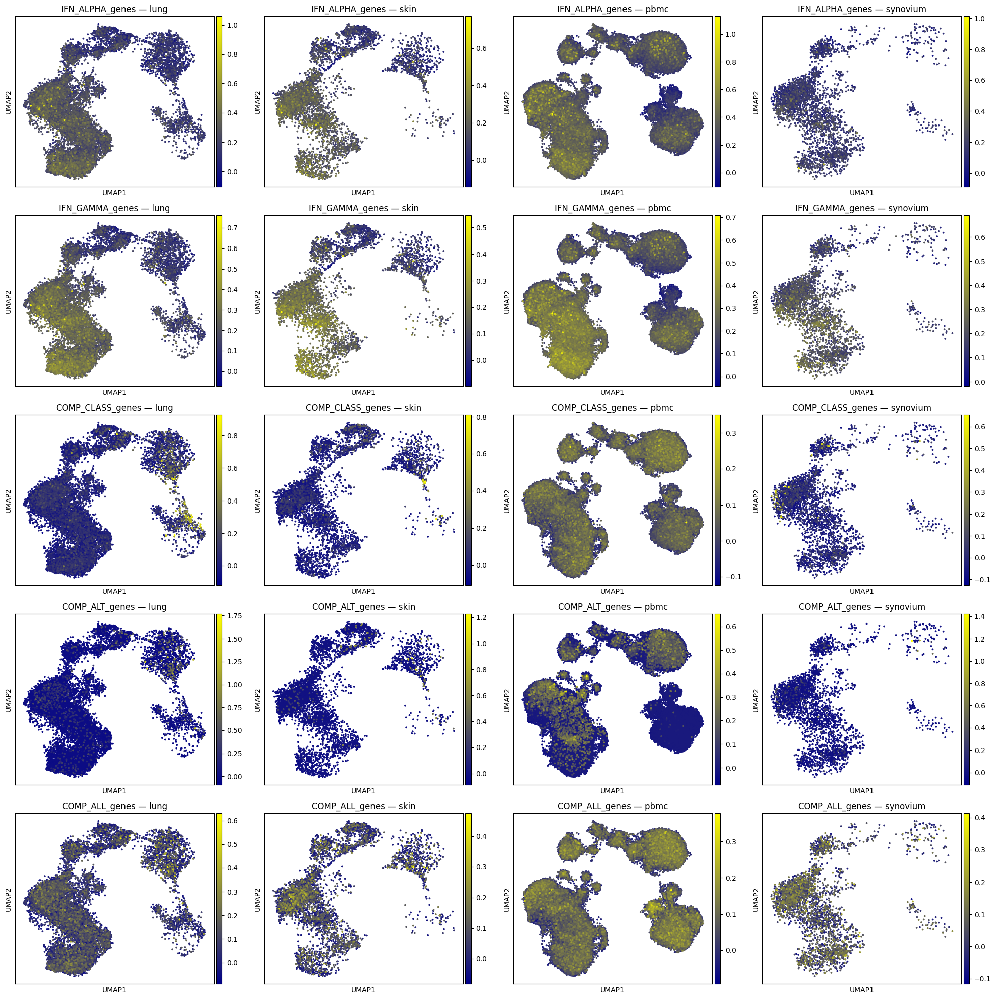

In [78]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Define a green-to-dark-red colormap
green_red = LinearSegmentedColormap.from_list("yellow_red", ["darkblue", "yellow"])

scores = [
    "IFN_ALPHA_genes",
    "IFN_GAMMA_genes",
    "COMP_CLASS_genes",
    "COMP_ALT_genes",
    "COMP_ALL_genes"
]

conditions = adata_all.obs["tissue"].unique().tolist()  # es. ['SSC', 'CTRL']

# Griglia: righe = score, colonne = condizioni
fig, axes = plt.subplots(
    nrows=len(scores), ncols=len(conditions),
    figsize=(5 * len(conditions), 4 * len(scores))
)

for i, score in enumerate(scores):
    for j, cond in enumerate(conditions):
        ax = axes[i, j] if len(scores) > 1 else axes[j]
        subset = adata_all[adata_all.obs["tissue"] == cond]
        sc.pl.umap(
            subset,
            color=score,
            size=30,
            cmap=green_red,
            ax=ax,
            show=False,
            title=f"{score} — {cond}"
        )

plt.tight_layout()
plt.show()

In [79]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

scores = [
    'IFN_ALPHA_genes',
    'IFN_GAMMA_genes',
    'COMP_CLASS_genes',
    'COMP_ALT_genes',
    'COMP_ALL_genes'
]

adata_all.obs["Lymphocytes_subpopulation"] = adata_all.obs["Lymphocytes_subpopulation"].astype("category")

all_results = {}   # store results for each score

for score in scores:
    print(f"\n🔎 Running statistics for: {score}")

    df = adata_all.obs[[score, "Condition", "Lymphocytes_subpopulation"]].copy()
    df = df.dropna(subset=[score])

    results = []

    for cl in df["Lymphocytes_subpopulation"].cat.categories:
        subset = df[df["Lymphocytes_subpopulation"] == cl]

        ssc = subset[subset["Condition"] == "SSC"][score]
        ctrl = subset[subset["Condition"] == "CTRL"][score]

        if len(ssc) > 3 and len(ctrl) > 3:
            stat, p = mannwhitneyu(ssc, ctrl, alternative="two-sided")
        else:
            p = np.nan

        results.append({
            "cluster": cl,
            "n_SSC": len(ssc),
            "n_CTRL": len(ctrl),
            "p_value": p
        })

    stats_table = pd.DataFrame(results)

    # FDR correction (Benjamini–Hochberg)
    valid_mask = stats_table["p_value"].notna()
    _, fdr_corrected, _, _ = multipletests(
        stats_table.loc[valid_mask, "p_value"],
        method="fdr_bh"
    )
    stats_table.loc[valid_mask, "FDR"] = fdr_corrected

    all_results[score] = stats_table
    print(stats_table)



🔎 Running statistics for: IFN_ALPHA_genes
                     cluster  n_SSC  n_CTRL        p_value            FDR
0          CD4_Naive_T_Cells  46710   17741  7.029959e-240  4.920971e-239
1          CD8_Naive_T_Cells   1915     931   1.728935e-17   2.017091e-17
2       CD8_Naive_T_NK_Cells   3532    1628   2.030639e-51   2.842895e-51
3       Memory_B_Cells_BANK1   2230     624   7.471346e-01   7.471346e-01
4         NK_Cells_GNLY_NKG7  13187    5947  3.948106e-144  9.212246e-144
5  NK_T_Cells_GNLY_NKG7_GZMB  15308    6204  2.887590e-133  5.053283e-133
6         Naive_B_Cells_IGHD  13781    3965  3.112347e-227  1.089321e-226

🔎 Running statistics for: IFN_GAMMA_genes
                     cluster  n_SSC  n_CTRL        p_value            FDR
0          CD4_Naive_T_Cells  46710   17741  1.845849e-184  6.460471e-184
1          CD8_Naive_T_Cells   1915     931   3.000960e-13   3.501120e-13
2       CD8_Naive_T_NK_Cells   3532    1628   6.183644e-58   8.657102e-58
3       Memory_B_Cells_BAN

In [6]:
#Calculating the markers for each subpopulation:
import scanpy as sc
import pandas as pd

# Make sure cell type column is categorical
adata_all.obs['Lymphocytes_subpopulation'] = adata_all.obs['Lymphocytes_subpopulation'].astype('category')

# 1️⃣ Compute one-vs-all markers
sc.tl.rank_genes_groups(
    adata_all,
    groupby='Lymphocytes_subpopulation',    # column with cell type labels
    method='wilcoxon',      # equivalent to Seurat default
    n_genes=adata_all.shape[1],  
    pts=True                 # include fraction of cells expressing the gene
)

# 2️⃣ Extract results into a tidy DataFrame
markers = adata_all.uns['rank_genes_groups']
cell_types = markers['names'].dtype.names

marker_list = []
for ct in cell_types:
    n_genes = len(markers['names'][ct])
    for i in range(n_genes):
        # Fraction of cells expressing gene in the cluster
        pct = markers['pts'][ct][i]
        if pct >= 0.1:  # min.pct = 0.1
            marker_list.append({
                'Lymphocytes_subpopulation': ct,
                'gene': markers['names'][ct][i],
                'logfoldchange': markers['logfoldchanges'][ct][i],
                'pval': markers['pvals'][ct][i],
                'pval_adj': markers['pvals_adj'][ct][i],
                'pct_in_group': markers['pts'][ct][i],
                'pct_rest': markers['pts_rest'][ct][i]
            })

marker_df = pd.DataFrame(marker_list)

# 3️⃣ Sort by cell type and log fold change (optional)
marker_df = marker_df.sort_values(['Lymphocytes_subpopulation', 'logfoldchange'], ascending=[True, False])

# Show top markers
marker_df.head(10)


/tmp/ipykernel_1666055/315692469.py:26: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pct = markers['pts'][ct][i]
/tmp/ipykernel_1666055/315692469.py:34: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  'pct_in_group': markers['pts'][ct][i],
/tmp/ipykernel_1666055/315692469.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  'pct_rest': markers['pts_rest'][ct][i]


,Lymphocytes_subpopulation,gene,logfoldchange,pval,pval_adj,pct_in_group,pct_rest
474,Mixed_NaiveCD8T_NK,CYP11A1,19.530300,0.981138,1.0,0.167636,0.243327
475,Mixed_NaiveCD8T_NK,TVP23C-CDRT4,19.221416,0.981138,1.0,0.106977,0.140910
469,Mixed_NaiveCD8T_NK,SMPX,19.194458,0.981138,1.0,0.221899,0.338680
472,Mixed_NaiveCD8T_NK,TM4SF19-TCTEX1D2,18.785635,0.981138,1.0,0.100775,0.126059
471,Mixed_NaiveCD8T_NK,PPDPFL,18.764147,0.981138,1.0,0.109109,0.123297
473,Mixed_NaiveCD8T_NK,KRT37,18.395800,0.981138,1.0,0.380620,0.440351
470,Mixed_NaiveCD8T_NK,LINC02477,17.384632,0.981138,1.0,0.128876,0.194736
379,Mixed_NaiveCD8T_NK,C6orf15,8.160728,0.944211,1.0,0.151744,0.188723
481,Mixed_NaiveCD8T_NK,CKLF-CMTM1,5.506845,0.981895,1.0,0.177713,0.218028
92,Mixed_NaiveCD8T_NK,HAO2,5.331378,0.480512,1.0,0.181008,0.217873


In [81]:
import os
# Set as working directory
os.chdir("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Lymphocytes_subpop/")


In [7]:
import os

# Create the output folder if it doesn't exist
output_dir = "markers_subLymphocytes"
os.makedirs(output_dir, exist_ok=True)

# Save markers for each cell type separately
for ct in marker_df['Lymphocytes_subpopulation'].unique():
    df_ct = marker_df[marker_df['Lymphocytes_subpopulation'] == ct].copy()
    # Optional: sort by log fold change descending
    df_ct = df_ct.sort_values('logfoldchange', ascending=False)
    # Save to CSV
    filename = os.path.join(output_dir, f"{ct.replace('/', '_').replace(' ', '_')}_markers.csv")
    df_ct.to_csv(filename, index=False)

print(f"✅ Marker files saved in folder '{output_dir}'")


✅ Marker files saved in folder 'markers_subLymphocytes'


In [5]:
#!/usr/bin/env python3
# =============================================================================
# subpopulation_marker_dotplot_lymphoid.py
#   (lymphoid counterpart of subpopulation_marker_dotplot.py, fibroblasts /
#   subpopulation_marker_dotplot_myeloid.py, myeloid)
#
# PURPOSE:
#   Dotplot of curated marker genes across lymphoid subpopulations.
#   logFC (colour) and pct_in_group (size) are computed DIRECTLY from the
#   expression matrix (adata_all.X) for exactly the genes in MANUAL_MARKERS,
#   so no gene is missing because of a top-N rank cutoff.
#
#   Rows    = subpopulations, with a coloured bar on the y axis showing
#             tissue specificity - same convention as the fibroblast/
#             myeloid figures (SUBPOP_TISSUE/TISSUE_COLORS), for visual
#             consistency across the three figures. Every lymphoid
#             subpopulation here is "Pan_*", so this bar is uniformly grey
#             ("Pan-tissue") - it carries no extra information on its own,
#             kept anyway so the three figures read as one consistent set.
#   Columns = marker genes (each gene appears once, under the first
#             subpopulation in SUBPOP_ORDER that claims it) - but every
#             subpopulation still gets ITS OWN logFC/pct dot in every gene
#             column (not just the "owning" population), so shared markers
#             (e.g. CCR7/SELL across the naive populations) show correctly
#             in every row that expresses them.
#
#   Exploratory/visual only: no statistical test.
#
# INPUT:
#   adata_all (AnnData) already in memory, log1p-normalised, with SUBPOP_COL
#   in .obs holding the final subpopulation labels (here, the lymphoid
#   cluster annotation).
#
# OUTPUT:
#   Figures/Figure_Subpopulation_Marker_Dotplot_Lymphoid.pdf/.png/.svg
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
OUTPUT_DIR    = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Subpopulation_Marker_Dotplot_Lymphoid")

SUBPOP_COL = "Lymphocytes_subpopulation"

# Full cluster -> subpopulation-name annotation, for reference (this is
# LYMPHOID_CLUSTER_ANNOTATION as shared). No cluster is excluded here -
# unlike the fibroblast/myeloid figures, there is no "Mixed_*"/ambiguous
# catch-all cluster in this list: "Pan_NaiveCD8T_NK" is a deliberate,
# distinct population (kept separate from "Pan_NaiveCD8T" on purpose, per
# your note), not a merged/ambiguous one, so it stays in:
#   "0":  "Pan_NKT_GNLY_GZMB",    # NK with T-like (CD8+) profile
#   "2":  "Pan_NK_GNLY_NKG7",     # pure NK, no T marker
#   "1", "3", "6", "9": "Pan_NaiveCD4T",   # merged: same CD4 naive profile
#   "4":  "Pan_NaiveCD8T_NK",     # CD8 naive mixed with NK-like cells
#   "5":  "Pan_NaiveCD8T",        # kept separate: distinct NK profile
#   "7":  "Pan_NaiveB_IGHD",
#   "8":  "Pan_MemoryB_BANK1",

MANUAL_MARKERS = {
    "Pan_NKT_GNLY_GZMB":    ["GNLY", "GZMB", "CD8A"],
    "Pan_NK_GNLY_NKG7":     ["GNLY", "NKG7", "KLRD1"],
    "Pan_NaiveCD4T":        ["CD4", "SELL", "CCR7"],
    "Pan_NaiveCD8T_NK":     ["CD8A", "SELL", "CCR7", "NKG7"],
    "Pan_NaiveCD8T":        ["CD8A", "SELL", "CCR7"],
    "Pan_NaiveB_IGHD":      ["IGHD", "MS4A1", "SELL", "CCR7"],
    "Pan_MemoryB_BANK1":    ["BANK1", "CD79A", "MS4A1"],
}

# Row order grouped by lineage (NK > CD4T > CD8T > B) for readability, mirroring the
# tissue-grouped ordering used in the fibroblast/myeloid scripts
SUBPOP_ORDER = [
    "Pan_NKT_GNLY_GZMB",
    "Pan_NK_GNLY_NKG7",
    "Pan_NaiveCD4T",
    "Pan_NaiveCD8T_NK",
    "Pan_NaiveCD8T",
    "Pan_NaiveB_IGHD",
    "Pan_MemoryB_BANK1",
]

SUBPOP_TISSUE = {
    "Pan_NKT_GNLY_GZMB":    "pan",
    "Pan_NK_GNLY_NKG7":     "pan",
    "Pan_NaiveCD4T":        "pan",
    "Pan_NaiveCD8T_NK":     "pan",
    "Pan_NaiveCD8T":        "pan",
    "Pan_NaiveB_IGHD":      "pan",
    "Pan_MemoryB_BANK1":    "pan",
}

TISSUE_COLORS = {
    "pan": "#CCCCCC",   # same hex as the fibroblast/myeloid figures
}

TISSUE_LABELS = {"pan": "Pan-tissue"}


# Figure / style
FIG_W, FIG_H   = 6.5, 2.4
DOT_SIZE_RANGE = (10, 150)     # marker area (points^2) for pct 0-100%
FONT_SIZE      = 7.5
VMAX_CAP       = 3.5           # saturate colour scale at +/- this logFC

# ── STEP 1: CHECK SUBPOPULATIONS PRESENT IN adata_all ────────────────────────
print("[1/4] Checking subpopulations in adata_all...")

present_subpops = set(adata_all.obs[SUBPOP_COL].astype(str).unique())
subpops = [s for s in SUBPOP_ORDER if s in present_subpops]
missing_subpops = [s for s in SUBPOP_ORDER if s not in present_subpops]
if missing_subpops:
    print(f"  NOTE: not found in adata_all.obs['{SUBPOP_COL}']: {missing_subpops}")
extra = sorted(present_subpops - set(SUBPOP_ORDER))
if extra:
    print(f"  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): {extra}")
print(f"  Subpopulations to plot ({len(subpops)}): {subpops}")

# ── STEP 2: GENE ORDER (each gene claimed once, by first subpop in order) ────
print("\n[2/4] Building marker gene list from MANUAL_MARKERS...")

marker_gene_owner = {}
gene_order = []

for sp in subpops:
    for gene in MANUAL_MARKERS.get(sp, []):
        if gene in marker_gene_owner:
            print(f"  NOTE: '{gene}' already assigned to {marker_gene_owner[gene]} "
                  f"- column not duplicated for {sp} (its dot is still shown)")
            continue
        marker_gene_owner[gene] = sp
        gene_order.append(gene)

all_genes_needed = sorted({g for sp in subpops for g in MANUAL_MARKERS.get(sp, [])})
genes_in_data = [g for g in all_genes_needed if g in adata_all.var_names]
genes_missing = [g for g in all_genes_needed if g not in adata_all.var_names]
if genes_missing:
    print(f"  WARNING: genes not in adata_all.var_names (will be blank): {genes_missing}")

n_genes = len(gene_order)
print(f"\n  Total marker gene columns: {n_genes}")

# ── STEP 3: logFC / pct_in_group FROM THE EXPRESSION MATRIX ──────────────────
print("\n[3/4] Computing logFC and pct_in_group from adata_all.X...")

def compute_marker_stats(adata, groupby, genes):
    """pct_in_group = fraction of cells in the group with expression > 0.
    logfoldchange = log2 ratio of mean un-logged expression, group vs rest.
    Assumes adata.X is log1p-normalised."""
    X = adata[:, genes].X
    X = np.asarray(X.todense()) if hasattr(X, "todense") else np.asarray(X)

    df_expr = pd.DataFrame(X, columns=genes, index=adata.obs_names)
    groups = adata.obs[groupby].astype(str).values

    rows = []
    for grp in pd.unique(groups):
        in_mask = groups == grp
        for gene in genes:
            expr_in   = df_expr.loc[in_mask, gene]
            expr_rest = df_expr.loc[~in_mask, gene]
            mean_in   = float(np.expm1(expr_in).mean())
            mean_rest = float(np.expm1(expr_rest).mean())
            rows.append({
                "group": grp,
                "gene": gene,
                "logfoldchange": float(np.log2((mean_in + 1e-9) / (mean_rest + 1e-9))),
                "pct_in_group": float((expr_in > 0).mean()),
            })
    return pd.DataFrame(rows)

stats_long = compute_marker_stats(adata_all, SUBPOP_COL, genes_in_data)

logfc_matrix = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)
pct_matrix   = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)

for sp in subpops:
    sub = stats_long[stats_long["group"] == sp].set_index("gene")
    for gene in gene_order:
        if gene in sub.index:
            logfc_matrix.loc[sp, gene] = sub.loc[gene, "logfoldchange"]
            pct_matrix.loc[sp, gene]   = sub.loc[gene, "pct_in_group"]

vmax = np.nanmax(np.abs(logfc_matrix.values))
vmax = min(vmax, VMAX_CAP)

# ── STEP 4: PLOT ─────────────────────────────────────────────────────────────
print("\n[4/4] Plotting...")

fig = plt.figure(figsize=(FIG_W, FIG_H))
# 3 columns: tissue bar | dotplot | dedicated side panel for colourbar + legends
gs  = fig.add_gridspec(1, 3, width_ratios=[0.03, 1, 0.34], wspace=0.05)
ax_tissue = fig.add_subplot(gs[0])
ax        = fig.add_subplot(gs[1], sharey=ax_tissue)   # shared y axis
ax_side   = fig.add_subplot(gs[2])
ax_side.axis('off')
cmap = plt.get_cmap('RdBu_r')

def scale_size(pct):
    lo, hi = DOT_SIZE_RANGE
    return lo + (hi - lo) * np.clip(pct, 0, 1)

# Background grid and separators between gene blocks
for j in range(n_genes):
    ax.axvline(j, color='#EEEEEE', linewidth=0.5, zorder=1)
for i in range(len(subpops)):
    ax.axhline(i, color='#EEEEEE', linewidth=0.5, zorder=1)

gene_owner_list = [marker_gene_owner[g] for g in gene_order]
for j in range(1, n_genes):
    if gene_owner_list[j] != gene_owner_list[j - 1]:
        ax.axvline(j - 0.5, color='#999999', linewidth=0.9, zorder=2)

# Dots
for i, sp in enumerate(subpops):
    for j, gene in enumerate(gene_order):
        logfc = logfc_matrix.loc[sp, gene]
        pct   = pct_matrix.loc[sp, gene]
        if pd.isna(logfc):
            continue
        color = cmap((logfc + vmax) / (2 * vmax))
        ax.scatter(j, i, s=scale_size(pct), color=color,
                   edgecolor='#222222', linewidth=0.4, zorder=3)

# Tissue bar on the y axis (one coloured cell per subpopulation) - all
# "pan" here, see the note at the top of the file.
for i, sp in enumerate(subpops):
    tissue = SUBPOP_TISSUE.get(sp, "pan")
    ax_tissue.add_patch(plt.Rectangle((0, i - 0.5), 1, 1,
                                      facecolor=TISSUE_COLORS[tissue],
                                      edgecolor='white', linewidth=0.8))
ax_tissue.set_xlim(0, 1)
ax_tissue.set_xticks([])
for spine in ax_tissue.spines.values():
    spine.set_visible(False)

# Axis limits (set once; y is shared and inverted once)
ax.set_xlim(-0.5, n_genes - 0.5)
ax.set_ylim(-0.5, len(subpops) - 0.5)
ax.invert_yaxis()

# X ticks: genes
ax.set_xticks(range(n_genes))
ax.set_xticklabels(gene_order, rotation=90, fontsize=FONT_SIZE, style='italic')

# Y ticks: subpopulation names next to the tissue bar
ax_tissue.set_yticks(range(len(subpops)))
ax_tissue.set_yticklabels(subpops, fontsize=FONT_SIZE)
ax_tissue.set_ylabel("Subpopulation", fontsize=FONT_SIZE + 1)
ax_tissue.tick_params(axis='y', length=0)
ax.tick_params(axis='y', length=0, labelleft=False)
ax.tick_params(axis='x', length=2)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# ── Side panel: colourbar + size legend + tissue legend, stacked, no overlap ──
# All three are placed inside ax_side (transAxes coords 0-1 in both x and y),
# so their vertical slots are reserved explicitly instead of relying on
# matplotlib's automatic placement (which is what caused overlap before).

# 1) Colourbar (logFC) — small vertical bar in the top slot
cax = ax_side.inset_axes([0.02, 0.66, 0.18, 0.30])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=-vmax, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("log2 FC\n(vs rest)", fontsize=FONT_SIZE - 1)
cbar.ax.tick_params(labelsize=FONT_SIZE - 1.5, length=2)

# 2) Size legend (pct_in_group) — middle slot
legend_pcts = [0.25, 0.5, 0.75, 1.0]
legend_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#888888', markeredgecolor='#333333',
           markersize=np.sqrt(scale_size(p)), label=f"{int(p * 100)}%")
    for p in legend_pcts
]
size_leg = ax_side.legend(handles=legend_handles, title="% cells\nexpressing",
                          fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
                          loc='center left', bbox_to_anchor=(0.30, 0.42),
                          bbox_transform=ax_side.transAxes,
                          frameon=False, labelspacing=0.6, borderaxespad=0,
                          handletextpad=0.8)
ax_side.add_artist(size_leg)

# 3) Tissue legend — bottom slot
tissue_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=TISSUE_COLORS[t],
                                edgecolor='#666666', linewidth=0.4,
                                label=TISSUE_LABELS[t])
                  for t in TISSUE_COLORS]
ax_side.legend(handles=tissue_handles, title="Tissue specificity",
              loc='center left', bbox_to_anchor=(0.0, -0.02),
              bbox_transform=ax_side.transAxes,
              fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
              frameon=False, labelspacing=0.35, handlelength=1.2,
              borderaxespad=0, alignment='left')

os.makedirs(OUTPUT_DIR, exist_ok=True)
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[1/4] Checking subpopulations in adata_all...
  NOTE: not found in adata_all.obs['Lymphocytes_subpopulation']: ['Pan_NaiveCD8T_NK']
  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): ['Mixed_NaiveCD8T_NK']
  Subpopulations to plot (6): ['Pan_NKT_GNLY_GZMB', 'Pan_NK_GNLY_NKG7', 'Pan_NaiveCD4T', 'Pan_NaiveCD8T', 'Pan_NaiveB_IGHD', 'Pan_MemoryB_BANK1']

[2/4] Building marker gene list from MANUAL_MARKERS...
  NOTE: 'GNLY' already assigned to Pan_NKT_GNLY_GZMB - column not duplicated for Pan_NK_GNLY_NKG7 (its dot is still shown)
  NOTE: 'CD8A' already assigned to Pan_NKT_GNLY_GZMB - column not duplicated for Pan_NaiveCD8T (its dot is still shown)
  NOTE: 'SELL' already assigned to Pan_NaiveCD4T - column not duplicated for Pan_NaiveCD8T (its dot is still shown)
  NOTE: 'CCR7' already assigned to Pan_NaiveCD4T - column not duplicated for Pan_NaiveCD8T (its dot is still shown)
  NOTE: 'SELL' already assigned to Pan_NaiveCD4T - column not duplicated for Pan_NaiveB_IGHD (its dot is 

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import random


np.random.seed(0)
random.seed(0)


#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_lymphocytes.h5ad")
adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_lymphocytes.h5ad")

In [2]:
#!/usr/bin/env python3
"""
merge_replicate_samples_lymphocytes.py

Applica alla sottopopolazione (adata_all, gia' in memoria) la STESSA fusione
dei campioni replicati gia' fatta sull'atlante principale - solo sui
metadati ('obs'), senza toccare X/obsm/uns e senza ricaricare o risalvare
l'oggetto.

Cosa fa, in-place su adata_all.obs:
  1. Copia 'sample' (nomi originali) in 'replicates_samples'.
  2. Sovrascrive 'sample' fondendo i gruppi in INDIVIDUAL_GROUPS sotto il
     nome del primo campione del gruppo - esattamente come nell'atlante
     principale, cosi' 'sample' resta coerente ovunque.

Assunzione: adata_all.obs ha le colonne 'batch' e 'sample' (stessi nomi
dell'atlante principale, essendo questo oggetto derivato da li'). Se sono
diversi, dimmelo e aggiorno BATCH_COL.
"""

BATCH_COL = "batch"

# Stessi gruppi usati per l'atlante principale.
INDIVIDUAL_GROUPS = {
    "GSE128169": [
        ["SC51SSCLOW", "SC52SSCUP"],     # SSc 1/2
        ["SC63SSCLOW", "SC64SSCUP"],     # SSc 3/4
        ["SC108SSCLOW", "SC109SSCUP"],   # SSc 5
        ["SC135SSCLOW", "SC136SSCUP"],   # SSc 7/8
        ["SC155NORLOW", "SC156NORUP"],   # Control 4/5
    ],
}

for col in (BATCH_COL, "sample"):
    if col not in adata_all.obs.columns:
        raise SystemExit(
            f"ERRORE: manca la colonna '{col}' in adata_all.obs. "
            f"Colonne disponibili: {list(adata_all.obs.columns)}"
        )

obs = adata_all.obs
obs["sample"] = obs["sample"].astype(object)
obs["replicates_samples"] = obs["sample"]

print("Merge di 'sample' a livello di individuo ...")
n_groups = 0
for batch, groups in INDIVIDUAL_GROUPS.items():
    for group in groups:
        mask = (obs[BATCH_COL] == batch) & (obs["replicates_samples"].isin(group))
        if mask.sum() == 0:
            print(f"  ATTENZIONE: gruppo {group} ({batch}) -> 0 cellule (non presente in "
                  f"questa sottopopolazione, normale se filtrato), saltato.")
            continue
        found = sorted(obs.loc[mask, "replicates_samples"].unique())
        missing = sorted(set(group) - set(found))
        if missing:
            print(f"  ATTENZIONE: gruppo {group} ({batch}) -> mancano: {missing}")
        obs.loc[mask, "sample"] = group[0]
        n_groups += 1
        print(f"  {batch}: {found} -> sample = '{group[0]}'")

obs["sample"] = obs["sample"].astype("category")
obs["replicates_samples"] = obs["replicates_samples"].astype("category")

n_replicates = obs[[BATCH_COL, "replicates_samples"]].drop_duplicates().shape[0]
n_samples = obs[[BATCH_COL, "sample"]].drop_duplicates().shape[0]
print(f"\nTotale: {n_replicates} replicates_samples -> {n_samples} sample ({n_groups} gruppi uniti)")

Merge di 'sample' a livello di individuo ...
  GSE128169: ['SC51SSCLOW', 'SC52SSCUP'] -> sample = 'SC51SSCLOW'
  GSE128169: ['SC63SSCLOW', 'SC64SSCUP'] -> sample = 'SC63SSCLOW'
  GSE128169: ['SC108SSCLOW', 'SC109SSCUP'] -> sample = 'SC108SSCLOW'
  GSE128169: ['SC135SSCLOW', 'SC136SSCUP'] -> sample = 'SC135SSCLOW'
  GSE128169: ['SC155NORLOW', 'SC156NORUP'] -> sample = 'SC155NORLOW'

Totale: 95 replicates_samples -> 90 sample (5 gruppi uniti)


In [3]:
import pandas as pd

ct = pd.crosstab(adata_all.obs["Lymphocytes_subpopulation"], adata_all.obs["tissue"])
pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)

print(pct.to_string())

tissue                     lung  pbmc  skin  synovium
Lymphocytes_subpopulation                            
Mixed_NaiveCD8T_NK         16.6  70.4  12.4       0.6
Pan_MemoryB_BANK1           3.9  94.9   0.3       1.0
Pan_NKT_GNLY_GZMB          14.7  78.5   3.9       2.9
Pan_NK_GNLY_NKG7           17.9  75.7   3.2       3.1
Pan_NaiveB_IGHD             2.7  96.7   0.4       0.2
Pan_NaiveCD4T              10.0  81.7   5.4       2.9
Pan_NaiveCD8T              19.1  76.6   1.7       2.6


In [3]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import gseapy as gp

sns.set(style="whitegrid")


from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats


def run_pseudobulk_transform(
    adata,
    cluster_col,
    condition_col,
    cluster,
    cond1,
    cond2,
    sample_col="sample",
    outdir="PseudoBulk_matrices"
):
    """
    Run differential expression for one cluster comparing cond1 vs cond2 using PyDESeq2,
    after pseudobulking counts by sample.
    """

    outdir = Path(outdir)
    outdir.mkdir(exist_ok=True, parents=True)
    # Subset to the cluster of interest
    ad = adata[adata.obs[cluster_col] == cluster].copy()

    # Keep only desired conditions
    mask = ad.obs[condition_col].isin([cond1, cond2])
    ad = ad[mask].copy()
    if ad.n_obs == 0:
        raise ValueError(f"No cells for cluster {cluster} and conditions {cond1}/{cond2}")

    print(f"Running (pseudobulk) for cluster {cluster}: {cond1} vs {cond2}")

    # --- Convert to dense count matrix ---
    counts = ad.X.toarray() if not isinstance(ad.X, np.ndarray) else ad.X
    counts = pd.DataFrame(
        counts.astype(int),
        index=ad.obs_names,
        columns=ad.var_names
    )

    # --- Aggregate counts by sample (pseudobulk) ---
    print("Aggregating counts by sample...")
    ad.obs[sample_col] = ad.obs[sample_col].astype(str)
    ad.obs[condition_col] = ad.obs[condition_col].astype(str)

    # Sum counts per sample
    counts["sample_id"] = ad.obs[sample_col].values
    pseudo_counts = counts.groupby("sample_id").sum()

    # One metadata row per sample
    meta = (
        ad.obs[[sample_col, condition_col]]
        .drop_duplicates(subset=sample_col)
        .set_index(sample_col)
        .loc[pseudo_counts.index]
    )
    meta[condition_col] = meta[condition_col].astype("category")

    print(f"Pseudobulked to {pseudo_counts.shape[0]} samples × {pseudo_counts.shape[1]} genes")

    meta = (
        ad.obs[[sample_col, condition_col]]
        .drop_duplicates(subset=sample_col)
        .set_index(sample_col)
        .loc[pseudo_counts.index]
        .reset_index()  # sample becomes a column again
    )

    pseudo_counts = counts.groupby("sample_id").sum()
    pseudo_counts["sample"] = pseudo_counts.index
    
    cluster_dir = outdir / f"{cluster}"
    cluster_dir.mkdir(exist_ok=True, parents=True)
    pseudo_counts.to_csv(cluster_dir / f"PseudoBulk_{cluster}.tsv", sep="\t", index=False)
    meta.to_csv(cluster_dir / f"Metadata_{cluster}.tsv", sep="\t", index=False)


def run_de_for_cluster(
    adata,
    cluster_col,
    condition_col,
    cluster,
    cond1,
    cond2,
    sample_col="sample",
    method="pydeseq2",
    min_pct=0.10,
    outdir="PseudoBulk_matrices"
):
    """
    Run differential expression for one cluster comparing cond1 vs cond2 using PyDESeq2,
    after pseudobulking counts by sample.
    """
    outdir = Path(outdir)
    outdir.mkdir(exist_ok=True, parents=True)
    # Subset to the cluster of interest
    ad = adata[adata.obs[cluster_col] == cluster].copy()

    # Keep only desired conditions
    mask = ad.obs[condition_col].isin([cond1, cond2])
    ad = ad[mask].copy()
    if ad.n_obs == 0:
        raise ValueError(f"No cells for cluster {cluster} and conditions {cond1}/{cond2}")

    print(f"Running PyDESeq2 (pseudobulk) for cluster {cluster}: {cond1} vs {cond2}")

    # --- Convert to dense count matrix ---
    counts = ad.X.toarray() if not isinstance(ad.X, np.ndarray) else ad.X
    counts = pd.DataFrame(
        counts.astype(int),
        index=ad.obs_names,
        columns=ad.var_names
    )

    # --- Aggregate counts by sample (pseudobulk) ---
    print("Aggregating counts by sample...")
    ad.obs[sample_col] = ad.obs[sample_col].astype(str)
    ad.obs[condition_col] = ad.obs[condition_col].astype(str)

    # Sum counts per sample
    counts["sample_id"] = ad.obs[sample_col].values
    pseudo_counts = counts.groupby("sample_id").sum()

    # One metadata row per sample
    meta = (
        ad.obs[[sample_col, condition_col]]
        .drop_duplicates(subset=sample_col)
        .set_index(sample_col)
        .loc[pseudo_counts.index]
    )
    meta[condition_col] = meta[condition_col].astype("category")

    print(f"Pseudobulked to {pseudo_counts.shape[0]} samples × {pseudo_counts.shape[1]} genes")

    # --- Run PyDESeq2 ---
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats

    dds = DeseqDataSet(
        counts=pseudo_counts,
        metadata=meta,
        design_factors=condition_col
    )


    meta = (
        ad.obs[[sample_col, condition_col]]
        .drop_duplicates(subset=sample_col)
        .set_index(sample_col)
        .loc[pseudo_counts.index]
        .reset_index()  # sample becomes a column again
    )

    pseudo_counts = counts.groupby("sample_id").sum()
    pseudo_counts["sample"] = pseudo_counts.index
    
    cluster_dir = outdir / f"{cluster}"
    cluster_dir.mkdir(exist_ok=True, parents=True)
    pseudo_counts.to_csv(cluster_dir / f"PseudoBulk_{cluster}.tsv", sep="\t", index=False)
    meta.to_csv(cluster_dir / f"Metadata_{cluster}.tsv", sep="\t", index=False)

    print("Running DESeq2 model...")
    dds.deseq2()  # safer single-thread mode

    contrast = [condition_col, cond1, cond2]
    stats = DeseqStats(dds, contrast=contrast, independent_filter=False)
    stats.summary()
    stats.results_df.head()

    
    return stats


def volcano_plot(df, title, out_png=None, lfc_thresh=0.5, pval_thresh=0.05, top_n=15):
    """
    df must contain 'Gene', 'avg_log2FC', 'p_val' columns.
    Produces a volcano-style scatter and labels top genes.
    """
    df = df.copy()
    df['neglog10_p'] = -np.log10(df['p_val'].replace(0, 1e-50))
    # significance label
    df['Significance'] = 'Not Significant'
    df.loc[(df['p_val'] < pval_thresh) & (df['avg_log2FC'] > lfc_thresh), 'Significance'] = 'Upregulated'
    df.loc[(df['p_val'] < pval_thresh) & (df['avg_log2FC'] < -lfc_thresh), 'Significance'] = 'Downregulated'

    palette = {'Upregulated': 'red', 'Downregulated': 'blue', 'Not Significant': 'black'}
    plt.figure(figsize=(8, 6))
    ax = sns.scatterplot(data=df, x='avg_log2FC', y='neglog10_p', hue='Significance',
                         palette=palette, alpha=0.6, edgecolor=None, legend='brief')

    # vertical/horizontal lines
    ax.axvline(-lfc_thresh, color='gray', linestyle='--')
    ax.axvline(lfc_thresh, color='gray', linestyle='--')
    ax.axhline(-np.log10(pval_thresh), color='gray', linestyle='--')

    # annotate top genes (by logFC within each direction)
    up = df[df['Significance'] == 'Upregulated'].sort_values('avg_log2FC', ascending=False).head(top_n)
    down = df[df['Significance'] == 'Downregulated'].sort_values('avg_log2FC').head(top_n)
    top_genes = pd.concat([up, down])

    for _, row in top_genes.iterrows():
        ax.text(row['avg_log2FC'], row['neglog10_p'], row['Gene'], fontsize=8)

    ax.set_title(title)
    ax.set_xlabel("log fold change")
    ax.set_ylabel("-log10(p-value)")
    plt.legend(title='Significance', loc='upper right')
    plt.tight_layout()
    if out_png:
        plt.savefig(out_png, dpi=150)
        plt.close()
    else:
        plt.show()


def run_preranked_gsea(ranked_series, gmt_path, outdir, min_size=15, max_size=500, permutation_num=1000):
    """
    Run preranked GSEA (FGSEA equivalent) using gseapy.prerank.
    ranked_series: pandas.Series indexed by gene symbol with numeric ranking (e.g. logFC),
                   sorted descending (largest positive first).
    gmt_path: path to GMT file
    returns: results dataframe (gseapy output)
    """
    os.makedirs(outdir, exist_ok=True)
    # gseapy expects a file or dataframe; we pass the pd.Series as a rnk file
    rnk = ranked_series.reset_index()
    rnk.columns = ['gene_name', 'score']
    # gseapy.prerank requires a file or dataframe with two columns
    pre_res = gp.prerank(rnk=rnk,
                         gene_sets=gmt_path,
                         processes=4,
                         permutation_num=permutation_num,
                         min_size=min_size,
                         max_size=max_size,
                         outdir=outdir,
                         seed=123)
    # pre_res.res2d is a pandas DataFrame with NES, pval, fdr (FDR is padj)
    res_df = pre_res.res2d.copy()
    # unify column names
    #if 'fdr' in res_df.columns:
    #   res_df = res_df.rename(columns={'fdr': 'padj', 'es': 'ES', 'nes': 'NES', 'pval': 'pval'})
    return res_df


def run_dge_and_gsea_all_clusters(adata, cluster_col, condition_col, cond1, cond2,
                                  outdir="DGE_GSEA_results",
                                  gmt_files=None,
                                  de_method="wilcoxon",
                                  lfc_cutoff=0.5,
                                  pvalue_cutoff=0.05):
    """
    Iterate clusters in cluster_col, run DE (cond1 vs cond2), run GSEA on ranked gene list,
    save results and produce plots.
    """
    outdir = Path(outdir)
    outdir.mkdir(exist_ok=True, parents=True)
    clusters = adata.obs[cluster_col].unique().tolist()
    

    for cluster in clusters:
        print(f"Processing cluster: {cluster}")

        # --- Skip clusters with too few cells ---
        n_cells = (adata.obs[cluster_col] == cluster).sum()
        print(f"Cluster {cluster}: has {n_cells} cells.")
        if n_cells < 50:
            print(f"Skipping cluster {cluster}: only {n_cells} cells (< 50).")
            continue
        # ----------------------------------------

        # --- Check that both conditions are sufficiently represented ---
        ad_cluster = adata[adata.obs[cluster_col] == cluster]
        cond_counts = ad_cluster.obs[condition_col].value_counts()
        n_cond1 = cond_counts.get(cond1, 0)
        n_cond2 = cond_counts.get(cond2, 0)
        
        print(f"Cluster {cluster}: has {n_cond1} cells in {cond1} and {cond2} in {n_cond2}.")

        df_de = run_pseudobulk_transform(adata, cluster_col, condition_col, cluster, cond1, cond2)
        if n_cond1 < 10 or n_cond2 < 10:
            print(f"Skipping cluster {cluster}: insufficient cells per condition "
                  f"({cond1}: {n_cond1}, {cond2}: {n_cond2}).")
            continue
        # --------------------------------------------------------------

        try:
            print("TRYING")
            stats = run_de_for_cluster(adata, cluster_col, condition_col, cluster, cond1, cond2, method=de_method)
            res = stats.results_df.copy()

            df_de = (
                res.rename(
                    columns={
                        "log2FoldChange": "avg_log2FC",
                        "pvalue": "p_val",
                        "padj": "p_val_adj"
                }
            )
            .reset_index()
            .rename(columns={"index": "Gene"})
            [["Gene", "avg_log2FC", "p_val", "p_val_adj"]]
         )
            
            print("TO_RUN")
        except Exception as e:
            print(f"Skipping cluster {cluster} due to error: {e}")
            continue

        # Add significance labels
        df_de['Significance'] = "Not Significant"
        df_de.loc[(df_de['p_val'] < pvalue_cutoff) & (df_de['avg_log2FC'] > lfc_cutoff), 'Significance'] = "Upregulated"
        df_de.loc[(df_de['p_val'] < pvalue_cutoff) & (df_de['avg_log2FC'] < -lfc_cutoff), 'Significance'] = "Downregulated"
        df_de.isna().sum()

        # Volcano plot
        cluster_dir = outdir / f"{cluster}"
        cluster_dir.mkdir(exist_ok=True, parents=True)
        volcano_png = cluster_dir / f"{cluster}_volcano.png"
        volcano_plot(df_de, title=f"Volcano: {cluster} {cond1} vs {cond2}", out_png=str(volcano_png),
                     lfc_thresh=lfc_cutoff, pval_thresh=pvalue_cutoff)

        # Top up/down genes
        top_up_gene = df_de[(df_de['avg_log2FC'] > 0) & (df_de['Significance'] == 'Upregulated')].sort_values('p_val_adj')
        top_down_gene = df_de[(df_de['avg_log2FC'] < 0) & (df_de['Significance'] == 'Downregulated')].sort_values('p_val_adj')

        # Save DGE tables
        df_de.to_csv(cluster_dir / f"DGE_{cluster}.tsv", sep="\t", index=False)
        top_up_gene.to_csv(cluster_dir / f"DGE_{cluster}_UP.tsv", sep="\t", index=False)
        top_down_gene.to_csv(cluster_dir / f"DGE_{cluster}_DOWN.tsv", sep="\t", index=False)

        # Prepare ranked gene list for preranked GSEA (Log2FC, first attempt)
        #ranked = df_de[['Gene', 'avg_log2FC']].dropna()
        #ranked = ranked.groupby('Gene').agg({'avg_log2FC': 'mean'}).reset_index()
        #ranked_series = pd.Series(ranked['avg_log2FC'].values, index=ranked['Gene'].values)
        #ranked_series = ranked_series.sort_values(ascending=False)

        if 'avg_log2FC' not in df_de.columns:
            raise ValueError(f"{'avg_log2FC'} not found in df columns: {df_de.columns.tolist()}")
        ranked_series = pd.Series(df_de['avg_log2FC'].values, index=df_de["Gene"].values)
        ranked_series = ranked_series.fillna(0.0)
        ranked_series = ranked_series.sort_values(ascending=False)
        print(f"[build_ranked_series] Series length: {len(ranked_series)}; top gene: {ranked_series.index[0]}")

        # Prepare ranked gene list for preranked GSEA (p.adj, second attempt)
        #ranked = df_de[['Gene', 'p_val_adj']].dropna()
        #ranked = ranked.groupby('Gene').agg({'p_val_adj': 'mean'}).reset_index()
        #ranked_series = pd.Series(ranked['p_val_adj'].values, index=ranked['Gene'].values)
        #ranked_series = ranked_series.sort_values(ascending=False)

        # Run GSEA for each GMT
        if gmt_files:
            all_gsea = []
            for gmt in gmt_files:
                print(f" Running GSEA with {gmt}")
                try:
                    gsea_df = run_preranked_gsea(ranked_series, gmt, outdir=str(cluster_dir / Path(gmt).stem))
                    print(gsea_df)
                except Exception as e:
                    print(f"  GSEA error: {e}")
                    continue

                #if 'FDR q-val' in gsea_df.columns:
                #    gsea_df = gsea_df[~gsea_df['FDR q-val'].isna()].copy()

                if 'FDR q-val' in gsea_df.columns:
                    gsea_df['FDR q-val'] = gsea_df['FDR q-val'].fillna(1)


                if 'Lead_genes' in gsea_df.columns:
                    gsea_df['leadingEdge'] = gsea_df['Lead_genes'].apply(
                        lambda x: ";".join(x) if isinstance(x, (list, tuple)) else str(x))
                elif 'Gene' in gsea_df.columns:
                    gsea_df['leadingEdge'] = gsea_df['Gene'].apply(
                        lambda x: ";".join(x) if isinstance(x, (list, tuple)) else str(x))

                # Add direction
                gsea_df['direction'] = np.where(gsea_df['NES'] > 0, 'Upregulated', 'Downregulated')

                # Select top up/down pathways
                top_up = gsea_df[gsea_df['NES'] > 0].sort_values('FDR q-val').head(20)
                top_down = gsea_df[gsea_df['NES'] < 0].sort_values('FDR q-val').head(20)
                top_both = pd.concat([top_up, top_down])
                gsea_df = gsea_df.sort_values('FDR q-val')

                # Save results
                gsea_df.to_csv(cluster_dir / f"GSEA_{Path(gmt).stem}_{cluster}.tsv", sep="\t")
                top_both.to_csv(cluster_dir / f"GSEA_{Path(gmt).stem}_{cluster}_top.tsv", sep="\t")

                # Plot top pathways
                if not top_both.empty:
                    top_both['FDR q-val'] = pd.to_numeric(top_both['FDR q-val'], errors='coerce').replace(0, 1e-50)
                    top_both['log_padj'] = -np.log10(top_both['FDR q-val'])

                    plt.figure(figsize=(10, 8))
                    palette = {"Upregulated": "red", "Downregulated": "blue"}

                    sns.barplot(data=top_both, x='Term', y='log_padj', hue='direction', palette=palette, dodge=False)
                    plt.xticks(rotation=90, fontsize=4)
                    plt.yticks(fontsize=8)
                    plt.title(f"Top GSEA {Path(gmt).stem} - {cluster}", fontsize=12)
                    plt.axhline(-np.log10(0.05), color='red', linestyle='--', linewidth=1)
                    plt.tight_layout()
                    plt.savefig(cluster_dir / f"GSEA_{Path(gmt).stem}_{cluster}_bar.png",
                                bbox_inches="tight", dpi=300)
                    plt.close()

                all_gsea.append((gmt, gsea_df))

        print(f"Finished cluster {cluster}\n")


# Example usage (adapt paths & columns to your object)
if __name__ == "__main__":
    # Input AnnData with cell annotations

    # Parameters
    CLUSTER_COL = "Lymphocytes_subpopulation"  # column with cell type annotations (clusters)
    CONDITION_COL = "Condition"            # column with sample condition (e.g., "M0" vs "Sicca")
    CONDITION_1 = "SSC"                  # first condition (will be tested as group)
    CONDITION_2 = "CTRL"               # reference condition
    OUTDIR = "DGE_GSEA_results_log2FC_SubLymphocytes"
    GMT_FILES = ["/home/ciperi/data/Atlas_SSC/GSEA_database/c2.cp.reactome.v2025.1.Hs.symbols.gmt", "/home/ciperi/data/Atlas_SSC/GSEA_database/c5.go.bp.v2025.1.Hs.symbols.gmt", "/home/ciperi/data/Atlas_SSC/GSEA_database/h.all.v2025.1.Hs.symbols.gmt"]  # path(s) to your GMTs

    run_dge_and_gsea_all_clusters(adata_all,
                                  cluster_col=CLUSTER_COL,
                                  condition_col=CONDITION_COL,
                                  cond1=CONDITION_1,
                                  cond2=CONDITION_2,
                                  outdir=OUTDIR,
                                  gmt_files=GMT_FILES)


Processing cluster: Pan_NKT_GNLY_GZMB
Cluster Pan_NKT_GNLY_GZMB: has 21512 cells.
Cluster Pan_NKT_GNLY_GZMB: has 15308 cells in SSC and CTRL in 6204.
Running (pseudobulk) for cluster Pan_NKT_GNLY_GZMB: SSC vs CTRL
Aggregating counts by sample...
Pseudobulked to 88 samples × 22446 genes
TRYING
Running PyDESeq2 (pseudobulk) for cluster Pan_NKT_GNLY_GZMB: SSC vs CTRL
Aggregating counts by sample...
Pseudobulked to 88 samples × 22446 genes


/tmp/ipykernel_688848/2828299607.py:151: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(


Running DESeq2 model...
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.03 seconds.

Fitting dispersions...
... done in 1.32 seconds.

Fitting dispersion trend curve...
... done in 0.26 seconds.

Fitting MAP dispersions...
... done in 1.49 seconds.

Fitting LFCs...
... done in 2.13 seconds.

Calculating cook's distance...
... done in 0.06 seconds.

Replacing 100 outlier genes.

Fitting dispersions...
... done in 0.03 seconds.

Fitting MAP dispersions...
... done in 0.04 seconds.

Fitting LFCs...
... done in 0.05 seconds.

Running Wald tests...
... done in 2.15 seconds.



Log2 fold change & Wald test p-value: Condition SSC vs CTRL
              baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A1BG          5.742831       -0.044953  0.361868 -0.124224  0.901138  0.999873
A1BG-AS1      0.347685        0.370725  0.680800  0.544544  0.586067  0.999873
A1CF          0.003176        0.298427  3.251599  0.091778  0.926874  0.999873
A2M           3.109761        0.760445  0.751222  1.012277  0.311406  0.999873
A2M-AS1       2.229965        0.124110  0.399040  0.311022  0.755784  0.999873
...                ...             ...       ...       ...       ...       ...
ZYG11A        0.005224        0.321035  3.251007  0.098750  0.921337  0.999873
ZYG11B        0.664840        0.260082  0.419333  0.620228  0.535108  0.999873
ZYX          16.811553       -0.180821  0.276749 -0.653374  0.513515  0.999873
ZZEF1         4.738070        0.254926  0.294390  0.865945  0.386520  0.999873
hsa-mir-423   0.000000             NaN       NaN       NaN       NaN   

/tmp/ipykernel_688848/2828299607.py:241: DeprecationWarning: processes is deprecated; use threads
  pre_res = gp.prerank(rnk=rnk,
2026-10-04 22:50:25,867 [WARNING] Duplicated values found in preranked stats: 25.57% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


... (61 outputs left out)

/tmp/ipykernel_688848/2828299607.py:241: DeprecationWarning: processes is deprecated; use threads
  pre_res = gp.prerank(rnk=rnk,
2026-10-04 23:08:55,168 [WARNING] Duplicated values found in preranked stats: 40.95% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


 Running GSEA with /home/ciperi/data/Atlas_SSC/GSEA_database/c5.go.bp.v2025.1.Hs.symbols.gmt
         Name                                               Term        ES  \
0     prerank  GOBP_MITOCHONDRIAL_ELECTRON_TRANSPORT_CYTOCHRO... -0.852831   
1     prerank  GOBP_MITOCHONDRIAL_ELECTRON_TRANSPORT_NADH_TO_... -0.496789   
2     prerank                             GOBP_PROTEIN_REFOLDING -0.542768   
3     prerank              GOBP_CELLULAR_RESPONSE_TO_CADMIUM_ION -0.497623   
4     prerank          GOBP_DETOXIFICATION_OF_INORGANIC_COMPOUND -0.555933   
...       ...                                                ...       ...   
4117  prerank        GOBP_NEGATIVE_REGULATION_OF_DNA_REPLICATION  0.226415   
4118  prerank                   GOBP_SPLICEOSOMAL_SNRNP_ASSEMBLY  0.206595   
4119  prerank                               GOBP_VESICLE_COATING  0.201818   
4120  prerank                       GOBP_PSEUDOURIDINE_SYNTHESIS  0.212093   
4121  prerank                        GOBP_REPLICA

/tmp/ipykernel_688848/2828299607.py:241: DeprecationWarning: processes is deprecated; use threads
  pre_res = gp.prerank(rnk=rnk,
2026-10-04 23:10:46,359 [WARNING] Duplicated values found in preranked stats: 40.95% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


 Running GSEA with /home/ciperi/data/Atlas_SSC/GSEA_database/h.all.v2025.1.Hs.symbols.gmt
       Name                                        Term        ES       NES  \
0   prerank    HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY  -0.28276 -1.151479   
1   prerank                     HALLMARK_UV_RESPONSE_DN  0.469732  1.150406   
2   prerank                 HALLMARK_HEDGEHOG_SIGNALING  0.490629  1.114044   
3   prerank                    HALLMARK_MITOTIC_SPINDLE  0.448238  1.110111   
4   prerank                  HALLMARK_KRAS_SIGNALING_DN  0.447883  1.107912   
5   prerank         HALLMARK_WNT_BETA_CATENIN_SIGNALING  0.462598  1.065867   
6   prerank                     HALLMARK_APICAL_SURFACE  0.461899   1.06074   
7   prerank            HALLMARK_PI3K_AKT_MTOR_SIGNALING  0.435802  1.048829   
8   prerank                 HALLMARK_TGF_BETA_SIGNALING  0.434673  1.022473   
9   prerank          HALLMARK_INTERFERON_ALPHA_RESPONSE  0.420354  1.022373   
10  prerank          HALLMARK_OXIDATIVE_P

In [9]:

#ALLLLLL!!!!


#!/usr/bin/env python3
# =============================================================================
# rank_pathways_fibroblast.py
#
# PURPOSE:
#   Unbiased ranking of Hallmark + Reactome pathways by how frequently they
#   are significantly enriched (FDR < FDR_THRESHOLD) across Pan-tissue
#   fibroblast subpopulations.
#
#   Only subpopulations whose folder name starts with "Pan_" are included;
#   organ-specific subpopulations (Lung_*, Skin_*, Synov_*, PBMC_*) and
#   "Mixed" are excluded.
#
# OUTPUT:
#   pathway_ranking_fibroblast.tsv   — full ranked table
#   pathway_ranking_fibroblast_top.tsv — top 20 rows, printed to console
# =============================================================================

import os
import glob
import pandas as pd

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT    = "DGE_GSEA_results_log2FC_SubLymphocytes"
OUTPUT_FILE   = "pathway_ranking_lymphocytes_ALL.tsv"
TOP_N         = 20
FDR_THRESHOLD = 0.05

GSEA_FILENAME_GLOBS = [
    "GSEA_c2*reactome*symbols*{subpop}.tsv",
    "GSEA_h.all*symbols*{subpop}.tsv",
]

# Subpopulations to always exclude
# Exclude organ-specific prefixes (anything NOT starting with Pan_)
PAN_ONLY = False   # set False to include all non-excluded subpopulations

# ── DISCOVER SUBPOPULATIONS ───────────────────────────────────────────────────
if not os.path.isdir(INPUT_ROOT):
    raise FileNotFoundError(f"INPUT_ROOT '{INPUT_ROOT}' not found. "
                            f"Run this script from the directory that contains it.")

all_folders = sorted(
    d for d in os.listdir(INPUT_ROOT)
    if os.path.isdir(os.path.join(INPUT_ROOT, d))
)

subpops = []
excluded = ["Mixed"]
for d in all_folders:
    if PAN_ONLY and not d.startswith("Pan_"):
        excluded.append(f"{d} (organ-specific)")
        continue
    subpops.append(d)

print(f"Subpopulations included ({len(subpops)}): {subpops}")
print(f"Excluded ({len(excluded)}): {excluded}\n")

if not subpops:
    raise RuntimeError("No subpopulations remain after filtering. "
                       "Check INPUT_ROOT and PAN_ONLY settings.")

# ── LOAD GSEA RESULTS ─────────────────────────────────────────────────────────
records = []   # list of dicts: subpop, Term, source, NES, FDR

for sp in subpops:
    folder  = os.path.join(INPUT_ROOT, sp)
    matches = []
    for pattern in GSEA_FILENAME_GLOBS:
        matches += glob.glob(os.path.join(folder, pattern.format(subpop=sp)))
    matches = sorted(set(matches))

    if not matches:
        print(f"  WARNING: no GSEA file found for '{sp}' — skipping.")
        continue

    for path in matches:
        source = "Hallmark" if "h.all" in os.path.basename(path).lower() else "Reactome"
        try:
            df = pd.read_csv(path, sep="\t")
        except Exception as e:
            print(f"  ERROR reading {path}: {e}")
            continue

        # Normalise column names
        df.columns = df.columns.str.strip()
        term_col = next((c for c in df.columns if c == "Term"), None)
        fdr_col  = next((c for c in df.columns
                         if c.lower() in ("fdr q-val", "fdr", "fdr q val")), None)
        nes_col  = next((c for c in df.columns if c.upper() == "NES"), None)

        if term_col is None or fdr_col is None or nes_col is None:
            print(f"  WARNING: missing expected columns in {path} "
                  f"(found: {list(df.columns)}) — skipping.")
            continue

        for _, row in df.iterrows():
            records.append({
                "subpop": sp,
                "Term":   str(row[term_col]).strip(),
                "source": source,
                "NES":    pd.to_numeric(row[nes_col],  errors="coerce"),
                "FDR":    pd.to_numeric(row[fdr_col],  errors="coerce"),
            })
        print(f"  {sp}: loaded {path} ({len(df)} pathways, source={source})")

if not records:
    raise RuntimeError("No records loaded. Check GSEA_FILENAME_GLOBS and file paths.")

data = pd.DataFrame(records)
print(f"\nTotal records loaded: {len(data)}")
print(f"Unique pathways: {data['Term'].nunique()}")
print(f"Unique subpopulations: {data['subpop'].nunique()}\n")

n_subpops = len(subpops)

# ── RANK PATHWAYS ─────────────────────────────────────────────────────────────
sig = data[data["FDR"] < FDR_THRESHOLD].copy()

# Count of subpopulations in which the pathway is significant (any direction)
freq = (
    sig.groupby("Term")["subpop"]
    .nunique()
    .reset_index()
    .rename(columns={"subpop": "n_subpops_sig"})
)

# Count separately for up / down
sig["direction"] = sig["NES"].apply(lambda x: "up" if x > 0 else "down")
freq_dir = (
    sig.groupby(["Term", "direction"])["subpop"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)
for col in ("up", "down"):
    if col not in freq_dir.columns:
        freq_dir[col] = 0

# Mean |NES| across significant subpopulations (robustness measure)
mean_nes = (
    sig.groupby("Term")["NES"]
    .agg(mean_abs_NES=lambda x: x.abs().mean())
    .reset_index()
)

# Source (Hallmark / Reactome)
source_map = data.drop_duplicates("Term").set_index("Term")["source"]

# Merge
ranking = (
    freq
    .merge(freq_dir[["Term", "up", "down"]], on="Term", how="left")
    .merge(mean_nes, on="Term", how="left")
)
ranking["source"]        = ranking["Term"].map(source_map)
ranking["pct_subpops"]   = (ranking["n_subpops_sig"] / n_subpops * 100).round(1)
ranking["dominant_dir"]  = ranking.apply(
    lambda r: "up" if r["up"] > r["down"] else ("down" if r["down"] > r["up"] else "mixed"),
    axis=1
)

ranking = ranking.sort_values(
    ["n_subpops_sig", "mean_abs_NES"], ascending=[False, False]
).reset_index(drop=True)
ranking.index += 1   # 1-based rank

ranking = ranking[[
    "Term", "source", "n_subpops_sig", "pct_subpops",
    "up", "down", "dominant_dir", "mean_abs_NES"
]]
ranking.columns = [
    "Pathway", "Source", "N_subpops_significant", "Pct_subpops",
    "N_up", "N_down", "Dominant_direction", "Mean_abs_NES"
]

# ── SAVE ──────────────────────────────────────────────────────────────────────
ranking.to_csv(OUTPUT_FILE, sep="\t")
print(f"Full ranking saved to: {OUTPUT_FILE}\n")

# ── PRINT TOP N ───────────────────────────────────────────────────────────────
print(f"{'─'*90}")
print(f"TOP {TOP_N} PATHWAYS — ranked by N subpopulations significant (Pan-tissue only)")
print(f"Total Pan-tissue subpopulations: {n_subpops}")
print(f"{'─'*90}")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)
print(ranking.head(TOP_N).to_string())
print(f"{'─'*90}")
print(f"\nFull table saved to {OUTPUT_FILE} — review all ranks before selecting pathways for Figure 4B.")

Subpopulations included (7): ['Mixed_NaiveCD8T_NK', 'Pan_MemoryB_BANK1', 'Pan_NKT_GNLY_GZMB', 'Pan_NK_GNLY_NKG7', 'Pan_NaiveB_IGHD', 'Pan_NaiveCD4T', 'Pan_NaiveCD8T']
Excluded (1): ['Mixed']

  Mixed_NaiveCD8T_NK: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Mixed_NaiveCD8T_NK/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Mixed_NaiveCD8T_NK.tsv (1122 pathways, source=Reactome)
  Mixed_NaiveCD8T_NK: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Mixed_NaiveCD8T_NK/GSEA_h.all.v2025.1.Hs.symbols_Mixed_NaiveCD8T_NK.tsv (50 pathways, source=Hallmark)
  Pan_MemoryB_BANK1: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_MemoryB_BANK1/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_MemoryB_BANK1.tsv (1122 pathways, source=Reactome)
  Pan_MemoryB_BANK1: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_MemoryB_BANK1/GSEA_h.all.v2025.1.Hs.symbols_Pan_MemoryB_BANK1.tsv (50 pathways, source=Hallmark)
  Pan_NKT_GNLY_GZMB: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_NKT_GNLY_GZMB/GSEA_c2.cp.reactome.v20

In [5]:
#!/usr/bin/env python3
# =============================================================================
# rank_pathways_fibroblast.py
#
# PURPOSE:
#   Unbiased ranking of Hallmark + Reactome pathways by how frequently they
#   are significantly enriched (FDR < FDR_THRESHOLD) across Pan-tissue
#   fibroblast subpopulations.
#
#   Only subpopulations whose folder name starts with "Pan_" are included;
#   organ-specific subpopulations (Lung_*, Skin_*, Synov_*, PBMC_*) and
#   "Mixed" are excluded.
#
# OUTPUT:
#   pathway_ranking_fibroblast.tsv   — full ranked table
#   pathway_ranking_fibroblast_top.tsv — top 20 rows, printed to console
# =============================================================================

import os
import glob
import pandas as pd

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT    = "DGE_GSEA_results_log2FC_SubLymphocytes"
OUTPUT_FILE   = "pathway_ranking_lymphocytes_PAN.tsv"
TOP_N         = 20
FDR_THRESHOLD = 0.05

GSEA_FILENAME_GLOBS = [
    "GSEA_c2*reactome*symbols*{subpop}.tsv",
    "GSEA_h.all*symbols*{subpop}.tsv",
]

# Subpopulations to always exclude
EXCLUDE_EXACT  = {"Mixed"}
# Exclude organ-specific prefixes (anything NOT starting with Pan_)
PAN_ONLY = True   # set False to include all non-excluded subpopulations

# ── DISCOVER SUBPOPULATIONS ───────────────────────────────────────────────────
if not os.path.isdir(INPUT_ROOT):
    raise FileNotFoundError(f"INPUT_ROOT '{INPUT_ROOT}' not found. "
                            f"Run this script from the directory that contains it.")

all_folders = sorted(
    d for d in os.listdir(INPUT_ROOT)
    if os.path.isdir(os.path.join(INPUT_ROOT, d))
)

subpops = []
excluded = []
for d in all_folders:
    if d in EXCLUDE_EXACT:
        excluded.append(f"{d} (exact exclude)")
        continue
    if PAN_ONLY and not d.startswith("Pan_"):
        excluded.append(f"{d} (organ-specific)")
        continue
    subpops.append(d)

print(f"Subpopulations included ({len(subpops)}): {subpops}")
print(f"Excluded ({len(excluded)}): {excluded}\n")

if not subpops:
    raise RuntimeError("No subpopulations remain after filtering. "
                       "Check INPUT_ROOT and PAN_ONLY settings.")

# ── LOAD GSEA RESULTS ─────────────────────────────────────────────────────────
records = []   # list of dicts: subpop, Term, source, NES, FDR

for sp in subpops:
    folder  = os.path.join(INPUT_ROOT, sp)
    matches = []
    for pattern in GSEA_FILENAME_GLOBS:
        matches += glob.glob(os.path.join(folder, pattern.format(subpop=sp)))
    matches = sorted(set(matches))

    if not matches:
        print(f"  WARNING: no GSEA file found for '{sp}' — skipping.")
        continue

    for path in matches:
        source = "Hallmark" if "h.all" in os.path.basename(path).lower() else "Reactome"
        try:
            df = pd.read_csv(path, sep="\t")
        except Exception as e:
            print(f"  ERROR reading {path}: {e}")
            continue

        # Normalise column names
        df.columns = df.columns.str.strip()
        term_col = next((c for c in df.columns if c == "Term"), None)
        fdr_col  = next((c for c in df.columns
                         if c.lower() in ("fdr q-val", "fdr", "fdr q val")), None)
        nes_col  = next((c for c in df.columns if c.upper() == "NES"), None)

        if term_col is None or fdr_col is None or nes_col is None:
            print(f"  WARNING: missing expected columns in {path} "
                  f"(found: {list(df.columns)}) — skipping.")
            continue

        for _, row in df.iterrows():
            records.append({
                "subpop": sp,
                "Term":   str(row[term_col]).strip(),
                "source": source,
                "NES":    pd.to_numeric(row[nes_col],  errors="coerce"),
                "FDR":    pd.to_numeric(row[fdr_col],  errors="coerce"),
            })
        print(f"  {sp}: loaded {path} ({len(df)} pathways, source={source})")

if not records:
    raise RuntimeError("No records loaded. Check GSEA_FILENAME_GLOBS and file paths.")

data = pd.DataFrame(records)
print(f"\nTotal records loaded: {len(data)}")
print(f"Unique pathways: {data['Term'].nunique()}")
print(f"Unique subpopulations: {data['subpop'].nunique()}\n")

n_subpops = len(subpops)

# ── RANK PATHWAYS ─────────────────────────────────────────────────────────────
sig = data[data["FDR"] < FDR_THRESHOLD].copy()

# Count of subpopulations in which the pathway is significant (any direction)
freq = (
    sig.groupby("Term")["subpop"]
    .nunique()
    .reset_index()
    .rename(columns={"subpop": "n_subpops_sig"})
)

# Count separately for up / down
sig["direction"] = sig["NES"].apply(lambda x: "up" if x > 0 else "down")
freq_dir = (
    sig.groupby(["Term", "direction"])["subpop"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)
for col in ("up", "down"):
    if col not in freq_dir.columns:
        freq_dir[col] = 0

# Mean |NES| across significant subpopulations (robustness measure)
mean_nes = (
    sig.groupby("Term")["NES"]
    .agg(mean_abs_NES=lambda x: x.abs().mean())
    .reset_index()
)

# Source (Hallmark / Reactome)
source_map = data.drop_duplicates("Term").set_index("Term")["source"]

# Merge
ranking = (
    freq
    .merge(freq_dir[["Term", "up", "down"]], on="Term", how="left")
    .merge(mean_nes, on="Term", how="left")
)
ranking["source"]        = ranking["Term"].map(source_map)
ranking["pct_subpops"]   = (ranking["n_subpops_sig"] / n_subpops * 100).round(1)
ranking["dominant_dir"]  = ranking.apply(
    lambda r: "up" if r["up"] > r["down"] else ("down" if r["down"] > r["up"] else "mixed"),
    axis=1
)

ranking = ranking.sort_values(
    ["n_subpops_sig", "mean_abs_NES"], ascending=[False, False]
).reset_index(drop=True)
ranking.index += 1   # 1-based rank

ranking = ranking[[
    "Term", "source", "n_subpops_sig", "pct_subpops",
    "up", "down", "dominant_dir", "mean_abs_NES"
]]
ranking.columns = [
    "Pathway", "Source", "N_subpops_significant", "Pct_subpops",
    "N_up", "N_down", "Dominant_direction", "Mean_abs_NES"
]

# ── SAVE ──────────────────────────────────────────────────────────────────────
ranking.to_csv(OUTPUT_FILE, sep="\t")
print(f"Full ranking saved to: {OUTPUT_FILE}\n")

# ── PRINT TOP N ───────────────────────────────────────────────────────────────
print(f"{'─'*90}")
print(f"TOP {TOP_N} PATHWAYS — ranked by N subpopulations significant (Pan-tissue only)")
print(f"Total Pan-tissue subpopulations: {n_subpops}")
print(f"{'─'*90}")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)
print(ranking.head(TOP_N).to_string())
print(f"{'─'*90}")
print(f"\nFull table saved to {OUTPUT_FILE} — review all ranks before selecting pathways for Figure 4B.")

Subpopulations included (6): ['Pan_MemoryB_BANK1', 'Pan_NKT_GNLY_GZMB', 'Pan_NK_GNLY_NKG7', 'Pan_NaiveB_IGHD', 'Pan_NaiveCD4T', 'Pan_NaiveCD8T']
Excluded (1): ['Mixed_NaiveCD8T_NK (organ-specific)']

  Pan_MemoryB_BANK1: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_MemoryB_BANK1/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_MemoryB_BANK1.tsv (1122 pathways, source=Reactome)
  Pan_MemoryB_BANK1: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_MemoryB_BANK1/GSEA_h.all.v2025.1.Hs.symbols_Pan_MemoryB_BANK1.tsv (50 pathways, source=Hallmark)
  Pan_NKT_GNLY_GZMB: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_NKT_GNLY_GZMB/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_NKT_GNLY_GZMB.tsv (1122 pathways, source=Reactome)
  Pan_NKT_GNLY_GZMB: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_NKT_GNLY_GZMB/GSEA_h.all.v2025.1.Hs.symbols_Pan_NKT_GNLY_GZMB.tsv (50 pathways, source=Hallmark)
  Pan_NK_GNLY_NKG7: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_NK_GNLY_NKG7/GSEA_c2.cp.reactome.v20

In [33]:
#!/usr/bin/env python3
# =============================================================================
# pathway_highlight_heatmap_lymphocytes_ALL.py
#
# PURPOSE:
#   Simple NES/FDR heatmap: a fixed panel of pathways of interest (rows) x
#   ALL lymphoid subpopulation folders found under INPUT_ROOT (columns),
#   except those listed in EXCLUDE_SUBPOPULATIONS. There is NO macro-
#   classification into thematic groups and no auto-detection of which
#   group a pathway belongs to. This is just: "how does each pathway of
#   interest look across every lymphoid subpopulation", full stop.
#
# INPUT:
#   One or more GSEA results TSV per subpopulation folder, at:
#     {INPUT_ROOT}/{subpopulation}/<file matching one of GSEA_FILENAME_GLOBS>
#   with columns (tab-separated): <index>, Name, Term, ES, NES, NOM p-val,
#   FDR q-val, FWER p-val, Tag %, Gene %, Lead_genes, leadingEdge, direction
#
# OUTPUT:
#   Figures/Figure_Pathway_Highlight_Lymphocytes_ALL.pdf/.png/.svg
#
# USAGE:
#   python pathway_highlight_heatmap_lymphocytes_ALL.py
# =============================================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT = "DGE_GSEA_results_log2FC_SubLymphocytes"
OUTPUT_DIR = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Pathway_Highlight_Lymphocytes_ALL")

# Tried in order for each subpopulation folder; ALL matches across ALL
# patterns are loaded and concatenated (so a Reactome file and a Hallmark
# file both contribute rows). Edit these to match your actual filenames.
GSEA_FILENAME_GLOBS = [
    "GSEA_c2*reactome*symbols*{subpop}.tsv",
    "GSEA_h.all*symbols*{subpop}.tsv",
]

# Subpopulations (columns). None -> auto-discover ALL subfolders of
# INPUT_ROOT (alphabetical), minus EXCLUDE_SUBPOPULATIONS. Set this to an
# explicit list (e.g. ["Pan_NKT_GNLY_GZMB", "Pan_NK_GNLY_NKG7", ...]) instead
# if you want a specific/custom column order (EXCLUDE_SUBPOPULATIONS is
# still applied on top of an explicit list).
SUBPOPULATIONS = None

# ── SOTTOPOPOLAZIONI DA ESCLUDERE ─────────────────────────────────────────────
# Nomi ESATTI (cartelle sotto INPUT_ROOT) da escludere sempre dalla figura,
# anche se presenti su disco - es. un cluster "misto"/ambiguo che non
# rappresenta un tipo cellulare pulito.
EXCLUDE_SUBPOPULATIONS = {
    "Mixed_NaiveCD8T_NK",
}

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione) ─────────────────
#
# Mappa nome originale (cartella in INPUT_ROOT) -> nome da mostrare sull'asse
# X del grafico. Modifica/aggiungi righe qui per usare nomi piu' leggibili -
# il resto dello script (ricerca file, matching dei pathway) continua a
# usare il nome ORIGINALE, quindi non serve toccare nient'altro. Una
# sottopopolazione non elencata qui viene mostrata con il suo nome
# originale, invariato.
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "Pan_NKT_GNLY_GZMB":    "NKT",
    "Pan_NK_GNLY_NKG7":     "NK",
    "Pan_NaiveCD4T":        "T Naive CD4",
    "Mixed_NaiveCD8T_NK":   "Mixed TNaive and NK",
    "Pan_NaiveCD8T":        "T Naive CD48",
    "Pan_NaiveB_IGHD":      "B Naive",
    "Pan_MemoryB_BANK1":    "B memory",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# The pathways of interest (rows), in the order given.
# HALLMARK_MYC_TARGETS_V1 and HALLMARK_OXIDATIVE_PHOSPHORYLATION removed on request.
PATHWAYS_OF_INTEREST = [
    "HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION",
    "REACTOME_FORMATION_OF_ATP_BY_CHEMIOSMOTIC_COUPLING",
    "REACTOME_CRISTAE_FORMATION",
    "HALLMARK_ADIPOGENESIS",
    "REACTOME_OLFACTORY_SIGNALING_PATHWAY",
    "HALLMARK_COAGULATION",
]

SHORT_NAME = {
    "REACTOME_FORMATION_OF_ATP_BY_CHEMIOSMOTIC_COUPLING": "ATP synthesis (chemiosmotic coupling)",
    "HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION":         "Epithelial–mesenchymal transition",
    "HALLMARK_ADIPOGENESIS":                              "Adipogenesis",
    "REACTOME_OLFACTORY_SIGNALING_PATHWAY":               "Olfactory signaling",
    "REACTOME_CRISTAE_FORMATION":                        "Criste formation",
    "HALLMARK_COAGULATION":                        "Coagulation",

}


FDR_THRESHOLD = 0.05
NES_VMAX = 3.2   # colour scale cap, tune if your NES values run higher

# ── DISCOVER SUBPOPULATION FOLDERS ────────────────────────────────────────────
if SUBPOPULATIONS is None:
    if not os.path.isdir(INPUT_ROOT):
        raise FileNotFoundError(f"INPUT_ROOT '{INPUT_ROOT}' does not exist.")
    SUBPOPULATIONS = sorted(
        d for d in os.listdir(INPUT_ROOT)
        if os.path.isdir(os.path.join(INPUT_ROOT, d))
        and d not in EXCLUDE_SUBPOPULATIONS
    )
    print(f"[0/3] Auto-discovered {len(SUBPOPULATIONS)} subpopulation folders under "
          f"'{INPUT_ROOT}' (excluding {sorted(EXCLUDE_SUBPOPULATIONS)}): "
          f"{[display_name(s) for s in SUBPOPULATIONS]}")
    if len(SUBPOPULATIONS) == 0:
        raise FileNotFoundError(f"No subfolders found under '{INPUT_ROOT}' "
                                f"after applying EXCLUDE_SUBPOPULATIONS.")
else:
    excluded_from_explicit = [sp for sp in SUBPOPULATIONS if sp in EXCLUDE_SUBPOPULATIONS]
    SUBPOPULATIONS = [sp for sp in SUBPOPULATIONS if sp not in EXCLUDE_SUBPOPULATIONS]
    if excluded_from_explicit:
        print(f"  NOTE: removed from the explicit SUBPOPULATIONS list because they're "
              f"in EXCLUDE_SUBPOPULATIONS: {excluded_from_explicit}")

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(SUBPOPULATIONS))
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted "
          f"subpopulations (ignored): {unused_renames}")

# ── LOAD GSEA RESULTS PER SUBPOPULATION ───────────────────────────────────────
print("\n[1/3] Loading per-subpopulation GSEA results...")

subpop_tables = {}
for sp in SUBPOPULATIONS:
    folder = os.path.join(INPUT_ROOT, sp)
    matches = []
    for pattern in GSEA_FILENAME_GLOBS:
        matches += glob.glob(os.path.join(folder, pattern.format(subpop=sp)))
    matches = sorted(set(matches))
    if len(matches) == 0:
        print(f"  WARNING: no GSEA file found for '{display_name(sp)}' in '{folder}' matching any of "
              f"{[p.format(subpop=sp) for p in GSEA_FILENAME_GLOBS]} - all its cells "
              f"will be shown as n/a. Check GSEA_FILENAME_GLOBS if this is unexpected.")
        subpop_tables[sp] = pd.DataFrame(columns=["Term", "NES", "FDR q-val"])
        continue
    parts = []
    for path in matches:
        df = pd.read_csv(path, sep="\t", index_col=0)
        parts.append(df)
        print(f"  {display_name(sp)}: loaded {path} ({len(df)} pathways)")
    subpop_tables[sp] = pd.concat(parts, ignore_index=True)

# ── EXTRACT NES / FDR FOR THE PATHWAYS OF INTEREST ────────────────────────────
print("\n[2/3] Extracting NES / FDR for the pathways of interest...")

nes = pd.DataFrame(index=PATHWAYS_OF_INTEREST, columns=SUBPOPULATIONS, dtype=float)
fdr = pd.DataFrame(index=PATHWAYS_OF_INTEREST, columns=SUBPOPULATIONS, dtype=float)

for sp in SUBPOPULATIONS:
    df = subpop_tables[sp]
    if df.empty or "Term" not in df.columns:
        continue
    df = df.set_index("Term")
    for p in PATHWAYS_OF_INTEREST:
        if p in df.index:
            row = df.loc[p]
            if isinstance(row, pd.DataFrame):   # duplicate Term rows (e.g. two files
                row = row.iloc[0]                # both containing it) - keep the first
            nes.loc[p, sp] = row["NES"]
            fdr.loc[p, sp] = row["FDR q-val"]
        else:
            print(f"  NOTE: '{p}' not found in '{display_name(sp)}' GSEA results (left blank/n-a)")

# ── PLOT ───────────────────────────────────────────────────────────────────────
print("\n[3/3] Plotting...")

n_rows = len(PATHWAYS_OF_INTEREST)
n_cols = len(SUBPOPULATIONS)

# ── SIZE CONTROLS ────────────────────────────────────────────────────────────
# Two independent knobs instead of a raw MANUAL_FIG_W/H override - forcing
# fig_w/fig_h directly (the old approach) broke the layout because the
# margins/label width below are fixed IN INCHES: shrinking only fig_w/fig_h
# without shrinking them too made the axes need more room than the canvas
# had, so parts got positioned off-canvas ("saved half-cut"). Scaling
# everything together here avoids that by construction - fig_w/fig_h are
# always computed FROM these scaled constants, never set independently.
#
#   FIG_SCALE  - shrinks/grows the CELL GRID (the coloured square size) -
#                this is your main "make it smaller/more compact" knob.
#                Try e.g. 0.5-0.7 for something close to the compact
#                reference example.
#   FONT_SCALE - scales ALL text AND the space reserved for text (row-label
#                column width, x-label height, colourbar margin) together.
#                Kept as a SEPARATE knob from FIG_SCALE on purpose: text
#                doesn't get smaller just because the cells do, so the
#                space around it must track the text size, not the cell
#                size - otherwise labels overflow their column and get
#                clipped at the canvas edge (this is what happened when a
#                first version of this fix scaled the label column by
#                FIG_SCALE instead of FONT_SCALE). Keep FONT_SCALE close to
#                1.0 for legible text; lower FIG_SCALE freely for a compact
#                figure - the two combined is what gives the "small but
#                still readable" look in the reference example.
FIG_SCALE = 1.0
FONT_SCALE = 1.0

# Pure cell-grid geometry - scales with FIG_SCALE only.
# CELL_W_IN and CELL_H_IN are independent knobs: with n_cols subpopulation
# columns but only n_rows pathway rows, CELL_W_IN is usually the single
# biggest driver of total figure WIDTH (n_cols * CELL_W_IN), so lower ONLY
# this coefficient to make the figure narrower without affecting its height.
CELL_W_IN = 0.22 * FIG_SCALE   # width of one column (main "narrower" knob)
CELL_H_IN = 0.22 * FIG_SCALE   # height of one row
MARGIN_IN = 0.25 * FIG_SCALE   # blank margin to the LEFT of the row-label column

# Text-holding regions - sized to fit the text they contain, so they scale
# with FONT_SCALE (how big that text actually is), NOT with FIG_SCALE.
LABEL_W_IN     = 2.4 * FONT_SCALE   # row (pathway) label column
XLABEL_H_IN    = 0.75 * FONT_SCALE  # rotated x-axis subpopulation labels
CBAR_W_IN      = 0.35 * FONT_SCALE  # colourbar itself
RIGHT_MARGIN_IN = 0.30 * FONT_SCALE  # holds the rotated "NES" colourbar label
TOP_MARGIN_IN  = 0.15 * FONT_SCALE  # headroom above the top row

CELL_FONTSIZE      = 7 * FONT_SCALE
TICK_FONTSIZE      = 7 * FONT_SCALE
YLABEL_FONTSIZE    = 7.5 * FONT_SCALE
CBAR_FONTSIZE      = 7 * FONT_SCALE
CBAR_TICK_FONTSIZE = 6.5 * FONT_SCALE
NA_FONTSIZE        = 6 * FONT_SCALE

XTICK_LABELS = [display_name(sp) for sp in SUBPOPULATIONS]

def build_axes(extra_left_in, extra_bottom_in):
    """Build the figure + heatmap/colourbar axes, with extra blank canvas
    inserted to the LEFT of the row-label column and BELOW the x-axis
    labels. Returns (fig, ax_hm, ax_cbar, fig_w, fig_h, left_total_in,
    xlabel_h_in).

    Why this is a function: at 45 degrees, a long rotated x-tick label's
    bounding box can dip below y=0 of the WHOLE FIGURE (not just below the
    axes) once its diagonal drop exceeds XLABEL_H_IN - the fixed inch
    budget reserved for it - and once that happens there is no canvas left
    to draw on, so the far end of the label (its first few characters,
    since ha='right' anchors the LAST character at the tick) is silently
    lost (e.g. "Lung_Alveolar_ADH1B" rendering as "ng_Alveolar_ADH1B").
    This is a real page-boundary cutoff, not an axes clip - clip_on=False
    and rotation_mode='anchor' alone don't fix it, only giving the label
    enough vertical room does. A symmetric left-margin shortfall is
    measured too as a safety net, since a very short, early column could
    in principle reach past the figure's left edge as well. Rather than
    guess a fixed margin that only happens to work for THESE label
    lengths, `extra_left_in`/`extra_bottom_in` are measured from the
    actual rendered text extent in a first "probe" pass and fed back in
    for the real, final build - so this keeps working regardless of label
    length, rotation, or FONT_SCALE.
    """
    left_total_in = MARGIN_IN + LABEL_W_IN + extra_left_in
    xlabel_h_in = XLABEL_H_IN + extra_bottom_in
    fig_w = left_total_in + n_cols * CELL_W_IN + CBAR_W_IN + RIGHT_MARGIN_IN
    fig_h = TOP_MARGIN_IN + n_rows * CELL_H_IN + xlabel_h_in

    fig = plt.figure(figsize=(fig_w, fig_h))
    ax_hm = fig.add_axes([
        left_total_in / fig_w, xlabel_h_in / fig_h,
        (n_cols * CELL_W_IN) / fig_w, (n_rows * CELL_H_IN) / fig_h,
    ])
    ax_cbar = fig.add_axes([
        (left_total_in + n_cols * CELL_W_IN + 0.12) / fig_w, xlabel_h_in / fig_h,
        (CBAR_W_IN * 0.5) / fig_w, (n_rows * CELL_H_IN) / fig_h,
    ])

    ax_hm.set_xlim(0, n_cols)
    ax_hm.set_ylim(0, n_rows)
    ax_hm.set_xticks(np.arange(n_cols) + 0.5)
    # rotation_mode='anchor': without it, matplotlib lays out each tick
    # label unrotated (per ha/va) and only THEN rotates it about the
    # centre of that unrotated box, instead of pivoting on the (ha, va)
    # anchor point (the tick position) itself - the correct way to rotate
    # tick labels so they swing cleanly from their tick mark.
    ax_hm.set_xticklabels(XTICK_LABELS, fontsize=TICK_FONTSIZE, rotation=45,
                           ha='right', rotation_mode='anchor')
    return fig, ax_hm, ax_cbar, fig_w, fig_h, left_total_in, xlabel_h_in


# ---- Pass 1: measure how far the rotated x-tick labels actually reach ----
_probe_fig, _probe_ax, _, _, _, _, _ = build_axes(extra_left_in=0.0, extra_bottom_in=0.0)
_probe_fig.canvas.draw()
_renderer = _probe_fig.canvas.get_renderer()
_bboxes_in = [
    lbl.get_window_extent(renderer=_renderer).transformed(_probe_fig.dpi_scale_trans.inverted())
    for lbl in _probe_ax.get_xticklabels()
]
_min_x0_in = min(bb.x0 for bb in _bboxes_in)
_min_y0_in = min(bb.y0 for bb in _bboxes_in)
_SAFETY_IN = 0.05
EXTRA_LEFT_IN = max(0.0, -_min_x0_in) + _SAFETY_IN
EXTRA_BOTTOM_IN = max(0.0, -_min_y0_in) + _SAFETY_IN
plt.close(_probe_fig)

# ---- Pass 2: build the real figure with that shortfall added up front ----
fig, ax_hm, ax_cbar, fig_w, fig_h, LEFT_TOTAL_IN, XLABEL_H_FINAL_IN = build_axes(
    EXTRA_LEFT_IN, EXTRA_BOTTOM_IN)

norm = TwoSlopeNorm(vmin=-NES_VMAX, vcenter=0, vmax=NES_VMAX)
cmap = plt.get_cmap('RdBu_r')

for i, p in enumerate(PATHWAYS_OF_INTEREST):
    for j, sp in enumerate(SUBPOPULATIONS):
        val = nes.loc[p, sp]
        q = fdr.loc[p, sp]
        y = n_rows - i - 1

        if pd.isna(val):
            ax_hm.add_patch(plt.Rectangle((j, y), 1, 1, facecolor="#E0E0E0", edgecolor='white', linewidth=1))
            ax_hm.text(j + 0.5, y + 0.5, "n/a", ha='center', va='center', fontsize=NA_FONTSIZE, color="#888888")
            continue

        significant = q < FDR_THRESHOLD
        if significant:
            face = cmap(norm(val))
            txt_col = "white" if abs(val) > NES_VMAX * 0.45 else "#222222"
            fontweight = 'bold'
        else:
            face = "#F2F2F2"
            txt_col = "#BBBBBB"
            fontweight = 'normal'

        ax_hm.add_patch(plt.Rectangle((j, y), 1, 1, facecolor=face, edgecolor='white', linewidth=1))
        ax_hm.text(j + 0.5, y + 0.5, f"{val:.1f}", ha='center', va='center',
                   fontsize=CELL_FONTSIZE, color=txt_col, fontweight=fontweight)

# (xlim/xticks/xticklabels were already set inside build_axes() above,
# using the final, correctly-margined ax_hm from Pass 2 - nothing to
# repeat here.)
ax_hm.set_yticks(np.arange(n_rows) + 0.5)
ax_hm.set_yticklabels([SHORT_NAME.get(p, p) for p in PATHWAYS_OF_INTEREST[::-1]], fontsize=YLABEL_FONTSIZE)
ax_hm.tick_params(length=0)
for spine in ax_hm.spines.values():
    spine.set_visible(False)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=ax_cbar)
cbar.set_label("NES", fontsize=CBAR_FONTSIZE)
cbar.ax.tick_params(labelsize=CBAR_TICK_FONTSIZE)

os.makedirs(OUTPUT_DIR, exist_ok=True)
# NOTE: bbox_inches='tight' deliberately NOT used here - it recomputes the
# saved figure's size to fit its rendered content, which would silently
# override the FIG_SCALE-derived figsize above (this was why changing a
# raw manual size used to appear to have no effect). Without it, the saved
# file matches figsize=(fig_w, fig_h) exactly, and since fig_w/fig_h are
# themselves derived from the same FIG_SCALE-scaled constants used for the
# axes placement, there's no more off-canvas clipping at small FIG_SCALE.
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300)
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[0/3] Auto-discovered 6 subpopulation folders under 'DGE_GSEA_results_log2FC_SubLymphocytes' (excluding ['Mixed_NaiveCD8T_NK']): ['B memory', 'NKT', 'NK', 'B Naive', 'T Naive CD4', 'T Naive CD48']
  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted subpopulations (ignored): ['Mixed_NaiveCD8T_NK']

[1/3] Loading per-subpopulation GSEA results...
  B memory: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_MemoryB_BANK1/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_MemoryB_BANK1.tsv (1122 pathways)
  B memory: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_MemoryB_BANK1/GSEA_h.all.v2025.1.Hs.symbols_Pan_MemoryB_BANK1.tsv (50 pathways)
  NKT: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_NKT_GNLY_GZMB/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_NKT_GNLY_GZMB.tsv (1122 pathways)
  NKT: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_NKT_GNLY_GZMB/GSEA_h.all.v2025.1.Hs.symbols_Pan_NKT_GNLY_GZMB.tsv (50 pathways)
  NK: loaded DGE_GSEA_results_log2FC_SubLymphocytes/Pan_NK_GN

In [25]:
#!/usr/bin/env python3
# =============================================================================
# subpopulation_marker_dotplot_lymphoid.py
#
# PURPOSE:
#   Dotplot of curated marker genes across lymphoid subpopulations.
#   logFC (colour) and pct_in_group (size) are computed DIRECTLY from the
#   expression matrix (adata_all.X) for exactly the genes in MANUAL_MARKERS,
#   so no gene is missing because of a top-N rank cutoff.
#
#   Rows    = subpopulations, with a coloured bar on the y axis showing the
#             tissue specificity of each subpopulation (currently all
#             "pan" - no tissue-specific lymphoid subpopulation yet; add
#             entries to SUBPOP_TISSUE/TISSUE_COLORS if that changes).
#   Columns = marker genes (each gene appears once, under the first
#             subpopulation in SUBPOP_ORDER that claims it).
#
#   Exploratory/visual only: no statistical test.
#
# INPUT:
#   adata_all (AnnData) already in memory, log1p-normalised, with SUBPOP_COL
#   in .obs holding the final subpopulation labels. NOTE: SUBPOP_COL is set
#   to "lymphoid_subpopulation" below, matching the naming convention of the
#   fibroblast scripts ("fibroblast_subpopulation") - change it if your
#   actual obs column is named differently.
#
# OUTPUT:
#   Figures/Figure_Subpopulation_Marker_Lymphoid_Dotplot.pdf/.png/.svg
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
OUTPUT_DIR    = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Subpopulation_Marker_Lymphoid_ALL_Dotplot")

SUBPOP_COL = "Lymphocytes_subpopulation"

MANUAL_MARKERS = {
    # Cytotoxic (NKT / NK)
    "Pan_NKT_GNLY_GZMB": ["GNLY", "GZMB", "CD8A"],
    "Pan_NK_GNLY_NKG7":  ["NKG7", "KLRD1"],
    # Naive T
    "Pan_NaiveCD4T":     ["CD4", "SELL", "CCR7"],
    "Pan_NaiveCD8T":     ["CD8A"],   # already claimed by NKT above - shown via
                                      # the existing CD8A column, no new column
                                      # added (same "already assigned" behaviour
                                      # as the fibroblast script - see STEP 2 note)
    # B cells
    "Pan_NaiveB_IGHD":   ["IGHD", "MS4A1"],
    "Pan_MemoryB_BANK1": ["BANK1", "CD79A"],
}


SUBPOP_COLOR_ORDER = [
    "Pan_NKT_GNLY_GZMB",
    "Pan_NK_GNLY_NKG7",
    "Pan_NaiveCD4T",
    "Pan_NaiveCD8T",
    "Pan_NaiveB_IGHD",
    "Pan_MemoryB_BANK1",
]

# Row order, as in the reference figure
SUBPOP_ORDER = [
    "Pan_NKT_GNLY_GZMB",
    "Pan_NK_GNLY_NKG7",
    "Pan_NaiveCD4T",
    "Pan_NaiveCD8T",
    "Pan_NaiveB_IGHD",
    "Pan_MemoryB_BANK1",
]

# All lymphoid subpopulations are pan-tissue for now. Add "skin"/"lung"/
# "synovium" entries here (and matching TISSUE_COLORS keys already exist)
# if/when a tissue-specific lymphoid subpopulation is added.
SUBPOP_TISSUE = {
    "Pan_NKT_GNLY_GZMB": "pbmc",
    "Pan_NK_GNLY_NKG7":  "pbmc",
    "Pan_NaiveCD4T":     "pbmc",
    "Pan_NaiveCD8T":     "pbmc",
    "Pan_NaiveB_IGHD":   "pbmc",
    "Pan_MemoryB_BANK1": "pbmc",
}

TISSUE_COLORS = {
    "skin":     "#44aa00ff",
    "lung":     "#d4aa00ff",
    "synovium": "#5f8dd3ff",
    "pan":      "#CCCCCC",
    "pbmc":      "#c83737ff",
    #c83737ff
}

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione) ─────────────────
#
# Mappa nome originale (come compare in adata_all.obs[SUBPOP_COL], in
# SUBPOP_ORDER, MANUAL_MARKERS, SUBPOP_TISSUE, ecc.) -> nome da mostrare
# sull'asse Y del grafico. Modifica/aggiungi righe qui per usare nomi piu'
# leggibili - tutto il resto dello script (matching con i dati, marker
# genes, colore del tessuto) continua a usare il nome ORIGINALE, quindi
# non serve toccare nient'altro. Una sottopopolazione non elencata qui
# viene mostrata con il suo nome originale, invariato.
#
# Esempio:
#   RENAME_SUBPOPULATIONS = {
#       "Pan_NKT_GNLY_GZMB": "NKT",
#       "Pan_NaiveCD4T":     "Naive CD4+ T",
#   }
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "Pan_NKT_GNLY_GZMB":    "NKT",
    "Pan_NK_GNLY_NKG7":     "NK",
    "Pan_NaiveCD4T":        "T Naive CD4",
    "Pan_NaiveCD8T_NK":     "Mixed TNaive and NK",
    "Pan_NaiveCD8T":        "T Naive CD48",
    "Pan_NaiveB_IGHD":      "B Naive",
    "Pan_MemoryB_BANK1":    "B memory",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# Figure / style
FIG_W, FIG_H   = 3.5, 1.5       # altezza ridotta rispetto all'originale (6
                                  # righe invece di 10) - alza FIG_H se aggiungi righe
DOT_SIZE_RANGE = (10, 150)     # marker area (points^2) for pct 0-100%
FONT_SIZE      = 7.5
VMAX_CAP       = 3.5           # saturate colour scale at +/- this logFC

# ── STEP 1: CHECK SUBPOPULATIONS PRESENT IN adata_all ────────────────────────
print("[1/4] Checking subpopulations in adata_all...")

present_subpops = set(adata_all.obs[SUBPOP_COL].astype(str).unique())
subpops = [s for s in SUBPOP_ORDER if s in present_subpops]
missing_subpops = [s for s in SUBPOP_ORDER if s not in present_subpops]
if missing_subpops:
    print(f"  NOTE: not found in adata_all.obs['{SUBPOP_COL}']: {missing_subpops}")
extra = sorted(present_subpops - set(SUBPOP_ORDER))
if extra:
    print(f"  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): {extra}")
print(f"  Subpopulations to plot ({len(subpops)}): {subpops}")

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(subpops))
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted "
          f"subpopulations (ignored): {unused_renames}")

# ── STEP 2: GENE ORDER (each gene claimed once, by first subpop in order) ────
print("\n[2/4] Building marker gene list from MANUAL_MARKERS...")

marker_gene_owner = {}
gene_order = []

for sp in subpops:
    for gene in MANUAL_MARKERS.get(sp, []):
        if gene in marker_gene_owner:
            print(f"  NOTE: '{gene}' already assigned to {marker_gene_owner[gene]} "
                  f"- column not duplicated for {sp} (its dot is still shown)")
            continue
        marker_gene_owner[gene] = sp
        gene_order.append(gene)

all_genes_needed = sorted({g for sp in subpops for g in MANUAL_MARKERS.get(sp, [])})
genes_in_data = [g for g in all_genes_needed if g in adata_all.var_names]
genes_missing = [g for g in all_genes_needed if g not in adata_all.var_names]
if genes_missing:
    print(f"  WARNING: genes not in adata_all.var_names (will be blank): {genes_missing}")

n_genes = len(gene_order)
print(f"\n  Total marker gene columns: {n_genes}")

# ── STEP 3: logFC / pct_in_group FROM THE EXPRESSION MATRIX ──────────────────
print("\n[3/4] Computing logFC and pct_in_group from adata_all.X...")

def compute_marker_stats(adata, groupby, genes):
    """pct_in_group = fraction of cells in the group with expression > 0.
    logfoldchange = log2 ratio of mean un-logged expression, group vs rest.
    Assumes adata.X is log1p-normalised."""
    X = adata[:, genes].X
    X = np.asarray(X.todense()) if hasattr(X, "todense") else np.asarray(X)

    df_expr = pd.DataFrame(X, columns=genes, index=adata.obs_names)
    groups = adata.obs[groupby].astype(str).values

    rows = []
    for grp in pd.unique(groups):
        in_mask = groups == grp
        for gene in genes:
            expr_in   = df_expr.loc[in_mask, gene]
            expr_rest = df_expr.loc[~in_mask, gene]
            mean_in   = float(np.expm1(expr_in).mean())
            mean_rest = float(np.expm1(expr_rest).mean())
            rows.append({
                "group": grp,
                "gene": gene,
                "logfoldchange": float(np.log2((mean_in + 1e-9) / (mean_rest + 1e-9))),
                "pct_in_group": float((expr_in > 0).mean()),
            })
    return pd.DataFrame(rows)

stats_long = compute_marker_stats(adata_all, SUBPOP_COL, genes_in_data)

logfc_matrix = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)
pct_matrix   = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)

for sp in subpops:
    sub = stats_long[stats_long["group"] == sp].set_index("gene")
    for gene in gene_order:
        if gene in sub.index:
            logfc_matrix.loc[sp, gene] = sub.loc[gene, "logfoldchange"]
            pct_matrix.loc[sp, gene]   = sub.loc[gene, "pct_in_group"]

vmax = np.nanmax(np.abs(logfc_matrix.values))
vmax = min(vmax, VMAX_CAP)

# ── STEP 4: PLOT ─────────────────────────────────────────────────────────────
print("\n[4/4] Plotting...")

fig = plt.figure(figsize=(FIG_W, FIG_H))
# 3 columns: tissue bar | dotplot | dedicated side panel for colourbar + legends
gs  = fig.add_gridspec(1, 3, width_ratios=[0.03, 1, 0.34], wspace=0.05)
ax_tissue = fig.add_subplot(gs[0])
ax        = fig.add_subplot(gs[1], sharey=ax_tissue)   # shared y axis
ax_side   = fig.add_subplot(gs[2])
ax_side.axis('off')
cmap = plt.get_cmap('RdBu_r')

def scale_size(pct):
    lo, hi = DOT_SIZE_RANGE
    return lo + (hi - lo) * np.clip(pct, 0, 1)

# Background grid and separators between gene blocks
for j in range(n_genes):
    ax.axvline(j, color='#EEEEEE', linewidth=0.5, zorder=1)
for i in range(len(subpops)):
    ax.axhline(i, color='#EEEEEE', linewidth=0.5, zorder=1)

gene_owner_list = [marker_gene_owner[g] for g in gene_order]
for j in range(1, n_genes):
    if gene_owner_list[j] != gene_owner_list[j - 1]:
        ax.axvline(j - 0.5, color='#999999', linewidth=0.9, zorder=2)

# Dots
for i, sp in enumerate(subpops):
    for j, gene in enumerate(gene_order):
        logfc = logfc_matrix.loc[sp, gene]
        pct   = pct_matrix.loc[sp, gene]
        if pd.isna(logfc):
            continue
        color = cmap((logfc + vmax) / (2 * vmax))
        ax.scatter(j, i, s=scale_size(pct), color=color,
                   edgecolor='#222222', linewidth=0.4, zorder=3)

# Tissue bar on the y axis (one coloured cell per subpopulation)
for i, sp in enumerate(subpops):
    tissue = SUBPOP_TISSUE.get(sp, "pan")
    ax_tissue.add_patch(plt.Rectangle((0, i - 0.5), 1, 1,
                                      facecolor=TISSUE_COLORS[tissue],
                                      edgecolor='white', linewidth=0.8))
ax_tissue.set_xlim(0, 1)
ax_tissue.set_xticks([])
for spine in ax_tissue.spines.values():
    spine.set_visible(False)

# Axis limits (set once; y is shared and inverted once)
ax.set_xlim(-0.5, n_genes - 0.5)
ax.set_ylim(-0.5, len(subpops) - 0.5)
ax.invert_yaxis()

# X ticks: genes
ax.set_xticks(range(n_genes))
ax.set_xticklabels(gene_order, rotation=90, fontsize=FONT_SIZE, style='italic')

# Y ticks: subpopulation names next to the tissue bar (nomi "puliti" da
# RENAME_SUBPOPULATIONS, se presenti - vedi blocco CONFIGURATION in alto)
ax_tissue.set_yticks(range(len(subpops)))
ax_tissue.set_yticklabels([display_name(sp) for sp in subpops], fontsize=FONT_SIZE)
ax_tissue.set_ylabel("Subpopulation", fontsize=FONT_SIZE + 1)
ax_tissue.tick_params(axis='y', length=0)
ax.tick_params(axis='y', length=0, labelleft=False)
ax.tick_params(axis='x', length=2)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# ── Side panel: colourbar + size legend + tissue legend, stacked, no overlap ──
# All three are placed inside ax_side (transAxes coords 0-1 in both x and y),
# so their vertical slots are reserved explicitly instead of relying on
# matplotlib's automatic placement (which is what caused the overlap before).

# 1) Colourbar (logFC) — small vertical bar in the top slot
cax = ax_side.inset_axes([0.02, 0.66, 0.18, 0.30])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=-vmax, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("log2 FC\n(vs rest)", fontsize=FONT_SIZE - 1)
cbar.ax.tick_params(labelsize=FONT_SIZE - 1.5, length=2)

# 2) Size legend (pct_in_group) — middle slot
legend_pcts = [0.25, 0.5, 0.75, 1.0]
legend_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#888888', markeredgecolor='#333333',
           markersize=np.sqrt(scale_size(p)), label=f"{int(p * 100)}%")
    for p in legend_pcts
]
size_leg = ax_side.legend(handles=legend_handles, title="% cells\nexpressing",
                          fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
                          loc='center left', bbox_to_anchor=(0.30, 0.42),
                          bbox_transform=ax_side.transAxes,
                          frameon=False, labelspacing=0.6, borderaxespad=0,
                          handletextpad=0.8)
ax_side.add_artist(size_leg)

# 3) Tissue legend — bottom slot
TISSUE_LABELS = {"skin": "Skin", "lung": "Lung", "synovium": "Synovium",
                 "pan": "Pan-tissue", "mixed": "Mixed","pbmc": "Pbmc"}
tissue_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=TISSUE_COLORS[t],
                                edgecolor='#666666', linewidth=0.4,
                                label=TISSUE_LABELS[t])
                  for t in TISSUE_COLORS]
ax_side.legend(handles=tissue_handles, title="Tissue specificity",
              loc='center left', bbox_to_anchor=(0.0, -0.02),
              bbox_transform=ax_side.transAxes,
              fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
              frameon=False, labelspacing=0.35, handlelength=1.2,
              borderaxespad=0, alignment='left')

os.makedirs(OUTPUT_DIR, exist_ok=True)
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[1/4] Checking subpopulations in adata_all...
  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): ['Mixed_NaiveCD8T_NK']
  Subpopulations to plot (6): ['Pan_NKT_GNLY_GZMB', 'Pan_NK_GNLY_NKG7', 'Pan_NaiveCD4T', 'Pan_NaiveCD8T', 'Pan_NaiveB_IGHD', 'Pan_MemoryB_BANK1']
  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted subpopulations (ignored): ['Pan_NaiveCD8T_NK']

[2/4] Building marker gene list from MANUAL_MARKERS...
  NOTE: 'CD8A' already assigned to Pan_NKT_GNLY_GZMB - column not duplicated for Pan_NaiveCD8T (its dot is still shown)

  Total marker gene columns: 12

[3/4] Computing logFC and pct_in_group from adata_all.X...

[4/4] Plotting...
  Saved: Figures/Figure_Subpopulation_Marker_Lymphoid_ALL_Dotplot.pdf
  Saved: Figures/Figure_Subpopulation_Marker_Lymphoid_ALL_Dotplot.png
  Saved: Figures/Figure_Subpopulation_Marker_Lymphoid_ALL_Dotplot.svg

Done.


In [30]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Unified palette & order — reuse for Lymphoid, Myeloid, Endothelial, Epithelial ──
SUBPOP_PALETTE = [
    "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2",
    "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD",
]
TISSUE_ORDER    = ["lung", "skin", "synovium", "pbmc"]
CONDITION_ORDER = ["CTRL", "SSC"]

# Ordine di riferimento delle sottopopolazioni, usato solo per assegnare un
# colore FISSO a ciascuna sottopopolazione (indipendente da quali categorie
# sono effettivamente presenti nei dati). Questo garantisce che la stessa
# sottopopolazione abbia sempre lo stesso colore sia qui sia in altre
# versioni/filtri dello stesso script. Una sottopopolazione non elencata qui
# riceve comunque un colore, assegnato in coda, e lo script lo segnala con
# una NOTE.
SUBPOP_ORDER = [
    "Pan_NKT_GNLY_GZMB",
    "Pan_NK_GNLY_NKG7",
    "Pan_NaiveCD4T",
    "Pan_NaiveCD8T",
    "Pan_NaiveB_IGHD",
    "Pan_MemoryB_BANK1",
]

# ── SOTTOPOPOLAZIONI DA ESCLUDERE ─────────────────────────────────────────────
# Nomi ESATTI (come compaiono in adata_all.obs[subpop_col]) da escludere
# sempre dal grafico, anche se presenti nei dati - le loro cellule vengono
# tolte PRIMA del calcolo delle proporzioni (quindi le barre restano a somma
# 1 sulle sole sottopopolazioni rimaste), non semplicemente nascoste.
# Aggiungi/togli nomi qui per escludere altre sottopopolazioni.
EXCLUDE_SUBPOPULATIONS = {
    "Mixed_NaiveCD8T_NK",
}


# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione) ─────────────────
#
# Mappa nome originale (come compare in adata_all.obs[subpop_col]) -> nome da
# mostrare nella legenda "Clusters". Modifica/aggiungi righe qui per usare
# nomi piu' leggibili - tutto il resto dello script (matching con i dati,
# colori) continua a usare il nome ORIGINALE, quindi non serve toccare
# nient'altro. Una sottopopolazione non elencata qui viene mostrata con il
# suo nome originale, invariato.
#
# Esempio:
#   RENAME_SUBPOPULATIONS = {
#       "Skin_Superficial_papillary":   "Papillary FB (skin)",
#       "Pan_Myofibroblast_COMP_ACTA2": "Myofibroblast",
#   }
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "Pan_NKT_GNLY_GZMB":    "NKT",
    "Pan_NK_GNLY_NKG7":     "NK",
    "Pan_NaiveCD4T":        "T Naive CD4",
    "Mixed_NaiveCD8T_NK":   "Mixed TNaive and NK",
    "Pan_NaiveCD8T":        "T Naive CD48",
    "Pan_NaiveB_IGHD":      "B Naive",
    "Pan_MemoryB_BANK1":    "B memory",
}
def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


def plot_condition_composition_by_organ(
    obs_df, subpop_col, tissue_col="Tissue", condition_col="Condition",
    tissue_order=TISSUE_ORDER, condition_order=CONDITION_ORDER,
    palette=SUBPOP_PALETTE,
    fig_width=4.0, fig_height=2.2,     # <-- modifica qui la dimensione della figura
    bar_width=0.35, group_gap=0.25,    # larghezza barre e spazio tra gruppi tessuto
    title=None,
    save_path=None                    # <-- percorso completo del file da salvare (es. "Figures/fig.svg")
):
    df = obs_df[[condition_col, tissue_col, subpop_col]].copy()

    # Esclude le sottopopolazioni in EXCLUDE_SUBPOPULATIONS PRIMA del calcolo
    # delle proporzioni.
    if EXCLUDE_SUBPOPULATIONS:
        n_before = len(df)
        df = df[~df[subpop_col].astype(str).isin(EXCLUDE_SUBPOPULATIONS)].copy()
        n_excluded = n_before - len(df)
        if n_excluded:
            print(f"  Escluse {n_excluded} cellule delle sottopopolazioni in "
                  f"EXCLUDE_SUBPOPULATIONS: {sorted(EXCLUDE_SUBPOPULATIONS)}")

    df[subpop_col] = df[subpop_col].astype("category")
    categories = list(df[subpop_col].cat.categories)

    # Colore fisso per sottopopolazione, da SUBPOP_ORDER quando nota,
    # altrimenti assegnato in coda in base all'ordine di comparsa nei dati.
    color_map = {}
    for name in SUBPOP_ORDER:
        if name in categories:
            color_map[name] = palette[SUBPOP_ORDER.index(name) % len(palette)]
    extra_cats = [c for c in categories if c not in color_map]
    if extra_cats:
        print(f"  NOTE: sottopopolazioni non in SUBPOP_ORDER (colore assegnato in coda): {extra_cats}")
        start = len(SUBPOP_ORDER)
        for i, name in enumerate(extra_cats):
            color_map[name] = palette[(start + i) % len(palette)]

    unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(categories))
    if unused_renames:
        print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted "
              f"subpopulations (ignored): {unused_renames}")

    tissues = [t for t in tissue_order if t in df[tissue_col].unique()]
    n_cond = len(condition_order)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    group_centers = np.arange(len(tissues))
    offsets = (np.arange(n_cond) - (n_cond - 1) / 2) * (bar_width + 0.02)

    for tissue_idx, tissue in enumerate(tissues):
        sub = df[df[tissue_col] == tissue]
        counts = sub.groupby([condition_col, subpop_col], observed=True).size().unstack(fill_value=0)
        counts = counts.reindex(index=[c for c in condition_order if c in counts.index])
        props = counts.div(counts.sum(axis=1), axis=0)

        for cond_idx, cond in enumerate(props.index):
            x = group_centers[tissue_idx] + offsets[cond_idx]
            bottom = 0.0
            for cat in categories:
                if cat not in props.columns:
                    continue
                val = props.loc[cond, cat]
                ax.bar(x, val, bottom=bottom, width=bar_width,
                       color=color_map[cat], edgecolor="white", linewidth=0.3)
                bottom += val

    xtick_pos, xtick_labels = [], []
    for tissue_idx, tissue in enumerate(tissues):
        for cond_idx, cond in enumerate(condition_order):
            xtick_pos.append(group_centers[tissue_idx] + offsets[cond_idx])
            xtick_labels.append(cond)
    ax.set_xticks(xtick_pos)
    ax.set_xticklabels(xtick_labels, fontsize=5.5, rotation=90)

    for tissue_idx, tissue in enumerate(tissues):
        ax.text(group_centers[tissue_idx], -0.30, tissue,
                ha="center", va="top", fontsize=6.5, fontweight="bold",
                transform=ax.get_xaxis_transform())

    ax.set_ylim(0, 1)
    ax.set_ylabel("Proportion of cells", fontsize=6.5)
    ax.tick_params(axis="y", labelsize=5.5)
    ax.set_xlim(group_centers[0] - 0.6, group_centers[-1] + 0.6)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    handles = [plt.Rectangle((0, 0), 1, 1, color=color_map[c]) for c in categories]
    fig.legend(handles, [display_name(c) for c in categories], title="Clusters",
               fontsize=5.5, title_fontsize=6,
               bbox_to_anchor=(1.0, 0.5), loc="center left", frameon=False)

    if title:
        fig.suptitle(title, fontsize=7, y=1.05)

    plt.tight_layout()

    if save_path is not None:
        out_dir = os.path.dirname(save_path)
        if out_dir:
            os.makedirs(out_dir, exist_ok=True)
        fig.savefig(save_path, format="svg", bbox_inches="tight")
        print(f"Saved: {save_path}")

    return fig, ax, color_map


# ── Usage ──────────────────────────────────────────────────────────────────
fig, ax, color_map = plot_condition_composition_by_organ(
    adata_all.obs, subpop_col="Lymphocytes_subpopulation",
    tissue_col="tissue", condition_col="Condition",
    fig_width=2.4, fig_height=2.2,
    save_path="Figures/lymphocytes_composition_by_organ_ALL.svg"
)
plt.show()

  Escluse 5160 cellule delle sottopopolazioni in EXCLUDE_SUBPOPULATIONS: ['Mixed_NaiveCD8T_NK']
  NOTE: sottopopolazioni non in SUBPOP_ORDER (colore assegnato in coda): ['Mixed_NaiveCD8T_NK']
Saved: Figures/lymphocytes_composition_by_organ_ALL.svg


In [85]:
# Carica il subset (che ora chiami con un nome diverso!)
#adata_sub = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_Atlas_clean_all_V5.h5ad")
# oppure, se non lo hai salvato, riesegui il codice per crearlo

# Trasferisci la colonna usando l'indice delle cellule (cell barcodes)
#adata_sub.obs['fibroblast_subpopulation'] = (
#    adata_all.obs['fibroblast_subpopulation']
#    .reindex(adata_sub.obs.index)  # allinea sugli indici dell'oggetto completo
#)

In [86]:
adata_sub.obs

,sample,Condition,cell_group_manual,leiden_global,Organism,University,Age,Sex,Sequencer,chemistry,...,orig_index,tissue,dataset,apoptosis_score,stress_score,cell_group_lineage,decontX_contamination,Lymphocytes_subpopulation,ambient_score,Lymphoid_annotation
E-GEAD-872_HD6_HD6_128711,HD6,CTRL,T cells,10,nan,nan,84.0,Female,nan,nan,...,NaN,pbmc,pbmc,-0.540000,-1.514141,Lymphoid cells,0.021190,CD4_Naive_T_Cells,1.112908,CD4_Naive_T_Cells
E-GEAD-872_SSc10_SSc10_213394,SSc10,SSC,T cells,10,nan,nan,76.0,Female,nan,nan,...,NaN,pbmc,pbmc,-0.360000,-3.586869,Lymphoid cells,0.082226,CD4_Naive_T_Cells,0.805257,CD4_Naive_T_Cells
E-GEAD-872_SSc15_SSc15_97987,SSc15,SSC,T cells,10,nan,nan,50.0,Female,nan,nan,...,NaN,pbmc,pbmc,-0.584444,-3.832323,Lymphoid cells,0.001115,CD4_Naive_T_Cells,1.031269,CD4_Naive_T_Cells
E-GEAD-872_SSc8_SSc8_59634,SSc8,SSC,T cells,10,nan,nan,58.0,Female,nan,nan,...,NaN,pbmc,pbmc,0.228889,-1.087879,Lymphoid cells,0.294341,CD4_Naive_T_Cells,1.394762,CD4_Naive_T_Cells
E-GEAD-872_SSc13_SSc13_209688,SSc13,SSC,T cells,10,nan,nan,46.0,Female,nan,nan,...,NaN,pbmc,pbmc,-0.426667,-7.405051,Lymphoid cells,0.268067,CD4_Naive_T_Cells,0.952240,CD4_Naive_T_Cells
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
E-GEAD-872_SSc21_SSc21_163345,SSc21,SSC,B cells,18,nan,nan,73.0,Female,nan,nan,...,NaN,pbmc,pbmc,-0.335556,-1.712121,Lymphoid cells,0.201833,Naive_B_Cells_IGHD,1.009443,Naive_B_Cells_IGHD
E-GEAD-872_SSc21_SSc21_155319,SSc21,SSC,B cells,18,nan,nan,73.0,Female,nan,nan,...,NaN,pbmc,pbmc,-0.735556,-2.784848,Lymphoid cells,0.012344,Naive_B_Cells_IGHD,0.758716,Naive_B_Cells_IGHD
E-GEAD-872_SSc8_SSc8_59631,SSc8,SSC,B cells,18,nan,nan,58.0,Female,nan,nan,...,NaN,pbmc,pbmc,-0.248889,-1.902020,Lymphoid cells,0.037684,Naive_B_Cells_IGHD,1.254662,Naive_B_Cells_IGHD
E-GEAD-872_SSc10_SSc10_214616,SSc10,SSC,B cells,18,nan,nan,76.0,Female,nan,nan,...,NaN,pbmc,pbmc,-1.117778,-7.056566,Lymphoid cells,0.508561,Naive_B_Cells_IGHD,0.607430,Naive_B_Cells_IGHD


In [ ]:
#!/usr/bin/env python3
# =============================================================================
# shared_pathway_cluster_groups.py
#
# PURPOSE:
#   Compact figure showing that clusters 0, 1, 2 (mitochondrial/respiratory
#   chain SUPPRESSION programs) and cluster 5 (OXPHOS/mitochondrial
#   biogenesis ACTIVATION programme) converge on the same broad biological
#   axis - mitochondrial function - but in OPPOSITE directions and via
#   different specific sub-components of the respiratory chain machinery
#   (electron transport in cluster 0, mitochondrial translation in cluster
#   1, Complex III/IV assembly in cluster 2, vs cristae formation / ATP
#   synthesis / mitochondrial biogenesis in cluster 5).
#
#   Clusters 3, 4 and 6 are included as a contrast/control column block:
#   none of the pathways of interest are significant there.
#
#   NOTE: the previously used "keratinocyte differentiation" axis
#   (clusters 0,1,4,6) was DROPPED after diagnostic testing showed the
#   keratin/cornified-envelope signal was restricted to cells of skin
#   origin within those clusters (positive keratin gene-set score only in
#   skin-derived cells; near-zero or negative in lung/synovium/PBMC-derived
#   cells of the same cluster) - consistent with ambient RNA contamination
#   from co-dissociated keratinocytes in skin samples, not a genuine
#   lymphoid transcriptional programme. This pathway is intentionally
#   excluded from this figure and from the manuscript text.
#
#   Row (pathway) grouping is NOT hard-coded - each pathway is
#   automatically assigned to whichever cluster meta-group (mitochondrial
#   suppression vs OXPHOS activation) it is significant in more often /
#   more strongly, based on the actual GSEA results.
#
# INPUT:
#   One GSEA results TSV per cluster, at:
#     {INPUT_ROOT}/{cluster}/{FILENAME_PATTERN}
#   with columns (tab-separated): <index>, Name, Term, ES, NES, NOM p-val,
#   FDR q-val, FWER p-val, Tag %, Gene %, Lead_genes, leadingEdge, direction
#
# OUTPUT:
#   Figure_Shared_Pathways_ClusterGroups.pdf/.png/.svg
#
# USAGE:
#   python shared_pathway_cluster_groups.py
# =============================================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import TwoSlopeNorm

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT = "DGE_GSEA_results_log2FC_SubLymphocytes"
FILENAME_GLOB = "GSEA_c2*reactome*symbols*{cluster}.tsv"
OUTPUT_DIR    = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Shared_Pathways_ClusterGroups")

# Clusters belonging to each named meta-group, plus any "control" cluster(s)
# with no expected shared signal (shown for contrast, not assigned a group)
GROUP_A_NAME     = "Respiratory chain suppression"
GROUP_A_CLUSTERS = ["0", "1", "2"]
GROUP_B_NAME     = "OXPHOS activation"
GROUP_B_CLUSTERS = ["5"]
CONTROL_CLUSTERS = ["3", "4", "6"]   # shown as a separate, visually distinct column block

CLUSTER_ANNOTATION = {
    "5": "",
}

GROUP_COLORS = {
    GROUP_A_NAME: "#4E7DA6",
    GROUP_B_NAME: "#C2394B",
    "Control": "#999999",
}

# The 5 pathways of interest - each specific sub-component of mitochondrial
# function, converging on the same broad axis in opposite directions
PATHWAYS_OF_INTEREST = [
    "REACTOME_RESPIRATORY_ELECTRON_TRANSPORT",
    "REACTOME_MITOCHONDRIAL_TRANSLATION",
    "REACTOME_COMPLEX_III_ASSEMBLY",
    "REACTOME_COMPLEX_IV_ASSEMBLY",
    "REACTOME_CRISTAE_FORMATION",
    "REACTOME_FORMATION_OF_ATP_BY_CHEMIOSMOTIC_COUPLING",
    "REACTOME_MITOCHONDRIAL_BIOGENESIS",
]

SHORT_NAME = {
    "REACTOME_RESPIRATORY_ELECTRON_TRANSPORT": "Respiratory electron transport",
    "REACTOME_MITOCHONDRIAL_TRANSLATION": "Mitochondrial translation",
    "REACTOME_COMPLEX_III_ASSEMBLY": "Complex III assembly",
    "REACTOME_COMPLEX_IV_ASSEMBLY": "Complex IV assembly",
    "REACTOME_CRISTAE_FORMATION": "Cristae formation",
    "REACTOME_FORMATION_OF_ATP_BY_CHEMIOSMOTIC_COUPLING": "ATP by chemiosmotic coupling",
    "REACTOME_MITOCHONDRIAL_BIOGENESIS": "Mitochondrial biogenesis",
}

FDR_THRESHOLD = 0.05
NES_VMAX = 3.2   # colour scale cap, tune if your NES values run higher

# ── LOAD GSEA RESULTS PER CLUSTER ─────────────────────────────────────────────
print("[1/4] Loading per-cluster GSEA results...")

ALL_CLUSTERS = GROUP_A_CLUSTERS + GROUP_B_CLUSTERS + CONTROL_CLUSTERS
CLUSTER_GROUP = {c: GROUP_A_NAME for c in GROUP_A_CLUSTERS}
CLUSTER_GROUP.update({c: GROUP_B_NAME for c in GROUP_B_CLUSTERS})
CLUSTER_GROUP.update({c: "Control" for c in CONTROL_CLUSTERS})

cluster_tables = {}
for c in ALL_CLUSTERS:
    folder = os.path.join(INPUT_ROOT, c)
    matches = glob.glob(os.path.join(folder, FILENAME_GLOB.format(cluster=c)))
    if len(matches) == 0:
        raise FileNotFoundError(
            f"No GSEA file found for cluster '{c}' in '{folder}' "
            f"matching pattern '{FILENAME_GLOB}'"
        )
    if len(matches) > 1:
        print(f"  WARNING: multiple files matched for cluster {c}, using the first: {matches[0]}")
    path = matches[0]
    df = pd.read_csv(path, sep="\t", index_col=0)
    cluster_tables[c] = df
    print(f"  Cluster {c}: loaded {path} ({len(df)} pathways)")

# ── EXTRACT NES / FDR FOR THE PATHWAYS OF INTEREST ────────────────────────────
print("\n[2/4] Extracting NES / FDR for the pathways of interest...")

nes = pd.DataFrame(index=PATHWAYS_OF_INTEREST, columns=ALL_CLUSTERS, dtype=float)
fdr = pd.DataFrame(index=PATHWAYS_OF_INTEREST, columns=ALL_CLUSTERS, dtype=float)

for c in ALL_CLUSTERS:
    df = cluster_tables[c].set_index("Term")
    for p in PATHWAYS_OF_INTEREST:
        if p in df.index:
            row = df.loc[p]
            if isinstance(row, pd.DataFrame):
                row = row.iloc[0]
            nes.loc[p, c] = row["NES"]
            fdr.loc[p, c] = row["FDR q-val"]
        else:
            print(f"  NOTE: '{p}' not found in cluster {c} GSEA results (left blank)")

# ── AUTO-DETECT WHICH META-GROUP EACH PATHWAY BELONGS TO ──────────────────────
print("\n[3/4] Auto-detecting pathway <-> cluster-group association from the data...")

def group_score(pathway, clusters):
    sub_fdr = fdr.loc[pathway, clusters]
    sub_nes = nes.loc[pathway, clusters]
    sig_mask = sub_fdr < FDR_THRESHOLD
    n_sig = sig_mask.sum()
    mean_abs_nes_sig = sub_nes[sig_mask].abs().mean() if n_sig > 0 else 0.0
    return n_sig, mean_abs_nes_sig

pathway_group = {}
for p in PATHWAYS_OF_INTEREST:
    n_sig_a, mag_a = group_score(p, GROUP_A_CLUSTERS)
    n_sig_b, mag_b = group_score(p, GROUP_B_CLUSTERS)

    if n_sig_a == 0 and n_sig_b == 0:
        pathway_group[p] = "Unassigned"
    elif n_sig_a > n_sig_b:
        pathway_group[p] = GROUP_A_NAME
    elif n_sig_b > n_sig_a:
        pathway_group[p] = GROUP_B_NAME
    else:
        pathway_group[p] = GROUP_A_NAME if mag_a >= mag_b else GROUP_B_NAME

    print(f"  {p:<55s} -> {pathway_group[p]:<45s} "
          f"(sig in {n_sig_a}/{len(GROUP_A_CLUSTERS)} of A, "
          f"{n_sig_b}/{len(GROUP_B_CLUSTERS)} of B)")

group_order = [GROUP_A_NAME, GROUP_B_NAME, "Unassigned"]
pathway_order = sorted(
    PATHWAYS_OF_INTEREST,
    key=lambda p: (group_order.index(pathway_group[p]), p)
)

cluster_order = GROUP_A_CLUSTERS + GROUP_B_CLUSTERS + CONTROL_CLUSTERS

# ── PLOT ───────────────────────────────────────────────────────────────────────
print("\n[4/4] Plotting...")

n_rows = len(pathway_order)
n_cols = len(cluster_order)

fig_w = 3.4
fig_h = 2

fig = plt.figure(figsize=(fig_w, fig_h))
gs = gridspec.GridSpec(
    2, 2,
    height_ratios=[0.5, n_rows],
    width_ratios=[n_cols, 0.6],
    hspace=0.05, wspace=0.08
)
ax_strip = fig.add_subplot(gs[0, 0])
ax_hm    = fig.add_subplot(gs[1, 0])
ax_cbar  = fig.add_subplot(gs[1, 1])
fig.add_subplot(gs[0, 1]).axis('off')

norm = TwoSlopeNorm(vmin=-NES_VMAX, vcenter=0, vmax=NES_VMAX)
cmap = plt.get_cmap('RdBu_r')

import textwrap

# Draw ONE continuous rectangle per meta-group (not one per column) so
# there are no internal white gridlines splitting a single label's block
group_spans = {}
for j, c in enumerate(cluster_order):
    group_spans.setdefault(CLUSTER_GROUP[c], []).append(j)

for grp, idxs in group_spans.items():
    x_start, x_end = min(idxs), max(idxs) + 1
    ax_strip.add_patch(plt.Rectangle(
        (x_start, 0), x_end - x_start, 1,
        facecolor=GROUP_COLORS[grp], edgecolor='white', linewidth=1.2
    ))

for grp, idxs in group_spans.items():
    xmid = (min(idxs) + max(idxs) + 1) / 2
    label = grp if grp != "Control" else "Undefined"
    col_width = max(idxs) + 1 - min(idxs)
    wrap_width = max(10, int(col_width * 11))
    wrapped = "\n".join(textwrap.wrap(label, width=wrap_width))
    ax_strip.text(xmid, 0.5, wrapped, ha='center', va='center',
                  fontsize=5.6, fontweight='bold', color='white',
                  linespacing=0.85)
ax_strip.set_xlim(0, n_cols)
ax_strip.set_ylim(0, 1)
ax_strip.axis('off')

for i, p in enumerate(pathway_order):
    for j, c in enumerate(cluster_order):
        val = nes.loc[p, c]
        q   = fdr.loc[p, c]
        y   = n_rows - i - 1

        if pd.isna(val):
            ax_hm.add_patch(plt.Rectangle(
                (j, y), 1, 1, facecolor="#E0E0E0", edgecolor='white', linewidth=1
            ))
            ax_hm.text(j + 0.5, y + 0.5, "n/a", ha='center', va='center',
                       fontsize=5.5, color="#888888")
            continue

        significant = q < FDR_THRESHOLD
        if significant:
            face = cmap(norm(val))
            txt_col = "white" if abs(val) > NES_VMAX * 0.45 else "#222222"
            fontweight = 'bold'
        else:
            face = "#F2F2F2"
            txt_col = "#BBBBBB"
            fontweight = 'normal'

        ax_hm.add_patch(plt.Rectangle(
            (j, y), 1, 1, facecolor=face, edgecolor='white', linewidth=1
        ))
        ax_hm.text(j + 0.5, y + 0.5, f"{val:.1f}", ha='center', va='center',
                   fontsize=6, color=txt_col, fontweight=fontweight)

ax_hm.set_xlim(0, n_cols)
ax_hm.set_ylim(0, n_rows)
ax_hm.set_xticks(np.arange(n_cols) + 0.5)

xticklabels = []
for c in cluster_order:
    ann = CLUSTER_ANNOTATION.get(c, "")
    xticklabels.append(f"{c}\n{ann}" if ann else c)
ax_hm.set_xticklabels(xticklabels, fontsize=6, linespacing=1.3)

ax_hm.set_yticks(np.arange(n_rows) + 0.5)
ax_hm.set_yticklabels(
    [SHORT_NAME.get(p, p) for p in pathway_order[::-1]], fontsize=6.3
)
ax_hm.tick_params(length=0)
for spine in ax_hm.spines.values():
    spine.set_visible(False)

col_boundary = len(GROUP_A_CLUSTERS)
ax_hm.axvline(col_boundary, color='#333333', linewidth=1.4)
ax_strip.axvline(col_boundary, color='#333333', linewidth=1.4)
if len(CONTROL_CLUSTERS) > 0:
    col_boundary2 = len(GROUP_A_CLUSTERS) + len(GROUP_B_CLUSTERS)
    ax_hm.axvline(col_boundary2, color='#333333', linewidth=1.4)
    ax_strip.axvline(col_boundary2, color='#333333', linewidth=1.4)

n_group_a_rows = sum(1 for p in pathway_order if pathway_group[p] == GROUP_A_NAME)
if 0 < n_group_a_rows < n_rows:
    ax_hm.axhline(n_rows - n_group_a_rows, color='#333333', linewidth=1.4)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=ax_cbar)
cbar.set_label("NES", fontsize=6.5)
cbar.ax.tick_params(labelsize=6)

plt.tight_layout()

os.makedirs(OUTPUT_DIR, exist_ok=True)
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

In [1]:
import anndata
print(anndata.__version__)

0.12.2
